# Notebook 06 — Overcomplete TopK SAE Training

## Project: Metamer-SAE

### Purpose

Train overcomplete TopK Sparse Autoencoders using pooled
ConvNeXt-Tiny activation vectors extracted from Imagenette-320.

The trained SAE will provide a shared sparse representation
for subsequent comparisons between natural photographs,
standard metamers and adversarial metamers.

### Training dataset

- Imagenette training: 9,469 samples.
- Feature dimension: 384.
- Preprocessing: training-set mean-centering only.

### Validation dataset

- Imagenette validation: 3,925 samples.
- Used for reconstruction assessment, early stopping
  and hyperparameter selection.

### Initial experiment design

- Dictionary sizes: 768 and 1,536.
- TopK configurations: 16, 32 and 64, according to
  the predefined experiment grid.
- Random seeds: 42 and 123.
- Optimizer: Adam.
- Initial learning rate: 0.0005.
- Maximum epochs: 100.
- Batch size: 256.
- Reconstruction objective: Mean Squared Error.

### Experimental restrictions

- Do not train on Feather stimuli.
- Do not use primary evaluation or reserve data for selection.
- Train one shared dictionary per experiment.
- Save model checkpoints and experiment configurations.
- Evaluate reconstruction and feature utilisation.

In [ ]:
%pip install --no-deps --no-cache-dir "overcomplete==0.3.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.1/67.1 kB 766.1 kB/s eta 0:00:00


In [ ]:
# ============================================================
# METAMER-SAE — GOOGLE DRIVE MOUNT RECOVERY
# ============================================================

import os
from pathlib import Path

from google.colab import drive

print("=" * 70)
print("METAMER-SAE — GOOGLE DRIVE RECOVERY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Find a clean mountpoint
# ------------------------------------------------------------

MOUNT_CANDIDATES = [
    Path("/content/gdrive"),
    Path("/content/gdrive2"),
    Path("/content/drive_recovery")
]

MOUNT_POINT = None

for candidate in MOUNT_CANDIDATES:

    if not candidate.exists() or not any(candidate.iterdir()):

        candidate.mkdir(
            parents=True,
            exist_ok=True
        )

        MOUNT_POINT = candidate
        break

if MOUNT_POINT is None:

    raise RuntimeError(
        "No empty Google Drive mountpoint was found. "
        "Please inspect the existing Colab directories."
    )

print("\nSelected mountpoint:", MOUNT_POINT)

# ------------------------------------------------------------
# 2. Mount Google Drive
# ------------------------------------------------------------

print("\nMounting Google Drive...")

drive.mount(
    str(MOUNT_POINT),
    force_remount=True
)

# ------------------------------------------------------------
# 3. Verify actual Drive accessibility
# ------------------------------------------------------------

MYDRIVE = MOUNT_POINT / "MyDrive"

if not MYDRIVE.is_dir():

    raise RuntimeError(
        "Google Drive mounting could not be verified. "
        f"MyDrive is not accessible at {MYDRIVE}"
    )

print("\nGoogle Drive root verified:", MYDRIVE)

# ------------------------------------------------------------
# 4. Locate Metamer-SAE project
# ------------------------------------------------------------

PROJECT_ROOT = MYDRIVE / "metamer-sae"

if not PROJECT_ROOT.is_dir():

    raise FileNotFoundError(
        f"Metamer-SAE was not found at {PROJECT_ROOT}"
    )

print("\nProject directory found:", PROJECT_ROOT)

# ------------------------------------------------------------
# 5. Locate Notebook 05 outputs
# ------------------------------------------------------------

OUTPUT_ROOT = PROJECT_ROOT / "outputs"

PREPARATION_DIR = (
    OUTPUT_ROOT / "sae_preparation"
)

print("\nOUTPUT DIRECTORY INSPECTION")
print("-" * 70)

if OUTPUT_ROOT.exists():

    for item in sorted(OUTPUT_ROOT.iterdir()):

        print(
            item.name,
            "—",
            "Directory" if item.is_dir() else "File"
        )

else:

    raise FileNotFoundError(
        f"Project outputs directory missing: {OUTPUT_ROOT}"
    )

# ------------------------------------------------------------
# 6. Check actual Notebook 05 files
# ------------------------------------------------------------

REQUIRED_FILES = [
    "training_activation_mean.npy",
    "train_centered_activations.npy",
    "validation_centered_activations.npy",
    "sae_preprocessing_config.json",
    "topk_sae_experiment_config.json",
    "notebook_05_closure_report.json"
]

if not PREPARATION_DIR.is_dir():

    raise FileNotFoundError(
        f"Notebook 05 preparation directory not found: "
        f"{PREPARATION_DIR}"
    )

missing = []

for filename in REQUIRED_FILES:

    path = PREPARATION_DIR / filename

    if path.is_file():

        print("FOUND:", filename)

    else:

        print("MISSING:", filename)

        missing.append(filename)

if missing:

    raise FileNotFoundError(
        "Some Notebook 05 artifacts are missing from the "
        "actual Google Drive. Do not regenerate or overwrite "
        "anything yet.\n"
        + "\n".join(missing)
    )

# ------------------------------------------------------------
# 7. Now create Notebook 06 output directory
# ------------------------------------------------------------

TRAINING_ROOT = (
    PROJECT_ROOT / "outputs" / "topk_sae"
)

TRAINING_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 8. Final report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GOOGLE DRIVE RECOVERY SUCCESSFUL")
print("=" * 70)

print("Mountpoint:", MOUNT_POINT)
print("Project:", PROJECT_ROOT)
print("Preparation:", PREPARATION_DIR)
print("Training output:", TRAINING_ROOT)

print("\nAll six Notebook 05 artifacts verified.")

print("\n" + "=" * 70)
print("READY FOR NOTEBOOK 06")
print("=" * 70)

METAMER-SAE — GOOGLE DRIVE RECOVERY

Selected mountpoint: /content/gdrive

Mounting Google Drive...
Mounted at /content/gdrive

Google Drive root verified: /content/gdrive/MyDrive

Project directory found: /content/gdrive/MyDrive/metamer-sae

OUTPUT DIRECTORY INSPECTION
----------------------------------------------------------------------
sae_preparation — Directory
topk_sae — Directory
FOUND: training_activation_mean.npy
FOUND: train_centered_activations.npy
FOUND: validation_centered_activations.npy
FOUND: sae_preprocessing_config.json
FOUND: topk_sae_experiment_config.json
FOUND: notebook_05_closure_report.json

GOOGLE DRIVE RECOVERY SUCCESSFUL
Mountpoint: /content/gdrive
Project: /content/gdrive/MyDrive/metamer-sae
Preparation: /content/gdrive/MyDrive/metamer-sae/outputs/sae_preparation
Training output: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae

All six Notebook 05 artifacts verified.

READY FOR NOTEBOOK 06


### Cell 2 — Load prepared activation matrices and configurations
We load the centred activation files from Notebook 05. We do not calculate the mean again.

In [ ]:
# ============================================================
# METAMER-SAE — LOAD PREPARED TRAINING DATA
# ============================================================

import json
import numpy as np
import hashlib

print("=" * 70)
print("METAMER-SAE — LOADING SAE TRAINING DATA")
print("=" * 70)

TRAIN_PATH = (
    PREPARATION_DIR / "train_centered_activations.npy"
)

VALIDATION_PATH = (
    PREPARATION_DIR / "validation_centered_activations.npy"
)

MEAN_PATH = (
    PREPARATION_DIR / "training_activation_mean.npy"
)

PREPROCESSING_CONFIG_PATH = (
    PREPARATION_DIR / "sae_preprocessing_config.json"
)

EXPERIMENT_CONFIG_PATH = (
    PREPARATION_DIR / "topk_sae_experiment_config.json"
)

# ------------------------------------------------------------
# Load configurations
# ------------------------------------------------------------

with open(PREPROCESSING_CONFIG_PATH, "r") as f:
    preprocessing_config = json.load(f)

with open(EXPERIMENT_CONFIG_PATH, "r") as f:
    experiment_config = json.load(f)

# ------------------------------------------------------------
# Load prepared data
# ------------------------------------------------------------

X_train_sae = np.load(
    TRAIN_PATH
)

X_validation_sae = np.load(
    VALIDATION_PATH
)

TRAIN_MEAN = np.load(
    MEAN_PATH
)

# ------------------------------------------------------------
# Validate shapes
# ------------------------------------------------------------

assert X_train_sae.shape == (9469, 384)

assert X_validation_sae.shape == (3925, 384)

assert TRAIN_MEAN.shape == (384,)

assert X_train_sae.dtype == np.float32

assert X_validation_sae.dtype == np.float32

assert np.isfinite(X_train_sae).all()

assert np.isfinite(X_validation_sae).all()

assert np.isfinite(TRAIN_MEAN).all()

# ------------------------------------------------------------
# Verify saved artifact hashes
# ------------------------------------------------------------

def calculate_sha256(path):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            sha.update(chunk)

    return sha.hexdigest()


for path, key in [
    (TRAIN_PATH, "centered_training_sha256"),
    (VALIDATION_PATH, "centered_validation_sha256"),
    (MEAN_PATH, "training_mean_sha256")
]:

    actual = calculate_sha256(path)

    expected = preprocessing_config[key]

    assert actual == expected, (
        f"Integrity failure for {path.name}"
    )

# ------------------------------------------------------------
# Display dataset information
# ------------------------------------------------------------

print("\nDATASET INFORMATION")
print("-" * 70)

print("Training shape:", X_train_sae.shape)
print("Validation shape:", X_validation_sae.shape)

print("Feature dimensions:", X_train_sae.shape[1])

print("Training dtype:", X_train_sae.dtype)

print("Training MSE against zero baseline:",
      float(np.mean(X_validation_sae ** 2)))

print("Mean-centering:", preprocessing_config[
    "preprocessing_method"
])

print("All artifact hashes matched.")

print("\n" + "=" * 70)
print("TRAINING DATA LOADED SUCCESSFULLY")
print("=" * 70)

METAMER-SAE — LOADING SAE TRAINING DATA

DATASET INFORMATION
----------------------------------------------------------------------
Training shape: (9469, 384)
Validation shape: (3925, 384)
Feature dimensions: 384
Training dtype: float32
Training MSE against zero baseline: 0.09097087383270264
Mean-centering: training_mean_centering_only
All artifact hashes matched.

TRAINING DATA LOADED SUCCESSFULLY


### Cell 3 — Create reproducible DataLoaders
We will create a separate training DataLoader for each random seed. This avoids unintentionally using a different continuing shuffle state for different runs.

In [ ]:
# ============================================================
# METAMER-SAE — REPRODUCIBLE DATALOADERS
# ============================================================

import torch
from torch.utils.data import TensorDataset, DataLoader

INPUT_DIM = 384
BATCH_SIZE = 256
NUM_WORKERS = 0

PIN_MEMORY = torch.cuda.is_available()

train_tensor = torch.from_numpy(
    np.ascontiguousarray(X_train_sae)
)

validation_tensor = torch.from_numpy(
    np.ascontiguousarray(X_validation_sae)
)

train_dataset = TensorDataset(train_tensor)

validation_dataset = TensorDataset(
    validation_tensor
)


def create_dataloaders(seed):

    generator = torch.Generator()

    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        drop_last=False,
        generator=generator
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        drop_last=False
    )

    return train_loader, validation_loader


# Test the first experiment's loaders.

pilot_train_loader, pilot_validation_loader = (
    create_dataloaders(42)
)

print("=" * 70)
print("METAMER-SAE — TRAINING DATA LOADER CHECK")
print("=" * 70)

print("Training samples:", len(train_dataset))
print("Training batches:", len(pilot_train_loader))

print("Validation samples:", len(validation_dataset))
print("Validation batches:", len(pilot_validation_loader))

print("\nFirst training batch:",
      next(iter(pilot_train_loader))[0].shape)

print("\nFirst validation batch:",
      next(iter(pilot_validation_loader))[0].shape)

assert len(pilot_train_loader) == 37

assert len(pilot_validation_loader) == 16

print("\nDATALOADERS READY")

METAMER-SAE — TRAINING DATA LOADER CHECK
Training samples: 9469
Training batches: 37
Validation samples: 3925
Validation batches: 16

First training batch: torch.Size([256, 384])

First validation batch: torch.Size([256, 384])

DATALOADERS READY


### Cell 4 — Build our TopK SAE model
Here we explicitly specify the dictionary configuration rather than relying on implicit defaults.

In [ ]:
# ============================================================
# METAMER-SAE — TOPK SAE MODEL FACTORY
# ============================================================

import random
import torch
import numpy as np
from overcomplete.sae import TopKSAE

# Define the execution device dynamically
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_random_seed(seed):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(seed)


def build_topk_sae(
    nb_concepts,
    top_k,
    seed,
    device=DEVICE
):

    set_random_seed(seed)

    dictionary_params = {

        "normalization": "l2",

        "use_multiplier": False

    }

    model = TopKSAE(

        input_shape=INPUT_DIM,

        nb_concepts=nb_concepts,

        top_k=top_k,

        encoder_module=None,

        dictionary_params=dictionary_params,

        device=device

    )

    return model

# ------------------------------------------------------------
# Initial pilot configuration
# ------------------------------------------------------------

PILOT_CONFIG = {

    "expansion_factor": 2,

    "nb_concepts": 768,

    "top_k": 16,

    "seed": 42,

    "learning_rate": 5e-4

}

pilot_model = build_topk_sae(

    nb_concepts=PILOT_CONFIG["nb_concepts"],

    top_k=PILOT_CONFIG["top_k"],

    seed=PILOT_CONFIG["seed"]
)

print("=" * 70)
print("METAMER-SAE — TOPK SAE MODEL INITIALISATION")
print("=" * 70)

print("\nPILOT CONFIGURATION")
print("-" * 70)

for key, value in PILOT_CONFIG.items():

    print(f"{key:25s}: {value}")

print("\nMODEL ARCHITECTURE")
print("-" * 70)

print(pilot_model)

print("\nPARAMETER COUNT")
print("-" * 70)

total_parameters = sum(
    parameter.numel()
    for parameter in pilot_model.parameters()
)

print("Total trainable parameters:", total_parameters)

print("\nDICTIONARY")
print("-" * 70)

dictionary = pilot_model.get_dictionary()

print("Dictionary shape:", tuple(dictionary.shape))

print(
    "Dictionary atom norms:",
    torch.linalg.vector_norm(
        dictionary,
        dim=1
    ).min().item(),
    "to",
    torch.linalg.vector_norm(
        dictionary,
        dim=1
    ).max().item()
)

print("\nMODEL INITIALISATION COMPLETE")

METAMER-SAE — TOPK SAE MODEL INITIALISATION

PILOT CONFIGURATION
----------------------------------------------------------------------
expansion_factor         : 2
nb_concepts              : 768
top_k                    : 16
seed                     : 42
learning_rate            : 0.0005

MODEL ARCHITECTURE
----------------------------------------------------------------------
TopKSAE(
  (encoder): MLPEncoder(
    (mlp_blocks): ModuleList()
    (final_block): Sequential(
      (0): Linear(in_features=384, out_features=768, bias=True)
      (1): Identity()
    )
    (final_activation): ReLU()
  )
  (dictionary): DictionaryLayer()
)

PARAMETER COUNT
----------------------------------------------------------------------
Total trainable parameters: 590592

DICTIONARY
----------------------------------------------------------------------
Dictionary shape: (768, 384)
Dictionary atom norms: 0.9999998807907104 to 1.0000001192092896

MODEL INITIALISATION COMPLETE


### Cell 5 — Real-data forward and backward pilot test
This is our final check before full training. Unlike Notebook 05's synthetic smoke test, this one uses a real batch of centred ConvNeXt activations.

In [ ]:
# ============================================================
# METAMER-SAE — REAL ACTIVATION SAE PILOT
# ============================================================
import torch.nn.functional as F

print("=" * 70)
print("METAMER-SAE — REAL-DATA TOPK SAE PILOT")
print("=" * 70)

pilot_model.train()

optimizer = torch.optim.Adam(

    pilot_model.parameters(),

    lr=PILOT_CONFIG["learning_rate"]

)

# ------------------------------------------------------------
# Obtain an actual training batch
# ------------------------------------------------------------

real_batch = next(
    iter(pilot_train_loader)
)[0].to(
    DEVICE,
    non_blocking=True
)

# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------

optimizer.zero_grad(set_to_none=True)

pre_codes, codes, reconstruction = pilot_model(
    real_batch
)

# ------------------------------------------------------------
# Reconstruction loss
# ------------------------------------------------------------

loss = F.mse_loss(
    reconstruction,
    real_batch
)

# ------------------------------------------------------------
# Latent activation statistics
# ------------------------------------------------------------

active_per_sample = (
    codes > 0
).sum(dim=1)

mean_active = active_per_sample.float().mean()

maximum_active = active_per_sample.max()

dictionary = pilot_model.get_dictionary()

atom_norms = torch.linalg.vector_norm(
    dictionary,
    ord=2,
    dim=1
)

# ------------------------------------------------------------
# Check numerical stability
# ------------------------------------------------------------

assert torch.isfinite(pre_codes).all()

assert torch.isfinite(codes).all()

assert torch.isfinite(reconstruction).all()

assert torch.isfinite(loss)

assert torch.all(active_per_sample <= PILOT_CONFIG["top_k"])

# ------------------------------------------------------------
# Backward pass
# ------------------------------------------------------------

loss.backward()

gradient_values = [
    parameter.grad
    for parameter in pilot_model.parameters()
    if parameter.grad is not None
]

assert len(gradient_values) > 0

assert all(
    torch.isfinite(gradient).all()
    for gradient in gradient_values
)

gradient_norm = torch.nn.utils.clip_grad_norm_(
    pilot_model.parameters(),
    max_norm=1.0
)

initial_parameter = (
    pilot_model.encoder.final_block[0].weight
    .detach()
    .clone()
)

optimizer.step()

parameter_change = (
    pilot_model.encoder.final_block[0].weight
    .detach()
    - initial_parameter
).abs().sum().item()

assert parameter_change > 0

# ------------------------------------------------------------
# Evaluation mode test
# ------------------------------------------------------------

pilot_model.eval()

with torch.no_grad():

    eval_pre_codes, eval_codes, eval_reconstruction = (
        pilot_model(real_batch)
    )

assert torch.isfinite(eval_reconstruction).all()

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("\nREAL-DATA PILOT RESULTS")
print("-" * 70)

print("Input batch:", tuple(real_batch.shape))

print("Pre-codes:", tuple(pre_codes.shape))

print("Sparse codes:", tuple(codes.shape))

print("Reconstruction:", tuple(reconstruction.shape))

print("Reconstruction MSE:", loss.item())

print("Mean active features:", mean_active.item())

print("Maximum active features:", maximum_active.item())

print("Requested TopK:", PILOT_CONFIG["top_k"])

print("Gradient norm:", gradient_norm.item())

print("Encoder parameter change:", parameter_change)

print("Dictionary atom norm range:",
      atom_norms.min().item(),
      "to",
      atom_norms.max().item())

print("\nEvaluation mode reconstruction:",
      tuple(eval_reconstruction.shape))

print("\n" + "=" * 70)
print("REAL-DATA PILOT TEST PASSED")
print("=" * 70)

pilot_model.train()

METAMER-SAE — REAL-DATA TOPK SAE PILOT

REAL-DATA PILOT RESULTS
----------------------------------------------------------------------
Input batch: (256, 384)
Pre-codes: (256, 768)
Sparse codes: (256, 768)
Reconstruction: (256, 384)
Reconstruction MSE: 0.09568389505147934
Mean active features: 16.0
Maximum active features: 16
Requested TopK: 16
Gradient norm: 0.029271254315972328
Encoder parameter change: 76.87837219238281
Dictionary atom norm range: 0.9999999403953552 to 1.0000001192092896

Evaluation mode reconstruction: (256, 384)

REAL-DATA PILOT TEST PASSED


TopKSAE(
  (encoder): MLPEncoder(
    (mlp_blocks): ModuleList()
    (final_block): Sequential(
      (0): Linear(in_features=384, out_features=768, bias=True)
      (1): Identity()
    )
    (final_activation): ReLU()
  )
  (dictionary): DictionaryLayer()
)

### Cell 6 — Define the training and validation engine
This cell establishes our actual training procedure. It includes validation monitoring, feature-utilisation measurements, checkpointing and early stopping.

In [ ]:
# ============================================================
# METAMER-SAE — TOPK SAE TRAINING ENGINE
# ============================================================

import gc
import time
from datetime import datetime, timezone

# ------------------------------------------------------------
# TRAINING HYPERPARAMETERS
# ------------------------------------------------------------

TRAINING_SETTINGS = {
    "learning_rate": 0.0005,
    "max_epochs": 100,
    "batch_size": 256,
    "weight_decay": 0.0,
    "gradient_clip": 1.0,
    "early_stopping_patience": 12,
    "min_delta": 1e-5,
    "scheduler_patience": 4,
    "scheduler_factor": 0.5,
    "minimum_learning_rate": 1e-5,
    "optimizer": "Adam",
    "loss": "MSE",
    "validation_frequency": 1,
    "device": DEVICE,
}

# ------------------------------------------------------------
# ZERO-RECONSTRUCTION BASELINES
# ------------------------------------------------------------

TRAIN_ZERO_BASELINE = float(
    np.mean(np.square(X_train_sae.astype(np.float64)))
)

VALIDATION_ZERO_BASELINE = float(
    np.mean(np.square(X_validation_sae.astype(np.float64)))
)

print("=" * 70)
print("METAMER-SAE — TRAINING BASELINES")
print("=" * 70)

print("Training zero-reconstruction MSE:", TRAIN_ZERO_BASELINE)
print("Validation zero-reconstruction MSE:", VALIDATION_ZERO_BASELINE)

# ------------------------------------------------------------
# HELPER: FEATURE UTILISATION
# ------------------------------------------------------------

def calculate_feature_statistics(feature_counts, n_samples):

    density = feature_counts.numpy().astype(
        np.float64
    ) / n_samples

    active_features = int(
        np.count_nonzero(density)
    )

    dead_fraction = float(
        np.mean(density == 0)
    )

    mean_l0 = float(
        feature_counts.sum().item() / n_samples
    )

    return {
        "mean_l0": mean_l0,
        "active_features": active_features,
        "dead_feature_fraction": dead_fraction,
        "feature_density": density,
        "mean_feature_density": float(density.mean()),
        "median_feature_density": float(np.median(density)),
        "maximum_feature_density": float(density.max()),
    }


# ------------------------------------------------------------
# ONE TRAINING EPOCH
# ------------------------------------------------------------

def train_one_epoch(model, loader, optimizer, nb_concepts):

    model.train()

    total_loss = 0.0
    total_samples = 0

    feature_counts = torch.zeros(
        nb_concepts,
        dtype=torch.long,
        device=DEVICE
    )

    for (x,) in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        pre_codes, codes, reconstruction = model(x)

        loss = F.mse_loss(
            reconstruction,
            x
        )

        if not torch.isfinite(loss):

            raise FloatingPointError(
                "Non-finite training loss encountered."
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            TRAINING_SETTINGS["gradient_clip"]
        )

        optimizer.step()

        batch_size = x.shape[0]

        total_loss += loss.detach().item() * batch_size

        total_samples += batch_size

        feature_counts += (
            codes.detach() > 0
        ).sum(dim=0)

    statistics = calculate_feature_statistics(
        feature_counts.cpu(),
        total_samples
    )

    statistics["mse"] = total_loss / total_samples

    return statistics


# ------------------------------------------------------------
# VALIDATION EVALUATION
# ------------------------------------------------------------

def evaluate_sae(model, loader, nb_concepts):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    feature_counts = torch.zeros(
        nb_concepts,
        dtype=torch.long,
        device=DEVICE
    )

    with torch.inference_mode():

        for (x,) in loader:

            x = x.to(
                DEVICE,
                non_blocking=True
            )

            pre_codes, codes, reconstruction = model(x)

            loss = F.mse_loss(
                reconstruction,
                x
            )

            if not torch.isfinite(loss):

                raise FloatingPointError(
                    "Non-finite validation loss encountered."
                )

            batch_size = x.shape[0]

            total_loss += loss.item() * batch_size

            total_samples += batch_size

            feature_counts += (
                codes > 0
            ).sum(dim=0)

    statistics = calculate_feature_statistics(
        feature_counts.cpu(),
        total_samples
    )

    statistics["mse"] = total_loss / total_samples

    return statistics


# ------------------------------------------------------------
# HELPER: CPU CHECKPOINT
# ------------------------------------------------------------

def get_cpu_state_dict(model):

    return {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }


print("=" * 70)
print("METAMER-SAE — TRAINING ENGINE READY")
print("=" * 70)

print("Loss: MSE")
print("Optimizer: Adam")
print("Learning rate:", TRAINING_SETTINGS["learning_rate"])
print("Maximum epochs:", TRAINING_SETTINGS["max_epochs"])
print("Early stopping patience:",
      TRAINING_SETTINGS["early_stopping_patience"])
print("Gradient clipping:", TRAINING_SETTINGS["gradient_clip"])

print("\nTraining and validation functions defined successfully.")

METAMER-SAE — TRAINING BASELINES
Training zero-reconstruction MSE: 0.093572898380009
Validation zero-reconstruction MSE: 0.09097086922972816
METAMER-SAE — TRAINING ENGINE READY
Loss: MSE
Optimizer: Adam
Learning rate: 0.0005
Maximum epochs: 100
Early stopping patience: 12
Gradient clipping: 1.0

Training and validation functions defined successfully.


### Cell 7 — Train the first full SAE experiment
This is the first actual training run.

We will save the best validation checkpoint, record the results after every epoch and stop automatically when validation performance no longer improves sufficiently.

In [ ]:
# ============================================================
# METAMER-SAE — FIRST FULL TOPK SAE TRAINING RUN
# ============================================================

import os

def train_topk_experiment(experiment):

    # --------------------------------------------------------
    # EXPERIMENT CONFIGURATION
    # --------------------------------------------------------

    expansion = experiment["expansion_factor"]

    nb_concepts = experiment["nb_concepts"]

    top_k = experiment["top_k"]

    seed = experiment["random_seed"]

    run_id = (
        f"topk_{expansion}x_k{top_k}_seed{seed}"
    )

    run_dir = TRAINING_ROOT / run_id

    run_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    history_path = run_dir / "training_history.csv"

    checkpoint_path = run_dir / "best_model.pt"

    config_path = run_dir / "run_config.json"

    summary_path = run_dir / "run_summary.json"

    # Prevent accidental overwriting of an existing run.

    if summary_path.exists():

        with open(summary_path, "r") as f:
            existing_summary = json.load(f)

        if existing_summary.get("status") == "completed":

            print(f"Already completed: {run_id}")
            return existing_summary

    if any(run_dir.iterdir()) and not summary_path.exists():

        raise FileExistsError(
            f"Incomplete run directory already exists: {run_dir}. "
            "Inspect it before deciding whether to resume or restart."
        )

    # --------------------------------------------------------
    # REPRODUCIBILITY
    # --------------------------------------------------------

    set_random_seed(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False

    train_loader, validation_loader = (
        create_dataloaders(seed)
    )

    # --------------------------------------------------------
    # MODEL
    # --------------------------------------------------------

    model = build_topk_sae(
        nb_concepts=nb_concepts,
        top_k=top_k,
        seed=seed
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=TRAINING_SETTINGS["learning_rate"],
        weight_decay=TRAINING_SETTINGS["weight_decay"]
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=TRAINING_SETTINGS["scheduler_factor"],
        patience=TRAINING_SETTINGS["scheduler_patience"],
        threshold=TRAINING_SETTINGS["min_delta"],
        threshold_mode="abs",
        min_lr=TRAINING_SETTINGS["minimum_learning_rate"]
    )

    # --------------------------------------------------------
    # SAVE EXPERIMENT CONFIGURATION
    # --------------------------------------------------------

    run_config = {
        "project": "Metamer-SAE",
        "notebook": "06_overcomplete_topk_sae_training.ipynb",
        "run_id": run_id,
        "created_utc": datetime.now(timezone.utc).isoformat(),

        "input_dimensions": INPUT_DIM,
        "expansion_factor": expansion,
        "dictionary_size": nb_concepts,
        "top_k": top_k,
        "nominal_active_fraction": top_k / nb_concepts,

        "random_seed": seed,

        "training_dataset": "Imagenette-320 train",
        "training_samples": len(train_dataset),

        "validation_dataset": "Imagenette-320 validation",
        "validation_samples": len(validation_dataset),

        "preprocessing": "training_mean_centering_only",

        "dictionary_normalization": "l2",
        "dictionary_multiplier_trainable": False,

        "training_settings": TRAINING_SETTINGS,

        "overcomplete_version": OVERCOMPLETE_VERSION,
        "pytorch_version": torch.__version__,
        "device": DEVICE,

        "primary_evaluation_loaded": False,
        "reserve_loaded": False
    }

    with open(config_path, "w") as f:

        json.dump(
            run_config,
            f,
            indent=4
        )

    # --------------------------------------------------------
    # TRAINING STATE
    # --------------------------------------------------------

    best_validation_mse = float("inf")

    best_epoch = None

    best_state = None

    best_train_statistics = None

    best_validation_statistics = None

    epochs_without_improvement = 0

    history = []

    start_time = time.time()

    print("\n" + "=" * 75)

    print("STARTING:", run_id)

    print("=" * 75)

    print("Dictionary:", nb_concepts)

    print("TopK:", top_k)

    print("Seed:", seed)

    print("-" * 75)

    # --------------------------------------------------------
    # EPOCH LOOP
    # --------------------------------------------------------

    for epoch in range(1, TRAINING_SETTINGS["max_epochs"] + 1):

        epoch_start = time.time()

        # Training

        train_stats = train_one_epoch(
            model,
            train_loader,
            optimizer,
            nb_concepts
        )

        # Validation

        validation_stats = evaluate_sae(
            model,
            validation_loader,
            nb_concepts
        )

        validation_mse = validation_stats["mse"]

        # Validation improvement relative to zero baseline.

        improvement_percent = (
            1 - validation_mse / VALIDATION_ZERO_BASELINE
        ) * 100

        # ----------------------------------------------------
        # CHECKPOINT DECISION
        # ----------------------------------------------------

        improved = (
            validation_mse
            < best_validation_mse - TRAINING_SETTINGS["min_delta"]
        )

        if improved:

            best_validation_mse = validation_mse

            best_epoch = epoch

            best_state = get_cpu_state_dict(model)

            best_train_statistics = train_stats

            best_validation_statistics = validation_stats

            checkpoint = {
                "model_state_dict": best_state,
                "run_config": run_config,
                "best_epoch": best_epoch,
                "best_validation_mse": best_validation_mse
            }

            temporary_checkpoint = (
                run_dir / "best_model.tmp"
            )

            torch.save(
                checkpoint,
                temporary_checkpoint
            )

            os.replace(
                temporary_checkpoint,
                checkpoint_path
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        # ----------------------------------------------------
        # LEARNING RATE SCHEDULER
        # ----------------------------------------------------

        scheduler.step(validation_mse)

        current_lr = optimizer.param_groups[0]["lr"]

        epoch_time = time.time() - epoch_start

        # ----------------------------------------------------
        # RECORD METRICS
        # ----------------------------------------------------

        history_record = {

            "epoch": epoch,

            "train_mse": train_stats["mse"],

            "validation_mse": validation_mse,

            "validation_improvement_vs_zero_percent": (
                improvement_percent
            ),

            "train_mean_l0": train_stats["mean_l0"],

            "validation_mean_l0": (
                validation_stats["mean_l0"]
            ),

            "train_dead_feature_fraction": (
                train_stats["dead_feature_fraction"]
            ),

            "validation_dead_feature_fraction": (
                validation_stats["dead_feature_fraction"]
            ),

            "train_active_features": (
                train_stats["active_features"]
            ),

            "validation_active_features": (
                validation_stats["active_features"]
            ),

            "learning_rate": current_lr,

            "epoch_seconds": epoch_time,

            "is_best_checkpoint": improved
        }

        history.append(history_record)

        # Save history after each epoch.

        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

        # ----------------------------------------------------
        # PROGRESS OUTPUT
        # ----------------------------------------------------

        print(
            f"Epoch {epoch:03d} | "
            f"Train MSE: {train_stats['mse']:.6f} | "
            f"Val MSE: {validation_mse:.6f} | "
            f"Val improvement: {improvement_percent:.2f}% | "
            f"Val L0: {validation_stats['mean_l0']:.2f} | "
            f"Dead: {validation_stats['dead_feature_fraction']:.2%} | "
            f"LR: {current_lr:.6f} | "
            f"Time: {epoch_time:.2f}s"
        , flush=True)

        # ----------------------------------------------------
        # EARLY STOPPING
        # ----------------------------------------------------

        if (
            epochs_without_improvement
            >= TRAINING_SETTINGS["early_stopping_patience"]
        ):

            print(
                "\nEarly stopping triggered at epoch",
                epoch
            )

            break

    # --------------------------------------------------------
    # RESTORE BEST VALIDATION CHECKPOINT
    # --------------------------------------------------------

    if best_state is None:

        raise RuntimeError(
            "No valid model checkpoint was produced."
        )

    model.load_state_dict(best_state)

    model.eval()

    final_validation_stats = evaluate_sae(
        model,
        validation_loader,
        nb_concepts
    )

    # --------------------------------------------------------
    # SAVE BEST-EPOCH FEATURE DENSITIES
    # --------------------------------------------------------

    np.save(
        run_dir / "train_feature_density.npy",
        best_train_statistics["feature_density"]
    )

    np.save(
        run_dir / "validation_feature_density.npy",
        best_validation_statistics["feature_density"]
    )

    # --------------------------------------------------------
    # FINAL SUMMARY
    # --------------------------------------------------------

    total_seconds = time.time() - start_time

    final_mse = final_validation_stats["mse"]

    summary = {

        "status": "completed",

        "run_id": run_id,

        "expansion_factor": expansion,

        "dictionary_size": nb_concepts,

        "top_k": top_k,

        "seed": seed,

        "best_epoch": best_epoch,

        "epochs_completed": len(history),

        "best_validation_mse": final_mse,

        "validation_zero_baseline_mse": (
            VALIDATION_ZERO_BASELINE
        ),

        "validation_improvement_vs_zero_percent": (
            100 * (
                1 - final_mse / VALIDATION_ZERO_BASELINE
            )
        ),

        "best_training_mse": best_train_statistics["mse"],

        "training_mean_l0": (
            best_train_statistics["mean_l0"]
        ),

        "validation_mean_l0": (
            final_validation_stats["mean_l0"]
        ),

        "validation_active_features": (
            final_validation_stats["active_features"]
        ),

        "validation_dead_feature_fraction": (
            final_validation_stats["dead_feature_fraction"]
        ),

        "validation_feature_density_mean": (
            final_validation_stats["mean_feature_density"]
        ),

        "validation_feature_density_median": (
            final_validation_stats["median_feature_density"]
        ),

        "training_seconds": total_seconds,

        "checkpoint": str(checkpoint_path),

        "training_history": str(history_path),

        "primary_evaluation_loaded": False,

        "reserve_loaded": False
    }

    with open(summary_path, "w") as f:

        json.dump(
            summary,
            f,
            indent=4
        )

    # --------------------------------------------------------
    # CLEANUP
    # --------------------------------------------------------

    print("\n" + "=" * 75)

    print("EXPERIMENT COMPLETED:", run_id)

    print("=" * 75)

    print("Best epoch:", best_epoch)

    print("Best validation MSE:", final_mse)

    print(
        "Validation improvement over zero baseline:",
        f"{summary['validation_improvement_vs_zero_percent']:.2f}%"
    )

    print(
        "Validation active features:",
        summary["validation_active_features"]
    )

    print(
        "Validation dead feature fraction:",
        f"{summary['validation_dead_feature_fraction']:.2%}"
    )

    print("Checkpoint:", checkpoint_path)

    print("Summary:", summary_path)

    del model, optimizer, scheduler

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

    return summary


print("=" * 70)
print("METAMER-SAE — FULL TRAINING FUNCTION READY")
print("=" * 70)

METAMER-SAE — FULL TRAINING FUNCTION READY


### Cell 8 — Execute experiment 1 only
This selects the first configuration from the original saved experiment grid. We are not manually redefining the experiment.

In [ ]:
# ============================================================
# METAMER-SAE — EXPERIMENT 1
# ============================================================

EXPERIMENT_GRID = experiment_config["experiment_grid"]

assert len(EXPERIMENT_GRID) == 8

FIRST_EXPERIMENT = EXPERIMENT_GRID[0]

print("=" * 70)
print("METAMER-SAE — FIRST FULL TRAINING EXPERIMENT")
print("=" * 70)

print("\nSelected experiment:")
print(json.dumps(FIRST_EXPERIMENT, indent=4))

first_run_summary = train_topk_experiment(
    FIRST_EXPERIMENT
)

print("\nFINAL EXPERIMENT SUMMARY")
print("-" * 70)

print(json.dumps(
    first_run_summary,
    indent=4
))

print("\n" + "=" * 70)
print("EXPERIMENT 1 FINISHED")
print("=" * 70)

METAMER-SAE — FIRST FULL TRAINING EXPERIMENT

Selected experiment:
{
    "input_dimensions": 384,
    "expansion_factor": 2,
    "nb_concepts": 768,
    "top_k": 16,
    "active_fraction": 0.020833333333333332,
    "random_seed": 42
}
Already completed: topk_2x_k16_seed42

FINAL EXPERIMENT SUMMARY
----------------------------------------------------------------------
{
    "status": "completed",
    "run_id": "topk_2x_k16_seed42",
    "expansion_factor": 2,
    "dictionary_size": 768,
    "top_k": 16,
    "seed": 42,
    "best_epoch": 100,
    "epochs_completed": 100,
    "best_validation_mse": 0.002464380887912432,
    "validation_zero_baseline_mse": 0.09097086922972816,
    "validation_improvement_vs_zero_percent": 97.29102194056303,
    "best_training_mse": 0.0022017956781282206,
    "training_mean_l0": 16.0,
    "validation_mean_l0": 16.0,
    "validation_active_features": 350,
    "validation_dead_feature_fraction": 0.5442708333333334,
    "validation_feature_density_mean": 0.0208

### Cell 9 — Full feature utilisation and training-history audit
Before launching the other seven runs, I want to understand whether those 418 validation-inactive features are also inactive during training.

This is an important diagnostic because there are three possibilities:
1. Features are inactive on both training and validation data.
2. Features are active during training but not validation.
3. Features are shared across both datasets, but their activation frequencies differ.

METAMER-SAE — FEATURE UTILISATION AUDIT

FEATURE USAGE
----------------------------------------------------------------------
Dictionary size: 768
Training-active features: 331
Validation-active features: 350
Active in both datasets: 310
Training only: 21
Validation only: 40
Inactive in both: 397

VALIDATION-INACTIVE FEATURES
----------------------------------------------------------------------
Validation-inactive: 418
Validation dead fraction: 54.43%

FEATURE DENSITY STATISTICS
----------------------------------------------------------------------

Training
Mean density: 0.020833333333333332
Median density: 0.0
Positive-feature median: 0.028936529728588026
Maximum density: 0.5742950681170134
Features used in at least 1% of samples: 258
Features used in at least 5% of samples: 71

Validation
Mean density: 0.020833333333333332
Median density: 0.0
Positive-feature median: 0.02713375796178344
Maximum density: 0.5719745222929936
Features used in at least 1% of samples: 257
Features used i

,feature_index,training_density,validation_density
0,740,0.574295,0.571975
1,143,0.567431,0.560255
2,428,0.548104,0.545987
3,376,0.539339,0.533503
4,311,0.523392,0.518217
5,50,0.419897,0.424459
6,401,0.407118,0.407389
7,256,0.364664,0.370191
8,667,0.359383,0.364586
9,331,0.354948,0.360764



TRAINING HISTORY
----------------------------------------------------------------------
Epochs completed: 100
Best history epoch: 100
Summary best epoch: 100
Minimum validation MSE: 0.0024643808879124
Final training MSE: 0.0022017956781282
Final validation MSE: 0.0024643808879124
Validation loss still improving at final epoch: True
Checkpoint improvement epochs: 82
Configured min_delta: 1e-05
Configured early stopping patience: 12


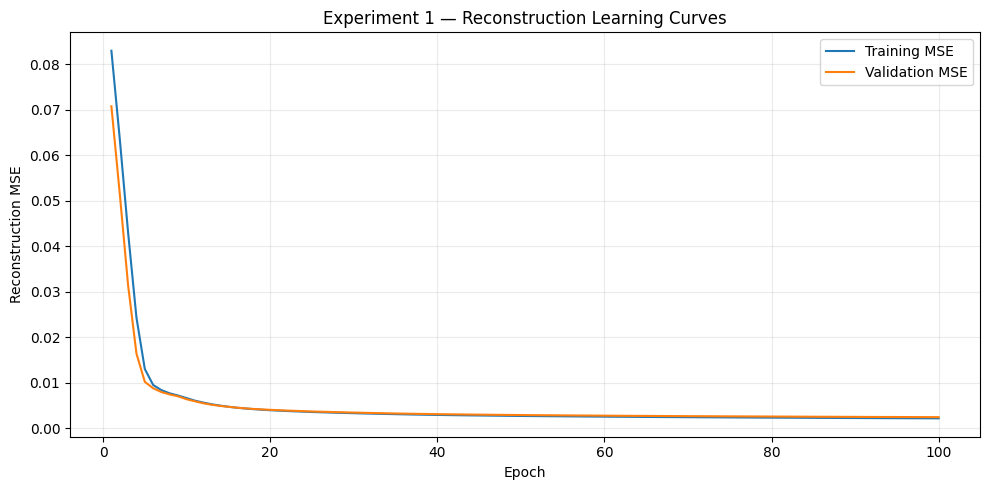

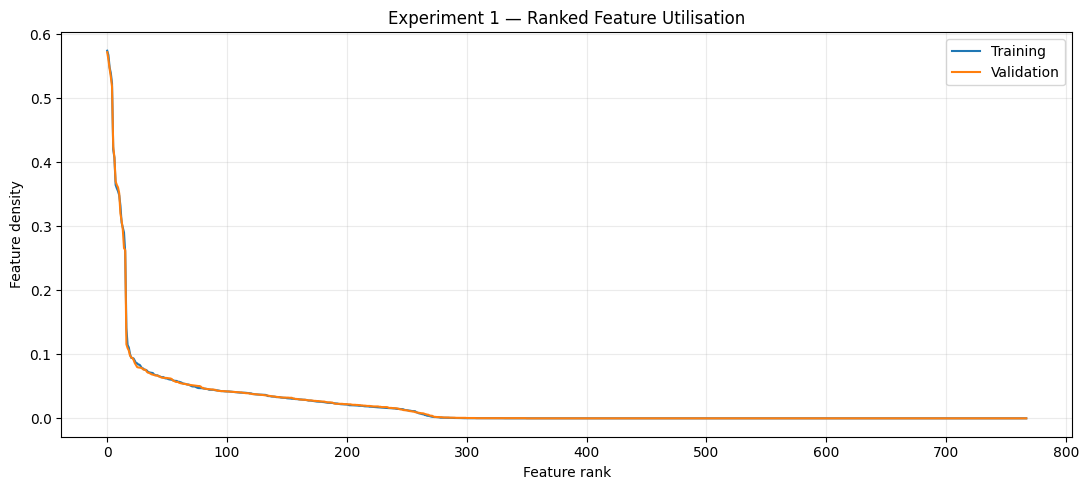

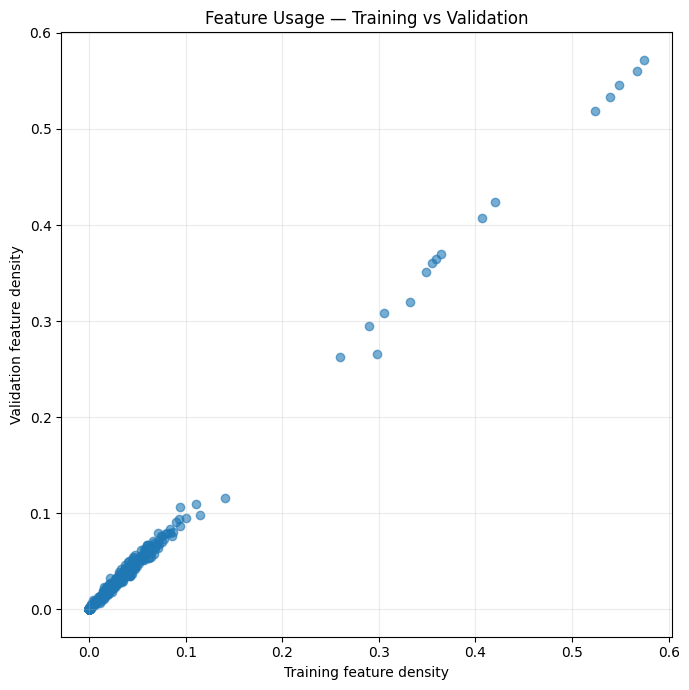


FEATURE UTILISATION AUDIT COMPLETE


In [ ]:
# ============================================================
# METAMER-SAE — EXPERIMENT 1 FEATURE UTILISATION AUDIT
# ============================================================

import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt

RUN_ID = "topk_2x_k16_seed42"

RUN_DIR = TRAINING_ROOT / RUN_ID

# ------------------------------------------------------------
# 1. LOAD SAVED METRICS
# ------------------------------------------------------------

history = pd.read_csv(
    RUN_DIR / "training_history.csv"
)

with open(RUN_DIR / "run_summary.json", "r") as f:
    summary = json.load(f)

with open(RUN_DIR / "run_config.json", "r") as f:
    run_config = json.load(f)

train_density = np.load(
    RUN_DIR / "train_feature_density.npy"
)

validation_density = np.load(
    RUN_DIR / "validation_feature_density.npy"
)

assert train_density.shape == (768,)
assert validation_density.shape == (768,)

# ------------------------------------------------------------
# 2. FEATURE USAGE COMPARISON
# ------------------------------------------------------------

train_used = train_density > 0
validation_used = validation_density > 0

shared = train_used & validation_used
train_only = train_used & ~validation_used
validation_only = ~train_used & validation_used
neither = ~train_used & ~validation_used

train_active_count = int(train_used.sum())
validation_active_count = int(validation_used.sum())

print("=" * 70)
print("METAMER-SAE — FEATURE UTILISATION AUDIT")
print("=" * 70)

print("\nFEATURE USAGE")
print("-" * 70)

print("Dictionary size:", len(train_density))

print("Training-active features:", train_active_count)
print("Validation-active features:", validation_active_count)

print("Active in both datasets:", int(shared.sum()))
print("Training only:", int(train_only.sum()))
print("Validation only:", int(validation_only.sum()))
print("Inactive in both:", int(neither.sum()))

print("\nVALIDATION-INACTIVE FEATURES")
print("-" * 70)

print(
    "Validation-inactive:",
    int((~validation_used).sum())
)

print(
    "Validation dead fraction:",
    f"{(~validation_used).mean():.2%}"
)

print("\nFEATURE DENSITY STATISTICS")
print("-" * 70)

for name, density in [
    ("Training", train_density),
    ("Validation", validation_density)
]:

    positive = density[density > 0]

    print(f"\n{name}")

    print("Mean density:", float(density.mean()))
    print("Median density:", float(np.median(density)))
    print("Positive-feature median:", float(np.median(positive)))
    print("Maximum density:", float(density.max()))

    print(
        "Features used in at least 1% of samples:",
        int((density >= 0.01).sum())
    )

    print(
        "Features used in at least 5% of samples:",
        int((density >= 0.05).sum())
    )

# ------------------------------------------------------------
# 3. CHECK DENSITY SUM
# ------------------------------------------------------------

print("\nSPARSITY CONSISTENCY")
print("-" * 70)

print("Sum of training feature densities:", train_density.sum())
print("Sum of validation feature densities:", validation_density.sum())

print("Expected mean L0:", 16)

# ------------------------------------------------------------
# 4. TOP 20 MOST USED VALIDATION FEATURES
# ------------------------------------------------------------

top_indices = np.argsort(
    validation_density
)[::-1][:20]

top_features = pd.DataFrame({
    "feature_index": top_indices,
    "training_density": train_density[top_indices],
    "validation_density": validation_density[top_indices]
})

print("\nTOP 20 VALIDATION FEATURES")
print("-" * 70)

display(top_features)

# ------------------------------------------------------------
# 5. TRAINING HISTORY AUDIT
# ------------------------------------------------------------

minimum_validation_index = history[
    "validation_mse"
].idxmin()

history_best = history.loc[minimum_validation_index]

print("\nTRAINING HISTORY")
print("-" * 70)

print("Epochs completed:", len(history))

print("Best history epoch:", int(history_best["epoch"]))

print("Summary best epoch:", summary["best_epoch"])

print("Minimum validation MSE:", history["validation_mse"].min())

print("Final training MSE:", history["train_mse"].iloc[-1])

print("Final validation MSE:", history["validation_mse"].iloc[-1])

print(
    "Validation loss still improving at final epoch:",
    history["validation_mse"].iloc[-1]
    < history["validation_mse"].iloc[-2]
)

if "is_best_checkpoint" in history.columns:

    print(
        "Checkpoint improvement epochs:",
        int(history["is_best_checkpoint"].sum())
    )

if "training_settings" in run_config:

    settings = run_config["training_settings"]

    print(
        "Configured min_delta:",
        settings.get("min_delta")
    )

    print(
        "Configured early stopping patience:",
        settings.get("early_stopping_patience")
    )

# ------------------------------------------------------------
# 6. SAVE FEATURE USAGE TABLE
# ------------------------------------------------------------

feature_audit = pd.DataFrame({

    "feature_index": np.arange(768),

    "training_density": train_density,

    "validation_density": validation_density,

    "training_active": train_used,

    "validation_active": validation_used,

    "active_in_both": shared,

    "active_training_only": train_only,

    "active_validation_only": validation_only

})

feature_audit.to_csv(
    RUN_DIR / "feature_usage_audit.csv",
    index=False
)

# ------------------------------------------------------------
# 7. PLOT TRAINING CURVES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    history["epoch"],
    history["train_mse"],
    label="Training MSE"
)

ax.plot(
    history["epoch"],
    history["validation_mse"],
    label="Validation MSE"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Reconstruction MSE")
ax.set_title("Experiment 1 — Reconstruction Learning Curves")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

fig.savefig(
    RUN_DIR / "experiment_1_learning_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. PLOT FEATURE USAGE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    np.sort(train_density)[::-1],
    label="Training"
)

ax.plot(
    np.sort(validation_density)[::-1],
    label="Validation"
)

ax.set_xlabel("Feature rank")
ax.set_ylabel("Feature density")
ax.set_title("Experiment 1 — Ranked Feature Utilisation")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

fig.savefig(
    RUN_DIR / "experiment_1_feature_utilisation.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. TRAINING VS VALIDATION DENSITY SCATTER
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    train_density,
    validation_density,
    alpha=0.6
)

ax.set_xlabel("Training feature density")
ax.set_ylabel("Validation feature density")

ax.set_title(
    "Feature Usage — Training vs Validation"
)

ax.grid(alpha=0.25)

plt.tight_layout()

fig.savefig(
    RUN_DIR / "experiment_1_feature_density_scatter.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 70)
print("FEATURE UTILISATION AUDIT COMPLETE")
print("=" * 70)

### Comprehensive visualisation suite

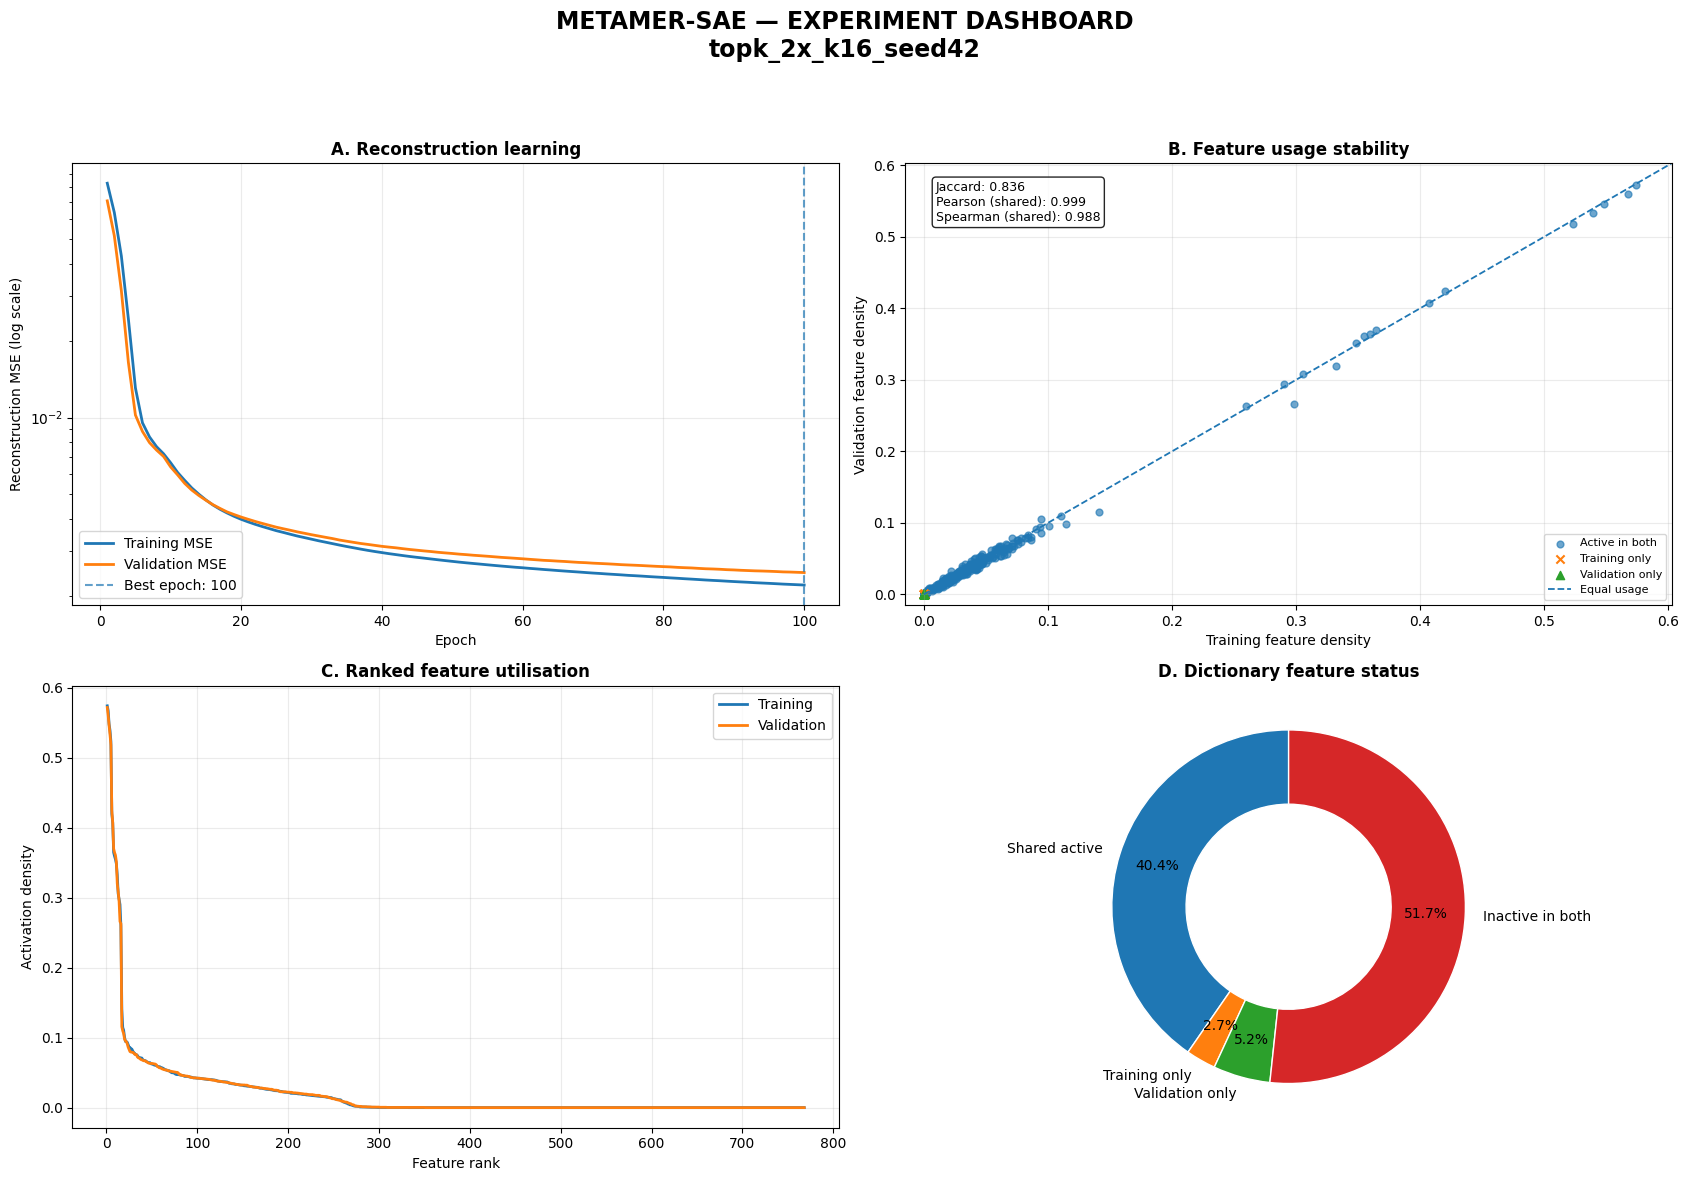

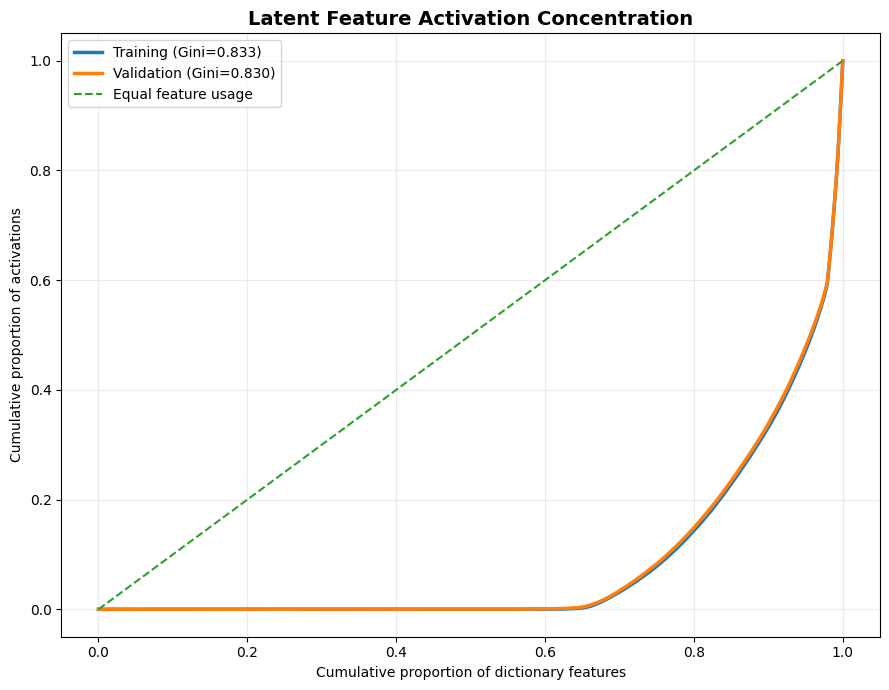

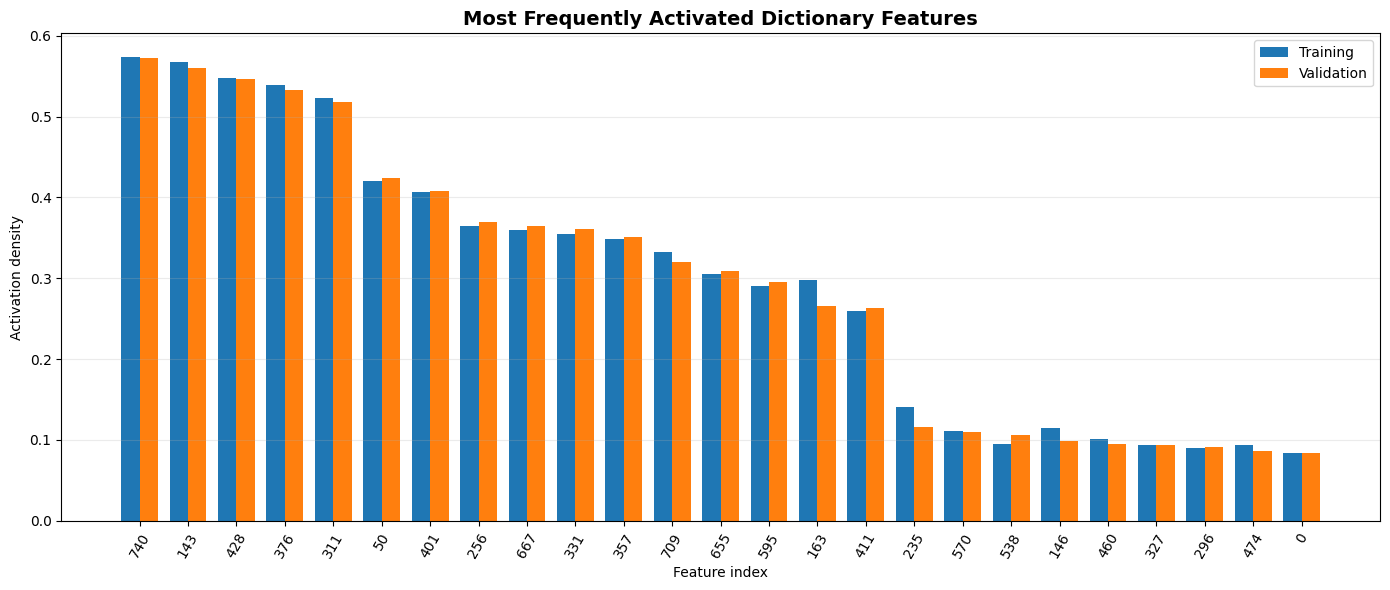

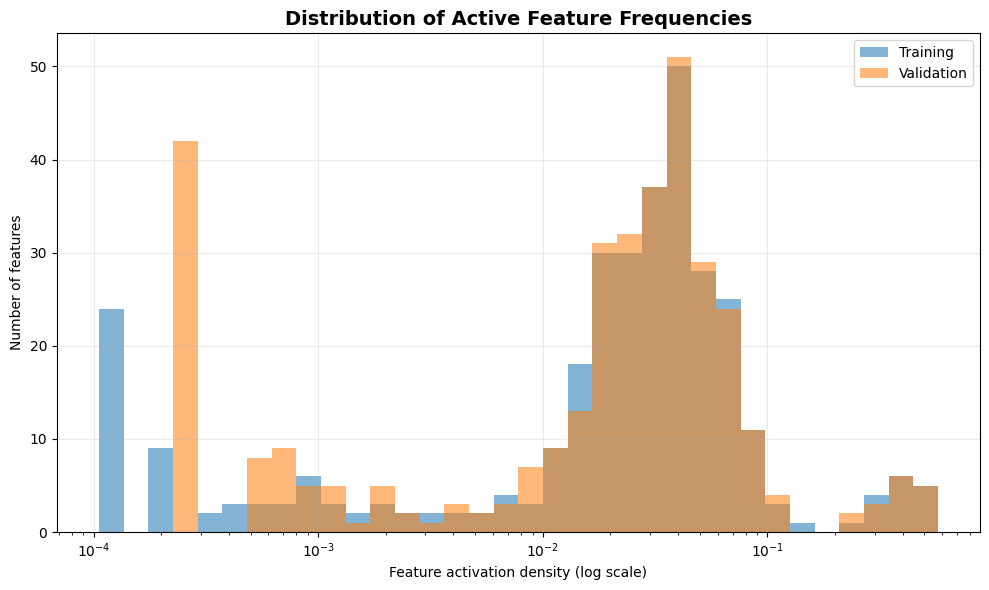


VISUALISATION SUITE COMPLETED: topk_2x_k16_seed42
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_2x_k16_seed42/figures
Support Jaccard: 0.8356
Top-20 activation share: 0.4307
Validation Gini: 0.8301

EXPERIMENT 1 VISUALISATION METRICS


,Value
run_id,topk_2x_k16_seed42
dictionary_size,768
training_active_features,331
validation_active_features,350
shared_active_features,310
inactive_in_both,397
support_jaccard,0.83558
support_dice,0.910426
pearson_correlation_shared_features,0.998738
spearman_correlation_shared_features,0.987538


In [ ]:
# ============================================================
# METAMER-SAE — COMPREHENSIVE SAE VISUALISATION SUITE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from pathlib import Path

# ============================================================
# 1. REUSABLE RUN VISUALISATION FUNCTION
# ============================================================

def generate_run_visualizations(run_id):

    run_dir = TRAINING_ROOT / run_id

    figure_dir = run_dir / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------------
    # LOAD RUN OUTPUTS
    # --------------------------------------------------------

    history = pd.read_csv(
        run_dir / "training_history.csv"
    )

    with open(run_dir / "run_summary.json") as f:
        summary = json.load(f)

    train_density = np.load(
        run_dir / "train_feature_density.npy"
    )

    validation_density = np.load(
        run_dir / "validation_feature_density.npy"
    )

    n_features = len(train_density)

    assert train_density.shape == validation_density.shape

    # --------------------------------------------------------
    # SUPPORT ANALYSIS
    # --------------------------------------------------------

    train_used = train_density > 0
    validation_used = validation_density > 0

    shared = train_used & validation_used
    train_only = train_used & ~validation_used
    validation_only = ~train_used & validation_used
    neither = ~train_used & ~validation_used

    union_count = int((train_used | validation_used).sum())

    shared_count = int(shared.sum())

    jaccard = shared_count / union_count if union_count else 0

    dice = (
        2 * shared_count /
        (train_used.sum() + validation_used.sum())
    )

    # Correlation among features active in both splits.
    pearson = np.corrcoef(
        train_density[shared],
        validation_density[shared]
    )[0, 1] if shared.sum() > 1 else np.nan

    spearman = pd.Series(
        train_density[shared]
    ).corr(
        pd.Series(validation_density[shared]),
        method="spearman"
    ) if shared.sum() > 1 else np.nan

    # --------------------------------------------------------
    # ACTIVATION CONCENTRATION
    # --------------------------------------------------------

    def top_feature_share(density, k):

        ranked = np.sort(density)[::-1]

        return float(
            ranked[:k].sum() / ranked.sum()
        )

    def gini_coefficient(values):

        values = np.sort(
            np.asarray(values, dtype=np.float64)
        )

        total = values.sum()

        if total == 0:
            return 0.0

        n = len(values)

        indices = np.arange(1, n + 1)

        return float(
            (2 * np.sum(indices * values) /
             (n * total)) - ((n + 1) / n)
        )

    top20_share = top_feature_share(validation_density, 20)
    top50_share = top_feature_share(validation_density, 50)

    train_gini = gini_coefficient(train_density)
    validation_gini = gini_coefficient(validation_density)

    # ========================================================
    # FIGURE 1 — FOUR-PANEL RUN DASHBOARD
    # ========================================================

    fig, axes = plt.subplots(
        2, 2,
        figsize=(17, 12)
    )

    fig.suptitle(
        f"METAMER-SAE — EXPERIMENT DASHBOARD\n{run_id}",
        fontsize=17,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # PANEL A — LEARNING CURVES
    # --------------------------------------------------------

    ax = axes[0, 0]

    ax.semilogy(
        history["epoch"],
        history["train_mse"],
        label="Training MSE",
        linewidth=2
    )

    ax.semilogy(
        history["epoch"],
        history["validation_mse"],
        label="Validation MSE",
        linewidth=2
    )

    best_epoch = int(summary["best_epoch"])

    ax.axvline(
        best_epoch,
        linestyle="--",
        alpha=0.7,
        label=f"Best epoch: {best_epoch}"
    )

    ax.set_title(
        "A. Reconstruction learning",
        fontweight="bold"
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Reconstruction MSE (log scale)")
    ax.legend()
    ax.grid(alpha=0.25)

    # --------------------------------------------------------
    # PANEL B — FEATURE STABILITY
    # --------------------------------------------------------

    ax = axes[0, 1]

    ax.scatter(
        train_density[shared],
        validation_density[shared],
        s=24,
        alpha=0.65,
        label="Active in both"
    )

    ax.scatter(
        train_density[train_only],
        np.zeros(train_only.sum()),
        marker="x",
        s=35,
        label="Training only"
    )

    ax.scatter(
        np.zeros(validation_only.sum()),
        validation_density[validation_only],
        marker="^",
        s=35,
        label="Validation only"
    )

    maximum = max(
        train_density.max(),
        validation_density.max()
    ) * 1.05

    ax.plot(
        [0, maximum],
        [0, maximum],
        "--",
        linewidth=1.3,
        label="Equal usage"
    )

    ax.set_xlim(-0.015, maximum)
    ax.set_ylim(-0.015, maximum)

    ax.set_title(
        "B. Feature usage stability",
        fontweight="bold"
    )

    ax.set_xlabel("Training feature density")
    ax.set_ylabel("Validation feature density")

    ax.text(
        0.04, 0.96,
        f"Jaccard: {jaccard:.3f}\n"
        f"Pearson (shared): {pearson:.3f}\n"
        f"Spearman (shared): {spearman:.3f}",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            alpha=0.85
        )
    )

    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

    # --------------------------------------------------------
    # PANEL C — RANKED FEATURE UTILISATION
    # --------------------------------------------------------

    ax = axes[1, 0]

    train_sorted = np.sort(train_density)[::-1]
    val_sorted = np.sort(validation_density)[::-1]

    rank = np.arange(1, n_features + 1)

    ax.plot(
        rank,
        train_sorted,
        label="Training",
        linewidth=2
    )

    ax.plot(
        rank,
        val_sorted,
        label="Validation",
        linewidth=2
    )

    ax.set_title(
        "C. Ranked feature utilisation",
        fontweight="bold"
    )

    ax.set_xlabel("Feature rank")
    ax.set_ylabel("Activation density")

    ax.legend()
    ax.grid(alpha=0.25)

    # --------------------------------------------------------
    # PANEL D — FEATURE SUPPORT COMPOSITION
    # --------------------------------------------------------

    ax = axes[1, 1]

    support_labels = [
        "Shared active",
        "Training only",
        "Validation only",
        "Inactive in both"
    ]

    support_values = [
        int(shared.sum()),
        int(train_only.sum()),
        int(validation_only.sum()),
        int(neither.sum())
    ]

    wedges, texts, autotexts = ax.pie(
        support_values,
        labels=support_labels,
        autopct="%1.1f%%",
        startangle=90,
        pctdistance=0.78,
        wedgeprops=dict(
            width=0.42,
            edgecolor="white"
        )
    )

    ax.set_title(
        "D. Dictionary feature status",
        fontweight="bold"
    )

    fig.tight_layout(rect=[0, 0, 1, 0.94])

    fig.savefig(
        figure_dir / "01_experiment_dashboard.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    # ========================================================
    # FIGURE 2 — ACTIVATION CONCENTRATION / LORENZ CURVE
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(9, 7)
    )

    for density, label in [
        (train_density, "Training"),
        (validation_density, "Validation")
    ]:

        ascending = np.sort(density)

        cumulative = (
            np.concatenate([[0], np.cumsum(ascending)])
            / density.sum()
        )

        population = np.linspace(
            0, 1, len(cumulative)
        )

        ax.plot(
            population,
            cumulative,
            linewidth=2.5,
            label=f"{label} (Gini={gini_coefficient(density):.3f})"
        )

    ax.plot(
        [0, 1],
        [0, 1],
        "--",
        label="Equal feature usage"
    )

    ax.set_title(
        "Latent Feature Activation Concentration",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Cumulative proportion of dictionary features")
    ax.set_ylabel("Cumulative proportion of activations")

    ax.legend()
    ax.grid(alpha=0.25)

    fig.tight_layout()

    fig.savefig(
        figure_dir / "02_activation_concentration.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    # ========================================================
    # FIGURE 3 — TOP 25 FEATURES
    # ========================================================

    top_indices = np.argsort(
        validation_density
    )[::-1][:25]

    x = np.arange(len(top_indices))

    width = 0.38

    fig, ax = plt.subplots(
        figsize=(14, 6)
    )

    ax.bar(
        x - width / 2,
        train_density[top_indices],
        width,
        label="Training"
    )

    ax.bar(
        x + width / 2,
        validation_density[top_indices],
        width,
        label="Validation"
    )

    ax.set_title(
        "Most Frequently Activated Dictionary Features",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Feature index")
    ax.set_ylabel("Activation density")

    ax.set_xticks(x)
    ax.set_xticklabels(
        top_indices,
        rotation=60
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()

    fig.savefig(
        figure_dir / "03_top25_feature_usage.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    # ========================================================
    # FIGURE 4 — POSITIVE FEATURE DENSITY DISTRIBUTION
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    train_positive = train_density[train_density > 0]

    val_positive = validation_density[
        validation_density > 0
    ]

    lower = min(
        train_positive.min(),
        val_positive.min()
    )

    upper = max(
        train_positive.max(),
        val_positive.max()
    )

    bins = np.geomspace(
        lower,
        upper * 1.001,
        35
    )

    ax.hist(
        train_positive,
        bins=bins,
        alpha=0.55,
        label="Training"
    )

    ax.hist(
        val_positive,
        bins=bins,
        alpha=0.55,
        label="Validation"
    )

    ax.set_xscale("log")

    ax.set_title(
        "Distribution of Active Feature Frequencies",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Feature activation density (log scale)")
    ax.set_ylabel("Number of features")

    ax.legend()
    ax.grid(alpha=0.25)

    fig.tight_layout()

    fig.savefig(
        figure_dir / "04_feature_density_distribution.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    # ========================================================
    # SAVE NUMERICAL VISUALISATION REPORT
    # ========================================================

    metrics = {

        "run_id": run_id,

        "dictionary_size": n_features,

        "training_active_features": int(train_used.sum()),

        "validation_active_features": int(validation_used.sum()),

        "shared_active_features": int(shared.sum()),

        "inactive_in_both": int(neither.sum()),

        "support_jaccard": jaccard,

        "support_dice": dice,

        "pearson_correlation_shared_features": float(pearson),

        "spearman_correlation_shared_features": float(spearman),

        "top20_validation_activation_share": top20_share,

        "top50_validation_activation_share": top50_share,

        "training_gini": train_gini,

        "validation_gini": validation_gini,

        "best_validation_mse": summary["best_validation_mse"],

        "best_epoch": best_epoch
    }

    with open(
        figure_dir / "visualization_metrics.json",
        "w"
    ) as f:

        json.dump(metrics, f, indent=4)

    # Save top-feature table.

    top_table = pd.DataFrame({

        "feature_index": top_indices,

        "training_density": train_density[top_indices],

        "validation_density": validation_density[top_indices]

    })

    top_table.to_csv(
        figure_dir / "top25_feature_table.csv",
        index=False
    )

    print("\n" + "=" * 70)

    print("VISUALISATION SUITE COMPLETED:", run_id)

    print("=" * 70)

    print("Figures saved:", figure_dir)

    print("Support Jaccard:", round(jaccard, 4))

    print("Top-20 activation share:", round(top20_share, 4))

    print("Validation Gini:", round(validation_gini, 4))

    return metrics


# ============================================================
# 2. GENERATE VISUALISATIONS FOR EXPERIMENT 1
# ============================================================

experiment_1_visual_metrics = generate_run_visualizations(
    "topk_2x_k16_seed42"
)

print("\nEXPERIMENT 1 VISUALISATION METRICS")

display(
    pd.DataFrame([
        experiment_1_visual_metrics
    ]).T.rename(columns={0: "Value"})
)


### Display the remaining training runs

In [ ]:
# ============================================================
# METAMER-SAE — REMAINING EXPERIMENT SCHEDULE
# ============================================================

# Reload the original experiment configuration.

with open(EXPERIMENT_CONFIG_PATH, "r") as f:
    experiment_config = json.load(f)

EXPERIMENT_GRID = experiment_config["experiment_grid"]

print("=" * 75)
print("METAMER-SAE — EXPERIMENT SCHEDULE")
print("=" * 75)

for index, experiment in enumerate(EXPERIMENT_GRID):

    expansion = experiment["expansion_factor"]
    k = experiment["top_k"]
    seed = experiment["random_seed"]

    run_id = f"topk_{expansion}x_k{k}_seed{seed}"

    summary_path = (
        TRAINING_ROOT / run_id / "run_summary.json"
    )

    completed = False

    if summary_path.exists():

        with open(summary_path, "r") as f:
            saved_summary = json.load(f)

        completed = saved_summary.get("status") == "completed"

    print(
        f"\nExperiment {index + 1}: "
        f"{expansion}x | "
        f"Dictionary={experiment['nb_concepts']} | "
        f"TopK={k} | "
        f"Seed={seed}"
    )

    print("Status:", "COMPLETED" if completed else "PENDING")

print("\n" + "=" * 75)

METAMER-SAE — EXPERIMENT SCHEDULE

Experiment 1: 2x | Dictionary=768 | TopK=16 | Seed=42
Status: COMPLETED

Experiment 2: 2x | Dictionary=768 | TopK=16 | Seed=123
Status: COMPLETED

Experiment 3: 2x | Dictionary=768 | TopK=32 | Seed=42
Status: COMPLETED

Experiment 4: 2x | Dictionary=768 | TopK=32 | Seed=123
Status: PENDING

Experiment 5: 4x | Dictionary=1536 | TopK=32 | Seed=42
Status: PENDING

Experiment 6: 4x | Dictionary=1536 | TopK=32 | Seed=123
Status: PENDING

Experiment 7: 4x | Dictionary=1536 | TopK=64 | Seed=42
Status: PENDING

Experiment 8: 4x | Dictionary=1536 | TopK=64 | Seed=123
Status: PENDING



### Execute the second training run

METAMER-SAE — EXPERIMENT 2

Selected configuration:
{
    "input_dimensions": 384,
    "expansion_factor": 2,
    "nb_concepts": 768,
    "top_k": 16,
    "active_fraction": 0.020833333333333332,
    "random_seed": 123
}
Already completed: topk_2x_k16_seed123


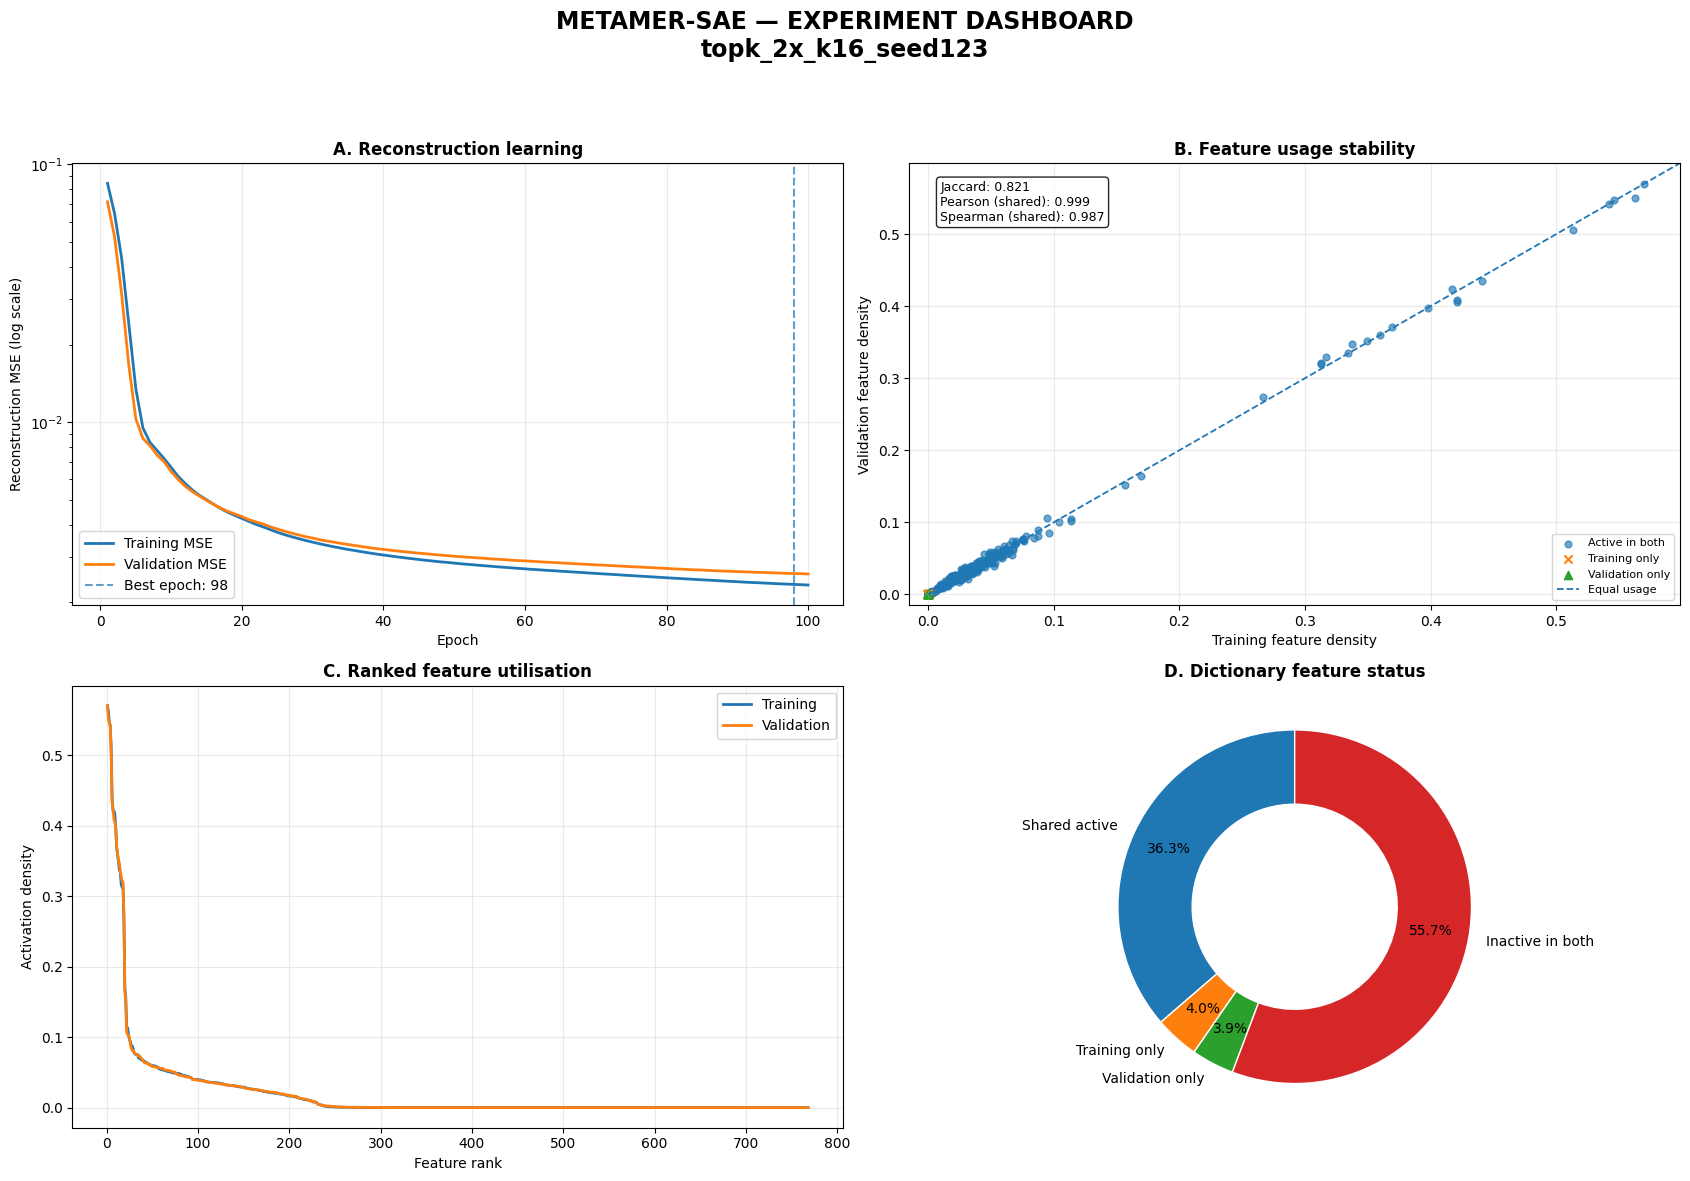

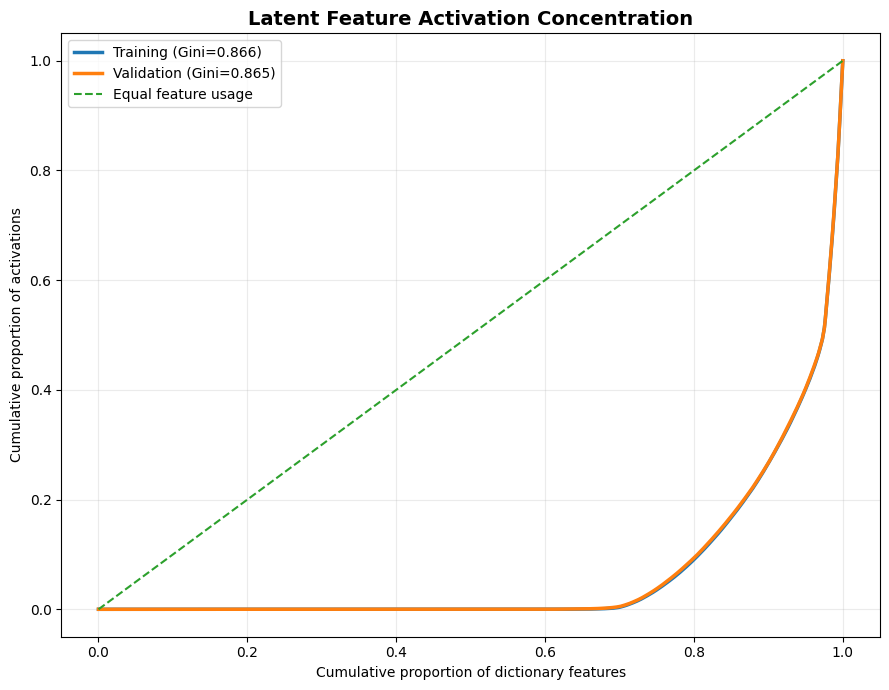

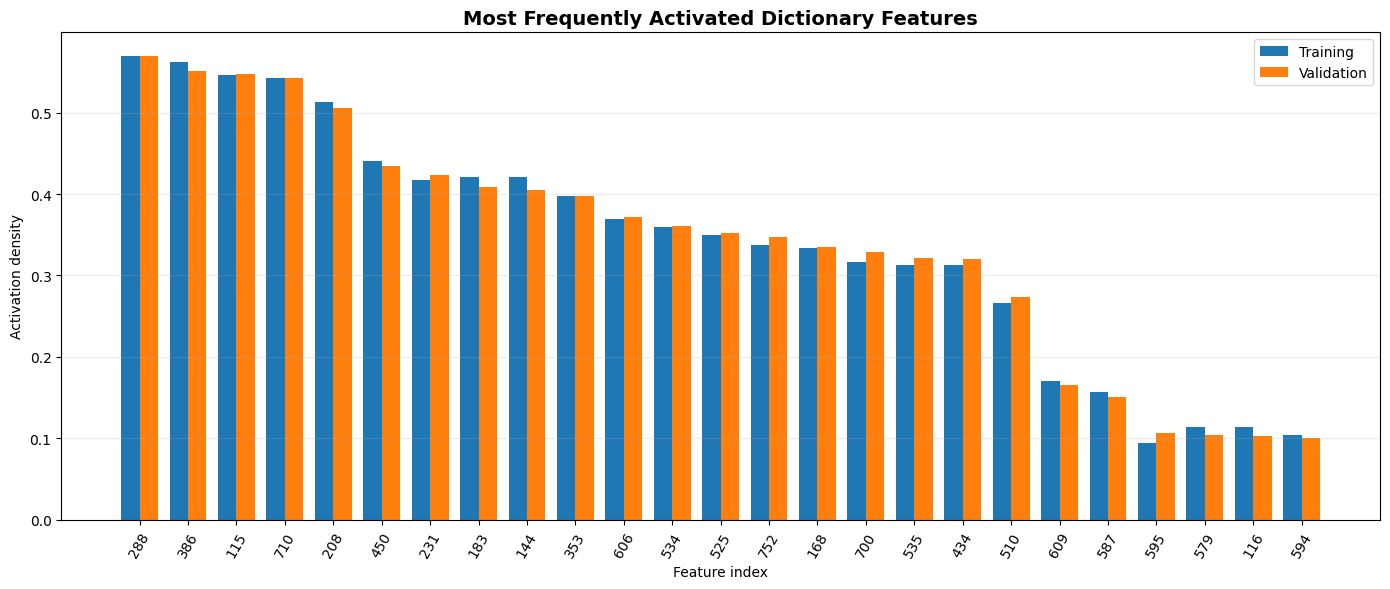

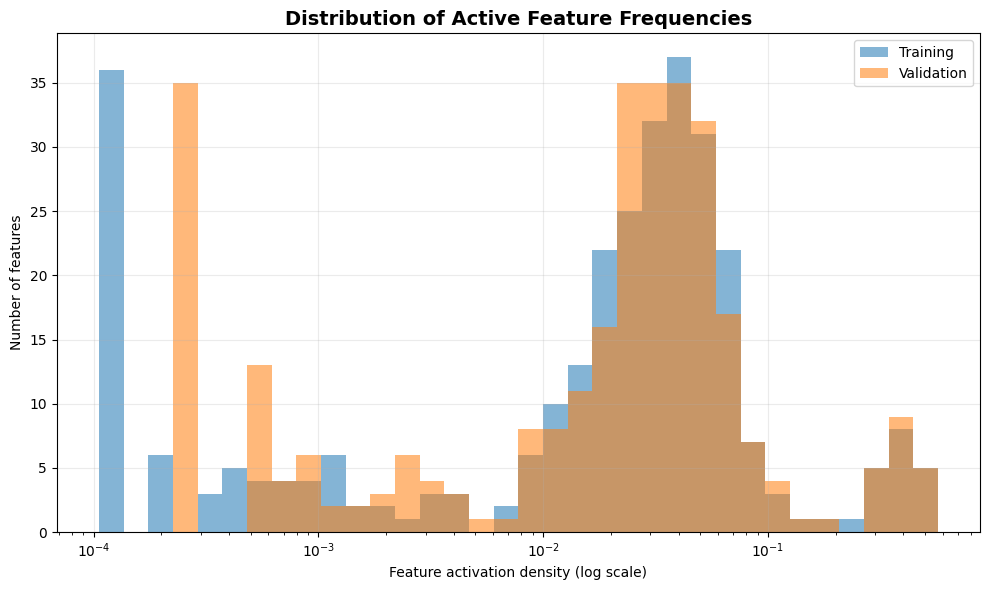


VISUALISATION SUITE COMPLETED: topk_2x_k16_seed123
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_2x_k16_seed123/figures
Support Jaccard: 0.8206
Top-20 activation share: 0.4975
Validation Gini: 0.865

EXPERIMENT 2 SUMMARY


,Value
status,completed
run_id,topk_2x_k16_seed123
expansion_factor,2
dictionary_size,768
top_k,16
seed,123
best_epoch,98
epochs_completed,100
best_validation_mse,0.002586
validation_zero_baseline_mse,0.090971



EXPERIMENT 2 VISUALISATION METRICS


,Value
run_id,topk_2x_k16_seed123
dictionary_size,768
training_active_features,310
validation_active_features,309
shared_active_features,279
inactive_in_both,428
support_jaccard,0.820588
support_dice,0.901454
pearson_correlation_shared_features,0.999096
spearman_correlation_shared_features,0.986674


In [ ]:
# ============================================================
# METAMER-SAE — EXPERIMENT 2
# ============================================================

NEXT_EXPERIMENT_INDEX = 1

experiment_2 = EXPERIMENT_GRID[
    NEXT_EXPERIMENT_INDEX
]

print("=" * 70)
print("METAMER-SAE — EXPERIMENT 2")
print("=" * 70)

print("\nSelected configuration:")

print(json.dumps(
    experiment_2,
    indent=4
))

# Train the second SAE.

experiment_2_summary = train_topk_experiment(
    experiment_2
)

# Generate the same visualisations used for Experiment 1.

experiment_2_visual_metrics = generate_run_visualizations(
    experiment_2_summary["run_id"]
)

print("\nEXPERIMENT 2 SUMMARY")

display(
    pd.DataFrame([
        experiment_2_summary
    ]).T.rename(columns={0: "Value"})
)

print("\nEXPERIMENT 2 VISUALISATION METRICS")

display(
    pd.DataFrame([
        experiment_2_visual_metrics
    ]).T.rename(columns={0: "Value"})
)

In [ ]:
# ============================================================
# EXPERIMENT 2 — CHECKPOINT CONSISTENCY AUDIT
# ============================================================

run_dir = TRAINING_ROOT / "topk_2x_k16_seed123"

history = pd.read_csv(
    run_dir / "training_history.csv"
)

with open(run_dir / "run_summary.json") as f:
    summary = json.load(f)

raw_best_idx = history["validation_mse"].idxmin()

raw_best = history.loc[raw_best_idx]

print("=" * 70)
print("EXPERIMENT 2 — CHECKPOINT AUDIT")
print("=" * 70)

print("\nLAST FIVE EPOCHS")
display(
    history.tail(5)[
        ["epoch", "validation_mse", "is_best_checkpoint"]
    ]
)

print("\nRECORDED CHECKPOINT")
print("Epoch:", summary["best_epoch"])
print("Validation MSE:", summary["best_validation_mse"])

print("\nABSOLUTE MINIMUM IN TRAINING HISTORY")
print("Epoch:", int(raw_best["epoch"]))
print("Validation MSE:", float(raw_best["validation_mse"]))

print("\nCHECKPOINT AND RAW MINIMUM MATCH:",
      int(raw_best["epoch"]) == summary["best_epoch"])

print("=" * 70)

EXPERIMENT 2 — CHECKPOINT AUDIT

LAST FIVE EPOCHS


,epoch,validation_mse,is_best_checkpoint
95,96,0.002597,True
96,97,0.002591,False
97,98,0.002585,True
98,99,0.002581,False
99,100,0.002575,False



RECORDED CHECKPOINT
Epoch: 98
Validation MSE: 0.0025863025508892196

ABSOLUTE MINIMUM IN TRAINING HISTORY
Epoch: 100
Validation MSE: 0.0025751567353749

CHECKPOINT AND RAW MINIMUM MATCH: False


EXPERIMENT 3 CONFIGURATION
{
    "input_dimensions": 384,
    "expansion_factor": 2,
    "nb_concepts": 768,
    "top_k": 32,
    "active_fraction": 0.041666666666666664,
    "random_seed": 42
}
Already completed: topk_2x_k32_seed42


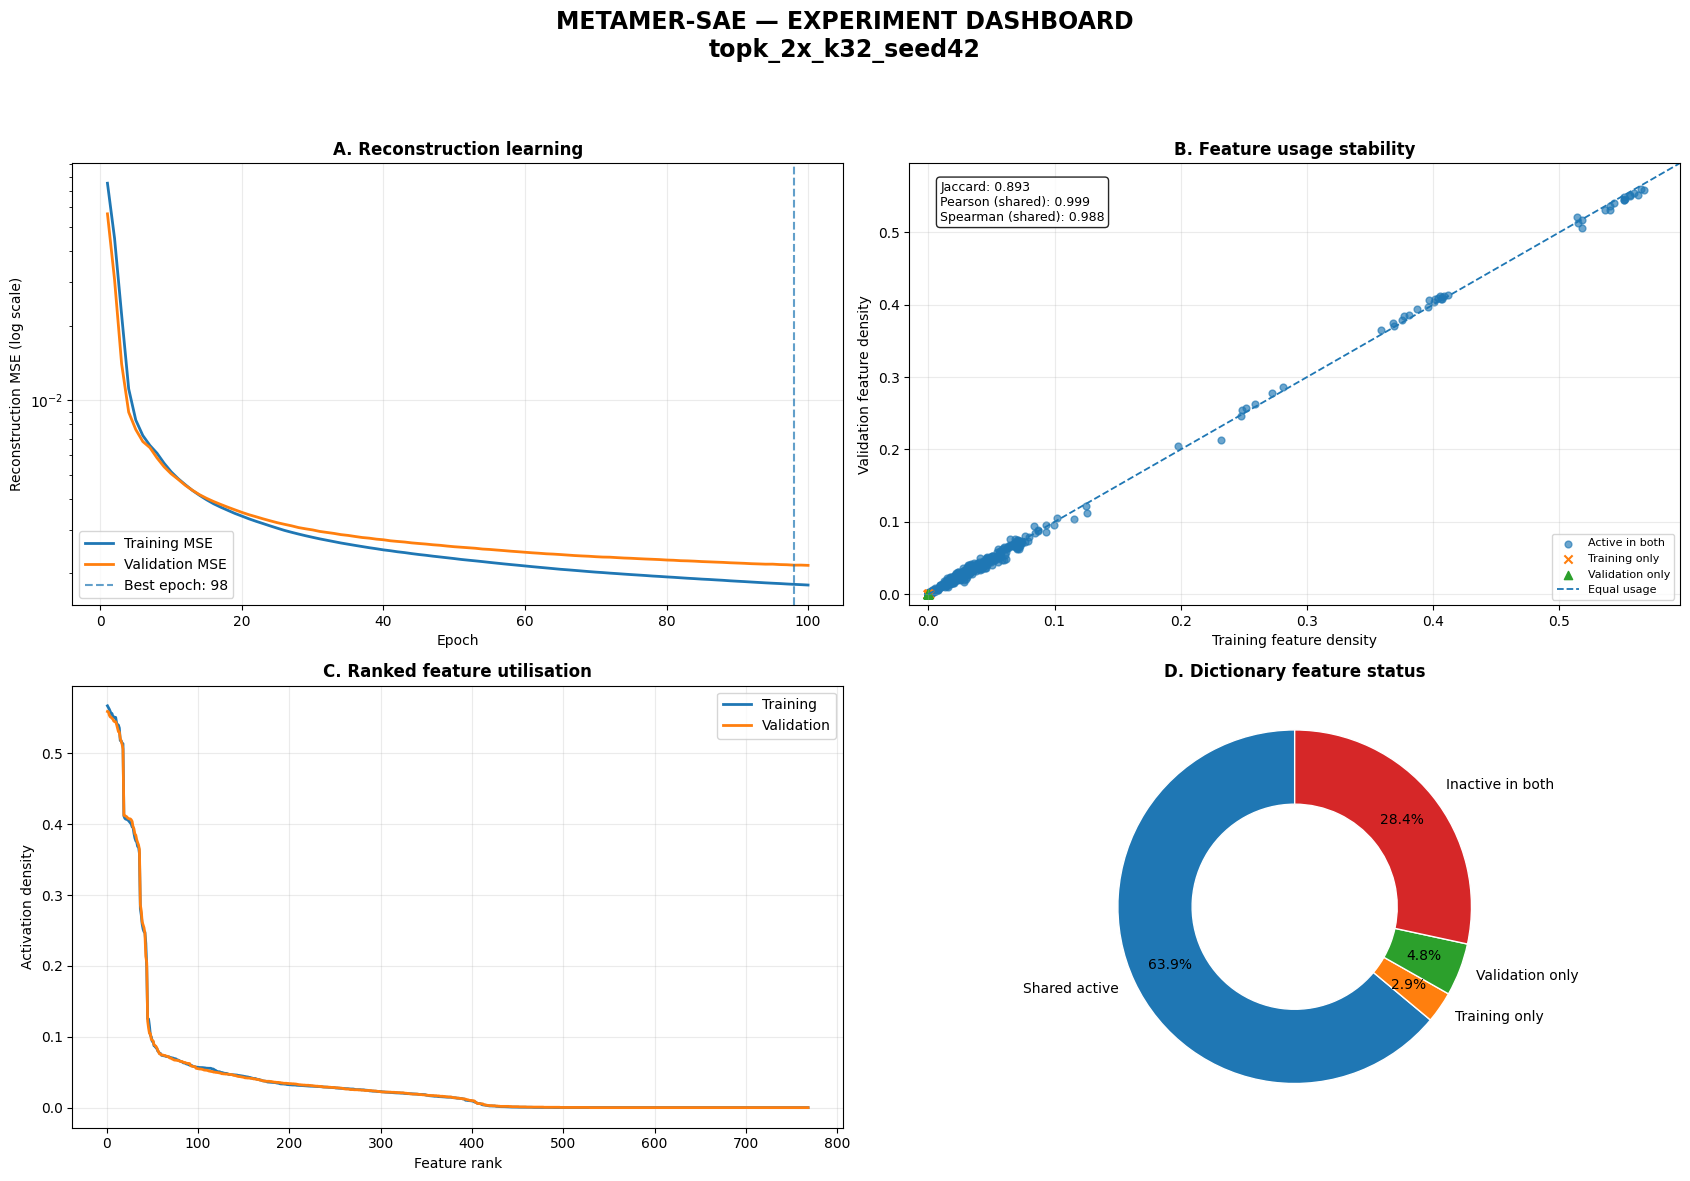

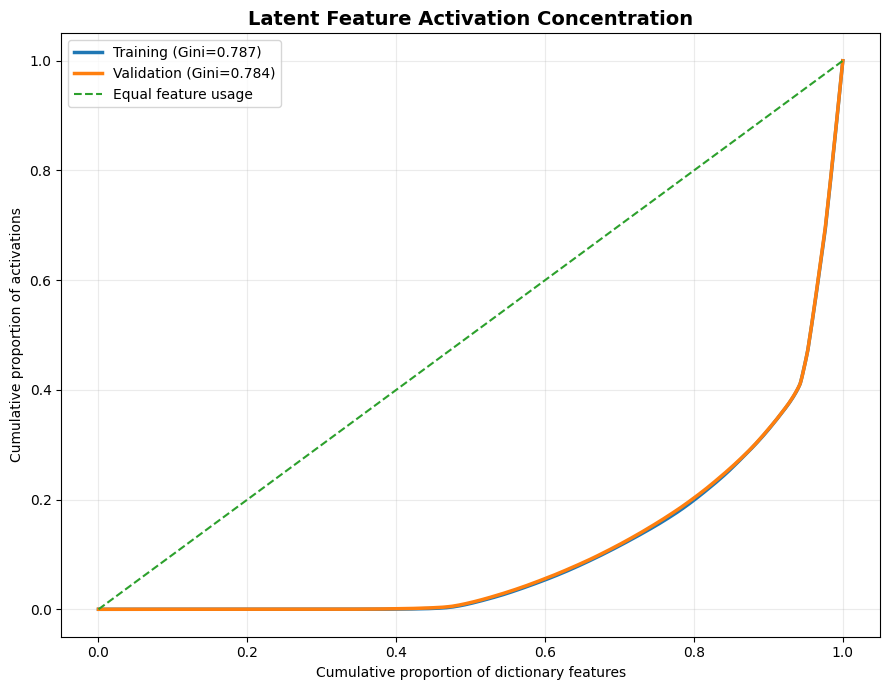

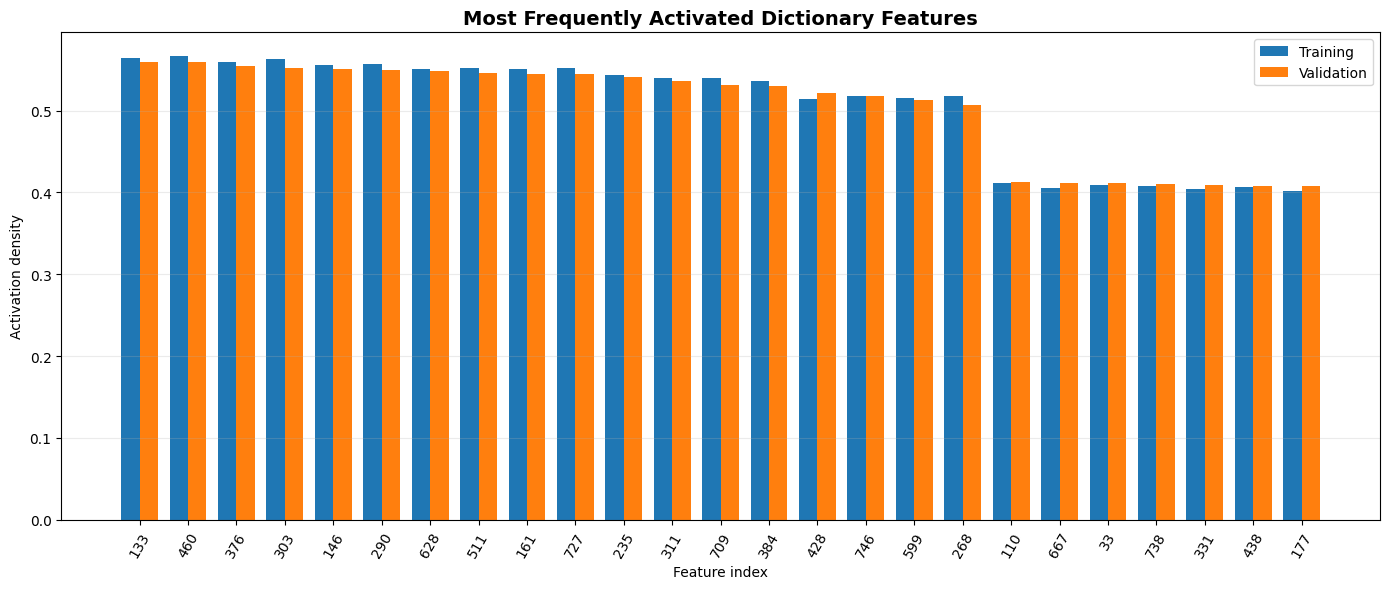

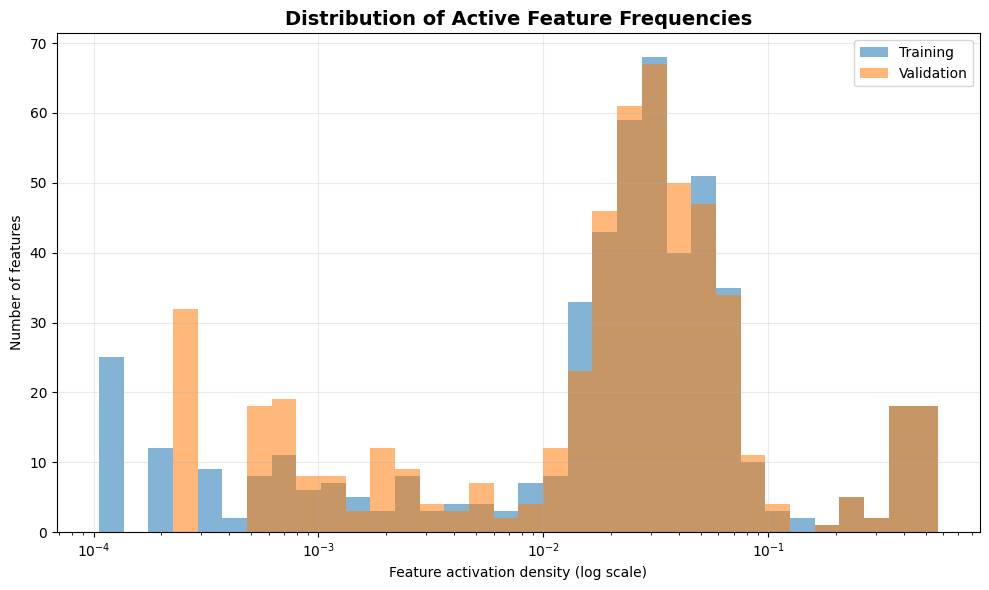


VISUALISATION SUITE COMPLETED: topk_2x_k32_seed42
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_2x_k32_seed42/figures
Support Jaccard: 0.8927
Top-20 activation share: 0.329
Validation Gini: 0.7844


,Value
status,completed
run_id,topk_2x_k32_seed42
expansion_factor,2
dictionary_size,768
top_k,32
seed,42
best_epoch,98
epochs_completed,100
best_validation_mse,0.00216
validation_zero_baseline_mse,0.090971


,Value
run_id,topk_2x_k32_seed42
dictionary_size,768
training_active_features,513
validation_active_features,528
shared_active_features,491
inactive_in_both,218
support_jaccard,0.892727
support_dice,0.943324
pearson_correlation_shared_features,0.999484
spearman_correlation_shared_features,0.987926


In [ ]:
# ============================================================
# METAMER-SAE — EXPERIMENT 3
# ============================================================

experiment_3 = EXPERIMENT_GRID[2]

print("EXPERIMENT 3 CONFIGURATION")
print(json.dumps(experiment_3, indent=4))

experiment_3_summary = train_topk_experiment(
    experiment_3
)

experiment_3_visual_metrics = generate_run_visualizations(
    experiment_3_summary["run_id"]
)

display(pd.DataFrame([
    experiment_3_summary
]).T.rename(columns={0: "Value"}))

display(pd.DataFrame([
    experiment_3_visual_metrics
]).T.rename(columns={0: "Value"}))

### Fresh checkpoint verification

In [ ]:
# ============================================================
# METAMER-SAE — FRESH CHECKPOINT VERIFICATION
# ============================================================

RUN_IDS = [
    "topk_2x_k16_seed42",
    "topk_2x_k16_seed123",
    "topk_2x_k32_seed42"
]

checkpoint_audit_results = []

print("=" * 75)
print("METAMER-SAE — FRESH CHECKPOINT AUDIT")
print("=" * 75)

for run_id in RUN_IDS:

    run_dir = TRAINING_ROOT / run_id

    checkpoint_path = run_dir / "best_model.pt"

    summary_path = run_dir / "run_summary.json"

    history_path = run_dir / "training_history.csv"

    assert checkpoint_path.exists()
    assert summary_path.exists()
    assert history_path.exists()

    # --------------------------------------------------------
    # Load saved records
    # --------------------------------------------------------

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    with open(summary_path) as f:
        summary = json.load(f)

    history = pd.read_csv(history_path)

    config = checkpoint["run_config"]

    # --------------------------------------------------------
    # Build a fresh model
    # --------------------------------------------------------

    model = build_topk_sae(
        nb_concepts=config["dictionary_size"],
        top_k=config["top_k"],
        seed=config["random_seed"]
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    # Explicitly rebuild the fused dictionary.
    # Important for Overcomplete's DictionaryLayer.

    model.train()
    model.eval()

    train_loader, validation_loader = create_dataloaders(
        config["random_seed"]
    )

    # --------------------------------------------------------
    # Evaluate the actual saved checkpoint
    # --------------------------------------------------------

    train_stats = evaluate_sae(
        model,
        train_loader,
        config["dictionary_size"]
    )

    validation_stats = evaluate_sae(
        model,
        validation_loader,
        config["dictionary_size"]
    )

    # --------------------------------------------------------
    # Compare against recorded history
    # --------------------------------------------------------

    raw_best_idx = history["validation_mse"].idxmin()

    raw_best = history.loc[raw_best_idx]

    result = {

        "run_id": run_id,

        "checkpoint_epoch": checkpoint["best_epoch"],

        "recorded_checkpoint_mse": (
            checkpoint["best_validation_mse"]
        ),

        "fresh_checkpoint_train_mse": train_stats["mse"],

        "fresh_checkpoint_validation_mse": (
            validation_stats["mse"]
        ),

        "raw_history_best_epoch": int(raw_best["epoch"]),

        "raw_history_best_mse": float(
            raw_best["validation_mse"]
        ),

        "checkpoint_vs_summary_difference": abs(
            validation_stats["mse"]
            - summary["best_validation_mse"]
        ),

        "validation_active_features": (
            validation_stats["active_features"]
        ),

        "validation_dead_fraction": (
            validation_stats["dead_feature_fraction"]
        ),

        "checkpoint_freshly_loaded": True
    }

    checkpoint_audit_results.append(result)

    print("\n" + "-" * 75)

    print(run_id)

    print("Checkpoint epoch:", result["checkpoint_epoch"])

    print("Fresh checkpoint validation MSE:",
          result["fresh_checkpoint_validation_mse"])

    print("Raw history best epoch:",
          result["raw_history_best_epoch"])

    print("Raw history minimum:",
          result["raw_history_best_mse"])

    print("Active features:",
          result["validation_active_features"])

    print("Dead feature fraction:",
          f"{result['validation_dead_fraction']:.2%}")

    del model, checkpoint

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# Save separate audit report
# ------------------------------------------------------------

audit_df = pd.DataFrame(
    checkpoint_audit_results
)

audit_path = (
    TRAINING_ROOT / "checkpoint_verification_audit.csv"
)

audit_df.to_csv(
    audit_path,
    index=False
)

print("\n" + "=" * 75)
print("CHECKPOINT AUDIT COMPLETE")
print("=" * 75)

display(audit_df)

print("Saved audit:", audit_path)

METAMER-SAE — FRESH CHECKPOINT AUDIT

---------------------------------------------------------------------------
topk_2x_k16_seed42
Checkpoint epoch: 100
Fresh checkpoint validation MSE: 0.002464380887912432
Raw history best epoch: 100
Raw history minimum: 0.0024643808879124
Active features: 350
Dead feature fraction: 54.43%

---------------------------------------------------------------------------
topk_2x_k16_seed123
Checkpoint epoch: 98
Fresh checkpoint validation MSE: 0.0025848436043568097
Raw history best epoch: 100
Raw history minimum: 0.0025751567353749
Active features: 309
Dead feature fraction: 59.77%

---------------------------------------------------------------------------
topk_2x_k32_seed42
Checkpoint epoch: 98
Fresh checkpoint validation MSE: 0.0021595333425541686
Raw history best epoch: 100
Raw history minimum: 0.0021554245015867
Active features: 528
Dead feature fraction: 31.25%

CHECKPOINT AUDIT COMPLETE


,run_id,checkpoint_epoch,recorded_checkpoint_mse,fresh_checkpoint_train_mse,fresh_checkpoint_validation_mse,raw_history_best_epoch,raw_history_best_mse,checkpoint_vs_summary_difference,validation_active_features,validation_dead_fraction,checkpoint_freshly_loaded
0,topk_2x_k16_seed42,100,0.002464,0.002183,0.002464,100,0.002464,0.000000e+00,350,0.544271,True
1,topk_2x_k16_seed123,98,0.002585,0.002327,0.002585,100,0.002575,1.458947e-06,309,0.597656,True
2,topk_2x_k32_seed42,98,0.002160,0.001785,0.002160,100,0.002155,2.735425e-07,528,0.312500,True


Saved audit: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/checkpoint_verification_audit.csv


### Replace the training function

In [ ]:
# ============================================================
# METAMER-SAE — CORRECTED TOPK SAE TRAINING ENGINE
# ============================================================

import os
import gc
import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from datetime import datetime, timezone

# ============================================================
# JSON SERIALIZATION SAFETY
# ============================================================

# PyTorch devices must be converted to strings for JSON.

DEVICE = str(DEVICE)

if "device" in TRAINING_SETTINGS:
    TRAINING_SETTINGS["device"] = str(
        TRAINING_SETTINGS["device"]
    )


def make_json_safe(value):

    if isinstance(value, torch.device):
        return str(value)

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, torch.dtype):
        return str(value)

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, dict):
        return {
            str(key): make_json_safe(val)
            for key, val in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            make_json_safe(item)
            for item in value
        ]

    if value is None or isinstance(
        value, (str, int, float, bool)
    ):
        return value

    raise TypeError(
        f"Unsupported JSON value: {type(value).__name__}"
    )


print("JSON serialization helper ready.")
print("Training device:", DEVICE)
print("Configuration device:", TRAINING_SETTINGS.get("device"))

# ============================================================
# TRAINING FUNCTION
# ============================================================

def train_topk_experiment(experiment):

    # --------------------------------------------------------
    # 1. EXPERIMENT CONFIGURATION
    # --------------------------------------------------------

    expansion = experiment["expansion_factor"]
    nb_concepts = experiment["nb_concepts"]
    top_k = experiment["top_k"]
    seed = experiment["random_seed"]

    run_id = f"topk_{expansion}x_k{top_k}_seed{seed}"

    run_dir = TRAINING_ROOT / run_id

    history_path = run_dir / "training_history.csv"
    checkpoint_path = run_dir / "best_model.pt"
    config_path = run_dir / "run_config.json"
    summary_path = run_dir / "run_summary.json"

    # --------------------------------------------------------
    # 2. PROTECT EXISTING EXPERIMENTS
    # --------------------------------------------------------

    if summary_path.exists():

        with open(summary_path) as f:
            existing_summary = json.load(f)

        if existing_summary.get("status") == "completed":

            print("Experiment already completed:", run_id)

            return existing_summary

    if run_dir.exists() and any(run_dir.iterdir()):

        raise FileExistsError(
            f"Existing incomplete experiment directory: {run_dir}. "
            "Inspect before proceeding."
        )

    run_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # --------------------------------------------------------
    # 3. REPRODUCIBILITY
    # --------------------------------------------------------

    set_random_seed(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    train_loader, validation_loader = create_dataloaders(seed)

    # --------------------------------------------------------
    # 4. MODEL AND OPTIMIZER
    # --------------------------------------------------------

    model = build_topk_sae(
        nb_concepts=nb_concepts,
        top_k=top_k,
        seed=seed,
        device=DEVICE
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=TRAINING_SETTINGS["learning_rate"],
        weight_decay=TRAINING_SETTINGS["weight_decay"]
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=TRAINING_SETTINGS["scheduler_factor"],
        patience=TRAINING_SETTINGS["scheduler_patience"],
        threshold=TRAINING_SETTINGS["min_delta"],
        threshold_mode="abs",
        min_lr=TRAINING_SETTINGS["minimum_learning_rate"]
    )

    # --------------------------------------------------------
    # 5. RUN CONFIGURATION
    # --------------------------------------------------------

    run_config = {
        "project": "Metamer-SAE",
        "notebook": "06_overcomplete_topk_sae_training.ipynb",
        "run_id": run_id,
        "created_utc": datetime.now(timezone.utc).isoformat(),

        "input_dimensions": INPUT_DIM,
        "expansion_factor": expansion,
        "dictionary_size": nb_concepts,
        "top_k": top_k,
        "nominal_active_fraction": top_k / nb_concepts,

        "random_seed": seed,

        "training_samples": len(train_dataset),
        "validation_samples": len(validation_dataset),

        "preprocessing": "training_mean_centering_only",
        "dictionary_normalization": "l2",
        "dictionary_multiplier_trainable": False,

        "training_settings": TRAINING_SETTINGS,

        "checkpoint_selection_policy": "absolute_minimum_validation_mse",

        "early_stopping_policy": (
            "minimum improvement threshold applied separately "
            "to patience tracking"
        ),

        "dictionary_cache_refresh": (
            "train_mode_then_load_state_then_eval_mode"
        ),

        "overcomplete_version": "0.3.0",
        "pytorch_version": torch.__version__,
        "device": DEVICE,

        "primary_evaluation_loaded": False,
        "reserve_loaded": False
    }

    with open(config_path, "w") as f:
        json.dump(run_config, f, indent=4)

    # --------------------------------------------------------
    # 6. SEPARATE CHECKPOINT AND PATIENCE TRACKING
    # --------------------------------------------------------

    absolute_best_mse = float("inf")

    patience_best_mse = float("inf")

    best_epoch = None
    best_state = None

    epochs_without_significant_improvement = 0

    history = []

    start_time = time.time()

    print("\n" + "=" * 75)
    print("STARTING:", run_id)
    print("=" * 75)

    print("Dictionary:", nb_concepts)
    print("TopK:", top_k)
    print("Seed:", seed)
    print("Device:", DEVICE)
    print("-" * 75)

    # --------------------------------------------------------
    # 7. TRAINING LOOP
    # --------------------------------------------------------

    for epoch in range(
        1,
        TRAINING_SETTINGS["max_epochs"] + 1
    ):

        epoch_start = time.time()

        # Training
        train_stats = train_one_epoch(
            model,
            train_loader,
            optimizer,
            nb_concepts
        )

        # Validation
        validation_stats = evaluate_sae(
            model,
            validation_loader,
            nb_concepts
        )

        validation_mse = validation_stats["mse"]

        # ----------------------------------------------------
        # A. SAVE EVERY NEW ABSOLUTE MINIMUM
        # ----------------------------------------------------

        absolute_improvement = (
            validation_mse < absolute_best_mse
        )

        if absolute_improvement:

            absolute_best_mse = validation_mse

            best_epoch = epoch

            best_state = get_cpu_state_dict(model)

            checkpoint = {
                "model_state_dict": best_state,
                "run_config": run_config,
                "best_epoch": best_epoch,
                "best_validation_mse": absolute_best_mse
            }

            temporary_path = run_dir / "best_model.tmp"

            torch.save(
                checkpoint,
                temporary_path
            )

            os.replace(
                temporary_path,
                checkpoint_path
            )

        # ----------------------------------------------------
        # B. UPDATE EARLY-STOPPING PATIENCE SEPARATELY
        # ----------------------------------------------------

        significant_improvement = (
            validation_mse
            < patience_best_mse - TRAINING_SETTINGS["min_delta"]
        )

        if significant_improvement:

            patience_best_mse = validation_mse

            epochs_without_significant_improvement = 0

        else:

            epochs_without_significant_improvement += 1

        # ----------------------------------------------------
        # C. SCHEDULER
        # ----------------------------------------------------

        scheduler.step(validation_mse)

        current_lr = optimizer.param_groups[0]["lr"]

        epoch_time = time.time() - epoch_start

        improvement_percent = (
            1 - validation_mse / VALIDATION_ZERO_BASELINE
        ) * 100

        # ----------------------------------------------------
        # D. RECORD METRICS
        # ----------------------------------------------------

        record = {

            "epoch": epoch,

            "train_mse": train_stats["mse"],

            "validation_mse": validation_mse,

            "validation_improvement_vs_zero_percent": improvement_percent,

            "train_mean_l0": train_stats["mean_l0"],

            "validation_mean_l0": validation_stats["mean_l0"],

            "train_dead_feature_fraction": train_stats["dead_feature_fraction"],

            "validation_dead_feature_fraction": validation_stats["dead_feature_fraction"],

            "train_active_features": train_stats["active_features"],

            "validation_active_features": validation_stats["active_features"],

            "learning_rate": current_lr,

            "epoch_seconds": epoch_time,

            "is_best_checkpoint": absolute_improvement,

            "is_significant_patience_improvement": significant_improvement
        }

        history.append(record)

        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

        # ----------------------------------------------------
        # E. PROGRESS OUTPUT
        # ----------------------------------------------------

        print(
            f"Epoch {epoch:03d} | "
            f"Train MSE: {train_stats['mse']:.6f} | "
            f"Val MSE: {validation_mse:.6f} | "
            f"Val improvement: {improvement_percent:.2f}% | "
            f"Val L0: {validation_stats['mean_l0']:.2f} | "
            f"Dead: {validation_stats['dead_feature_fraction']:.2%} | "
            f"LR: {current_lr:.6f} | "
            f"Time: {epoch_time:.2f}s",
            flush=True
        )

        # ----------------------------------------------------
        # F. EARLY STOPPING
        # ----------------------------------------------------

        if (
            epochs_without_significant_improvement
            >= TRAINING_SETTINGS["early_stopping_patience"]
        ):

            print(
                "\nEarly stopping triggered at epoch",
                epoch
            )

            break

    # --------------------------------------------------------
    # 8. RESTORE CHECKPOINT CORRECTLY
    # --------------------------------------------------------

    if best_state is None:

        raise RuntimeError("No valid checkpoint was produced.")

    # Explicitly enter training mode BEFORE restoring weights.

    model.train()

    model.load_state_dict(best_state)

    # Rebuild the fused dictionary using restored weights.

    model.eval()

    # --------------------------------------------------------
    # 9. FRESH FINAL EVALUATION
    # --------------------------------------------------------

    final_train_stats = evaluate_sae(
        model,
        train_loader,
        nb_concepts
    )

    final_validation_stats = evaluate_sae(
        model,
        validation_loader,
        nb_concepts
    )

    final_validation_mse = final_validation_stats["mse"]

    # --------------------------------------------------------
    # 10. VERIFY CHECKPOINT CONSISTENCY
    # --------------------------------------------------------

    if not np.isclose(
        final_validation_mse,
        absolute_best_mse,
        rtol=1e-5,
        atol=1e-7
    ):

        raise RuntimeError(
            "Fresh checkpoint validation does not match "
            "the recorded best validation MSE."
        )

    raw_history_min = min(
        item["validation_mse"]
        for item in history
    )

    assert np.isclose(
        raw_history_min,
        absolute_best_mse,
        rtol=0,
        atol=1e-10
    )

    assert best_epoch == min(
        history,
        key=lambda item: item["validation_mse"]
    )["epoch"]

    # --------------------------------------------------------
    # 11. SAVE FEATURE DENSITIES FROM RESTORED MODEL
    # --------------------------------------------------------

    np.save(
        run_dir / "train_feature_density.npy",
        final_train_stats["feature_density"]
    )

    np.save(
        run_dir / "validation_feature_density.npy",
        final_validation_stats["feature_density"]
    )

    # --------------------------------------------------------
    # 12. FINAL SUMMARY
    # --------------------------------------------------------

    total_seconds = time.time() - start_time

    summary = {

        "status": "completed",

        "run_id": run_id,

        "expansion_factor": expansion,

        "dictionary_size": nb_concepts,

        "top_k": top_k,

        "seed": seed,

        "best_epoch": best_epoch,

        "epochs_completed": len(history),

        "checkpoint_selection_policy": (
            "absolute_minimum_validation_mse"
        ),

        "best_validation_mse": final_validation_mse,

        "best_training_mse": final_train_stats["mse"],

        "validation_zero_baseline_mse": VALIDATION_ZERO_BASELINE,

        "validation_improvement_vs_zero_percent": (
            100 * (
                1 - final_validation_mse / VALIDATION_ZERO_BASELINE
            )
        ),

        "training_mean_l0": final_train_stats["mean_l0"],

        "validation_mean_l0": final_validation_stats["mean_l0"],

        "training_active_features": (
            final_train_stats["active_features"]
        ),

        "validation_active_features": (
            final_validation_stats["active_features"]
        ),

        "training_dead_feature_fraction": (
            final_train_stats["dead_feature_fraction"]
        ),

        "validation_dead_feature_fraction": (
            final_validation_stats["dead_feature_fraction"]
        ),

        "training_seconds": total_seconds,

        "checkpoint": str(checkpoint_path),

        "training_history": str(history_path),

        "primary_evaluation_loaded": False,

        "reserve_loaded": False
    }

    # Convert all configuration values to JSON-compatible types.

    run_config = make_json_safe(run_config)

    with open(config_path, "w") as f:

        json.dump(
            run_config,
            f,
            indent=4,
            allow_nan=False
        )

    # --------------------------------------------------------
    # 13. COMPLETION REPORT
    # --------------------------------------------------------

    print("\n" + "=" * 75)

    print("EXPERIMENT COMPLETED:", run_id)

    print("=" * 75)

    print("Best epoch:", best_epoch)

    print("Absolute best validation MSE:", final_validation_mse)

    print("Fresh checkpoint validation MSE:", final_validation_mse)

    print(
        "Validation improvement:",
        f"{summary['validation_improvement_vs_zero_percent']:.2f}%"
    )

    print(
        "Validation active features:",
        final_validation_stats["active_features"]
    )

    print(
        "Validation dead features:",
        f"{final_validation_stats['dead_feature_fraction']:.2%}"
    )

    print("Checkpoint:", checkpoint_path)

    print("Summary:", summary_path)

    print("\nCHECKPOINT CONSISTENCY: PASSED")

    # --------------------------------------------------------
    # 14. CLEANUP
    # --------------------------------------------------------

    del model, optimizer, scheduler

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return summary


print("=" * 75)
print("CORRECTED SAE TRAINING ENGINE READY")
print("=" * 75)

print("Absolute-minimum checkpoint saving: ENABLED")

print("Separate patience tracking: ENABLED")

print("Dictionary cache refresh: ENABLED")

print("Fresh checkpoint evaluation: ENABLED")


JSON serialization helper ready.
Training device: cuda
Configuration device: cuda
CORRECTED SAE TRAINING ENGINE READY
Absolute-minimum checkpoint saving: ENABLED
Separate patience tracking: ENABLED
Dictionary cache refresh: ENABLED
Fresh checkpoint evaluation: ENABLED


In [ ]:
# ============================================================
# METAMER-SAE — FAILED EXPERIMENT 4 ATTEMPT INSPECTION
# ============================================================

import shutil

run_id = "topk_2x_k32_seed123"

run_dir = TRAINING_ROOT / run_id

backup_dir = TRAINING_ROOT / "_failed_attempts"

print("=" * 70)
print("EXPERIMENT 4 — DIRECTORY RECOVERY")
print("=" * 70)

if not run_dir.exists():

    print("No previous run directory exists.")

else:

    contents = list(run_dir.iterdir())

    print("\nExisting contents:")

    for item in contents:
        print(item.name)

    protected_artifacts = {
        "best_model.pt",
        "training_history.csv",
        "run_summary.json"
    }

    existing_training_outputs = [
        item.name
        for item in contents
        if item.name in protected_artifacts
    ]

    if existing_training_outputs:

        raise RuntimeError(
            "Training outputs already exist. "
            "Do not modify this directory without inspecting them."
        )

    if len(contents) == 1 and contents[0].name == "run_config.json":

        backup_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        backup_path = (
            backup_dir / "experiment4_failed_run_config.json"
        )

        if backup_path.exists():

            raise FileExistsError(
                f"Backup already exists: {backup_path}"
            )

        shutil.move(
            str(contents[0]),
            str(backup_path)
        )

        print("\nPartial configuration preserved at:")
        print(backup_path)

    elif len(contents) == 0:

        print("\nDirectory is already empty.")

    else:

        raise RuntimeError(
            "Unexpected files exist in the failed run directory. "
            "Inspect manually before proceeding."
        )

assert not any(run_dir.iterdir())

print("\nExperiment directory is ready for a clean attempt.")

print("=" * 70)
print("RECOVERY COMPLETE")
print("=" * 70)

EXPERIMENT 4 — DIRECTORY RECOVERY

Existing contents:
run_config.json

Partial configuration preserved at:
/content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/_failed_attempts/experiment4_failed_run_config.json

Experiment directory is ready for a clean attempt.
RECOVERY COMPLETE


### Experiment 4 — Continue the initial experiment grid

Train Experiment 4 and generate visualisations

In [ ]:
experiment_4 = EXPERIMENT_GRID[3]

experiment_4_summary = train_topk_experiment(
    experiment_4
)

experiment_4_visual_metrics = generate_run_visualizations(
    experiment_4_summary["run_id"]
)

display(
    pd.DataFrame([experiment_4_summary])
    .T.rename(columns={0: "Value"})
)

display(
    pd.DataFrame([experiment_4_visual_metrics])
    .T.rename(columns={0: "Value"})
)


STARTING: topk_2x_k32_seed123
Dictionary: 768
TopK: 32
Seed: 123
Device: cuda
---------------------------------------------------------------------------
Epoch 001 | Train MSE: 0.077993 | Val MSE: 0.057556 | Val improvement: 36.73% | Val L0: 32.00 | Dead: 13.28% | LR: 0.000500 | Time: 0.21s
Epoch 002 | Train MSE: 0.046018 | Val MSE: 0.031399 | Val improvement: 65.48% | Val L0: 32.00 | Dead: 36.59% | LR: 0.000500 | Time: 0.26s
Epoch 003 | Train MSE: 0.022638 | Val MSE: 0.014111 | Val improvement: 84.49% | Val L0: 32.00 | Dead: 53.52% | LR: 0.000500 | Time: 0.23s
Epoch 004 | Train MSE: 0.010868 | Val MSE: 0.008549 | Val improvement: 90.60% | Val L0: 32.00 | Dead: 59.38% | LR: 0.000500 | Time: 0.22s
Epoch 005 | Train MSE: 0.007970 | Val MSE: 0.007375 | Val improvement: 91.89% | Val L0: 32.00 | Dead: 56.77% | LR: 0.000500 | Time: 0.24s
Epoch 006 | Train MSE: 0.006989 | Val MSE: 0.006612 | Val improvement: 92.73% | Val L0: 32.00 | Dead: 52.60% | LR: 0.000500 | Time: 0.26s
Epoch 007 | Train

FileNotFoundError: [Errno 2] No such file or directory: '/content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_2x_k32_seed123/run_summary.json'

In [ ]:
# ============================================================
# METAMER-SAE — EXPERIMENT 4 SUMMARY RECOVERY
# ============================================================

import json
import os
from pathlib import Path

RUN_ID = "topk_2x_k32_seed123"

RUN_DIR = TRAINING_ROOT / RUN_ID

SUMMARY_PATH = RUN_DIR / "run_summary.json"

print("=" * 70)
print("METAMER-SAE — EXPERIMENT 4 ARTIFACT RECOVERY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Inspect existing experiment files
# ------------------------------------------------------------

assert RUN_DIR.is_dir(), f"Missing run directory: {RUN_DIR}"

print("\nEXISTING FILES")
print("-" * 70)

for item in sorted(RUN_DIR.iterdir()):
    print(item.name, f"({item.stat().st_size} bytes)")

# ------------------------------------------------------------
# 2. Check essential training outputs
# ------------------------------------------------------------

required_files = [
    "best_model.pt",
    "training_history.csv",
    "run_config.json",
    "train_feature_density.npy",
    "validation_feature_density.npy"
]

for filename in required_files:

    path = RUN_DIR / filename

    assert path.is_file(), (
        f"Missing training artifact: {filename}"
    )

    print("VERIFIED:", filename)

# ------------------------------------------------------------
# 3. Recover summary only if missing
# ------------------------------------------------------------

if not SUMMARY_PATH.exists():

    print("\nSummary JSON is missing.")
    print("Recovering it from the completed training result.")

    assert isinstance(experiment_4_summary, dict)

    temporary_path = (
        RUN_DIR / "run_summary_recovery.tmp"
    )

    with open(temporary_path, "w") as f:

        json.dump(
            experiment_4_summary,
            f,
            indent=4,
            allow_nan=False
        )

        f.flush()
        os.fsync(f.fileno())

    os.replace(
        temporary_path,
        SUMMARY_PATH
    )

    print("Summary successfully recovered.")

else:

    print("\nSummary already exists. No changes made.")

# ------------------------------------------------------------
# 4. Read back and verify summary
# ------------------------------------------------------------

with open(SUMMARY_PATH, "r") as f:

    recovered_summary = json.load(f)

assert recovered_summary["run_id"] == RUN_ID

assert recovered_summary["status"] == "completed"

assert recovered_summary["best_epoch"] == 100

assert abs(
    recovered_summary["best_validation_mse"]
    - 0.0021336685251563217
) < 1e-9

print("\nVERIFIED SUMMARY")
print("-" * 70)

print("Run:", recovered_summary["run_id"])

print("Best epoch:", recovered_summary["best_epoch"])

print("Validation MSE:",
      recovered_summary["best_validation_mse"])

print("Active features:",
      recovered_summary["validation_active_features"])

print("\n" + "=" * 70)
print("EXPERIMENT 4 ARTIFACT RECOVERY PASSED")
print("=" * 70)

METAMER-SAE — EXPERIMENT 4 ARTIFACT RECOVERY

EXISTING FILES
----------------------------------------------------------------------
best_model.pt (2366331 bytes)
figures (4096 bytes)
run_config.json (1441 bytes)
train_feature_density.npy (6272 bytes)
training_history.csv (15374 bytes)
validation_feature_density.npy (6272 bytes)
VERIFIED: best_model.pt
VERIFIED: training_history.csv
VERIFIED: run_config.json
VERIFIED: train_feature_density.npy
VERIFIED: validation_feature_density.npy

Summary JSON is missing.
Recovering it from the completed training result.
Summary successfully recovered.

VERIFIED SUMMARY
----------------------------------------------------------------------
Run: topk_2x_k32_seed123
Best epoch: 100
Validation MSE: 0.0021336685251563217
Active features: 535

EXPERIMENT 4 ARTIFACT RECOVERY PASSED


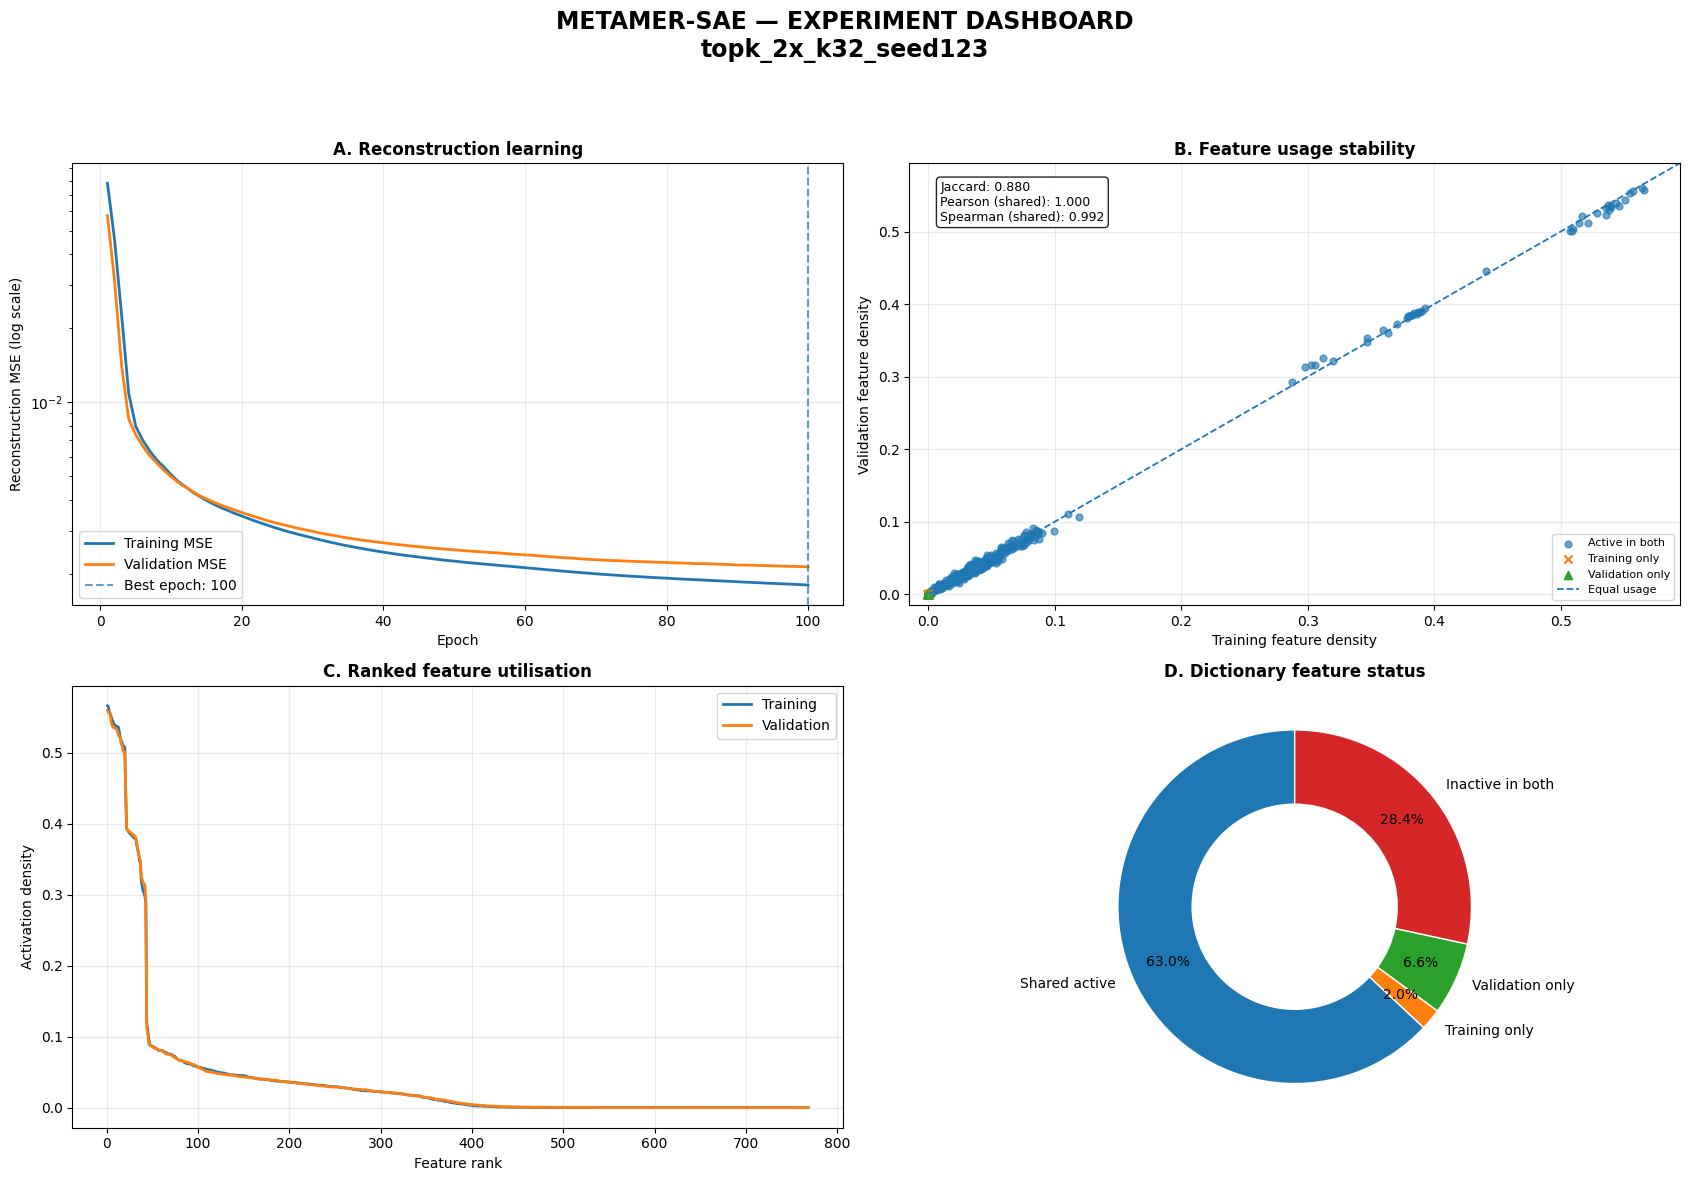

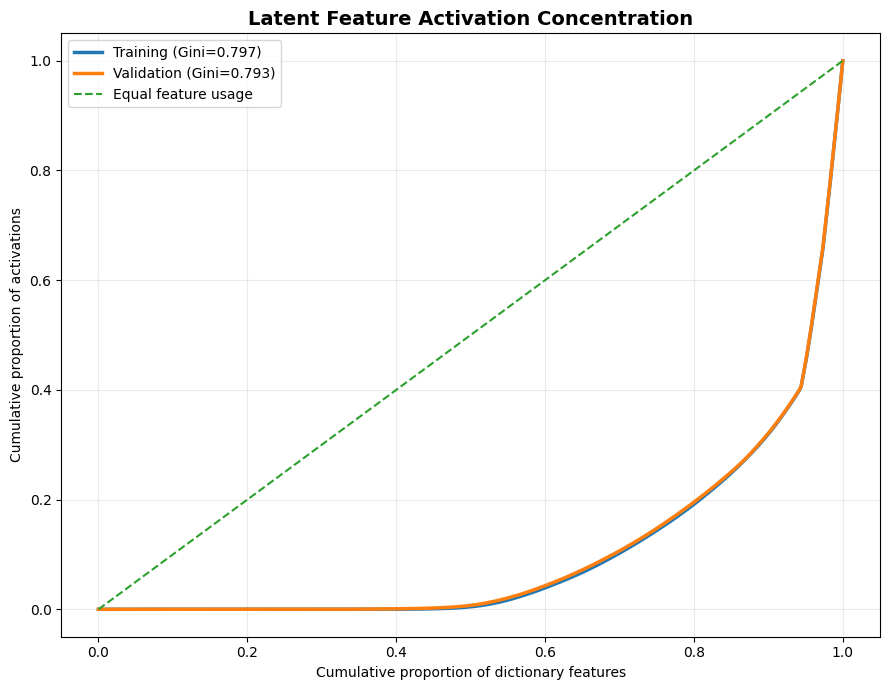

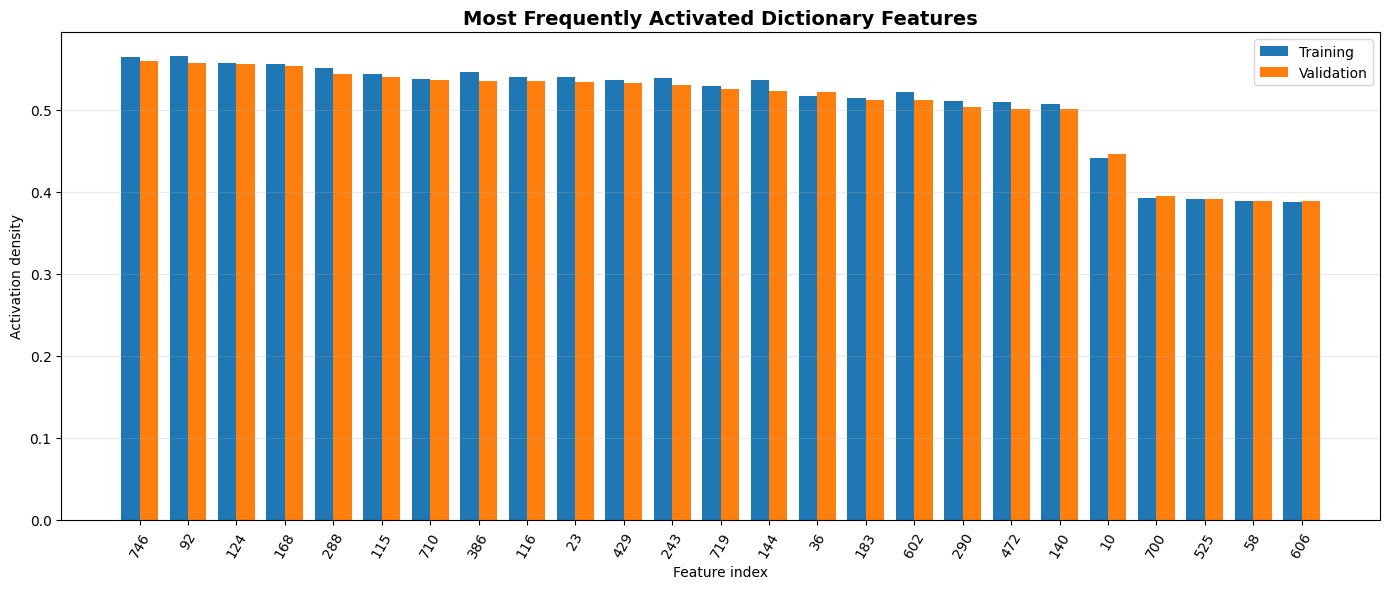

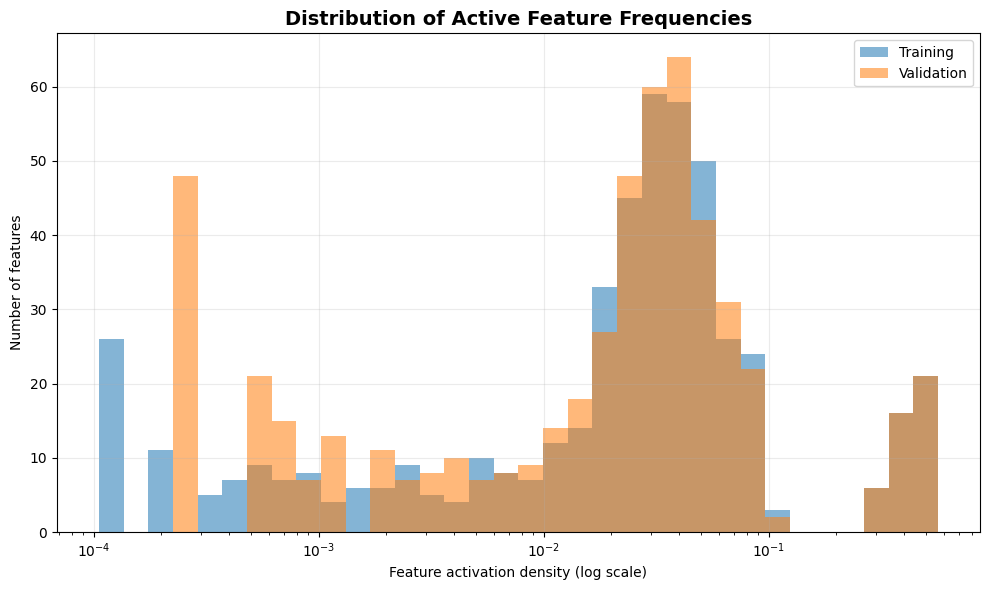


VISUALISATION SUITE COMPLETED: topk_2x_k32_seed123
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_2x_k32_seed123/figures
Support Jaccard: 0.88
Top-20 activation share: 0.3316
Validation Gini: 0.7932


,Value
run_id,topk_2x_k32_seed123
dictionary_size,768
training_active_features,499
validation_active_features,535
shared_active_features,484
inactive_in_both,218
support_jaccard,0.88
support_dice,0.93617
pearson_correlation_shared_features,0.999537
spearman_correlation_shared_features,0.991847


In [ ]:
experiment_4_visual_metrics = generate_run_visualizations(
    "topk_2x_k32_seed123"
)

display(
    pd.DataFrame([
        experiment_4_visual_metrics
    ]).T.rename(columns={0: "Value"})
)

### regenerate Experiment 4 visualizations

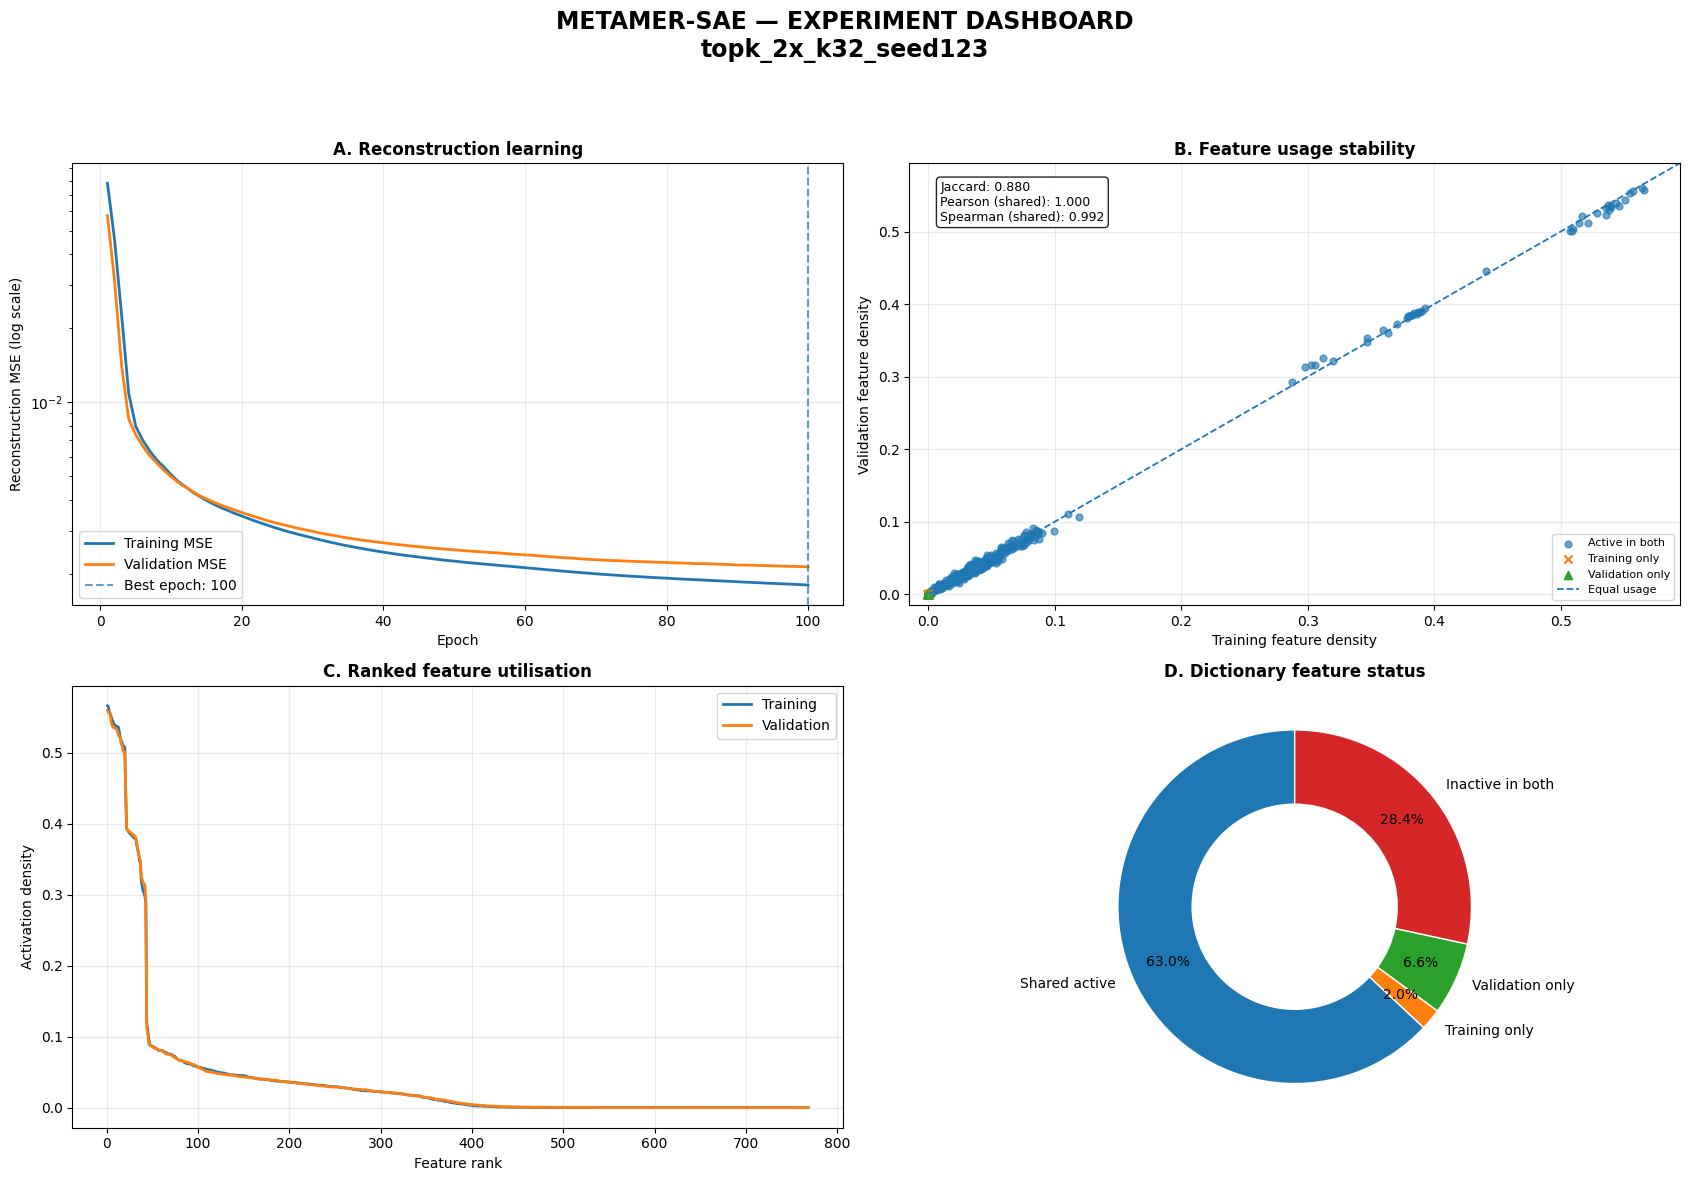

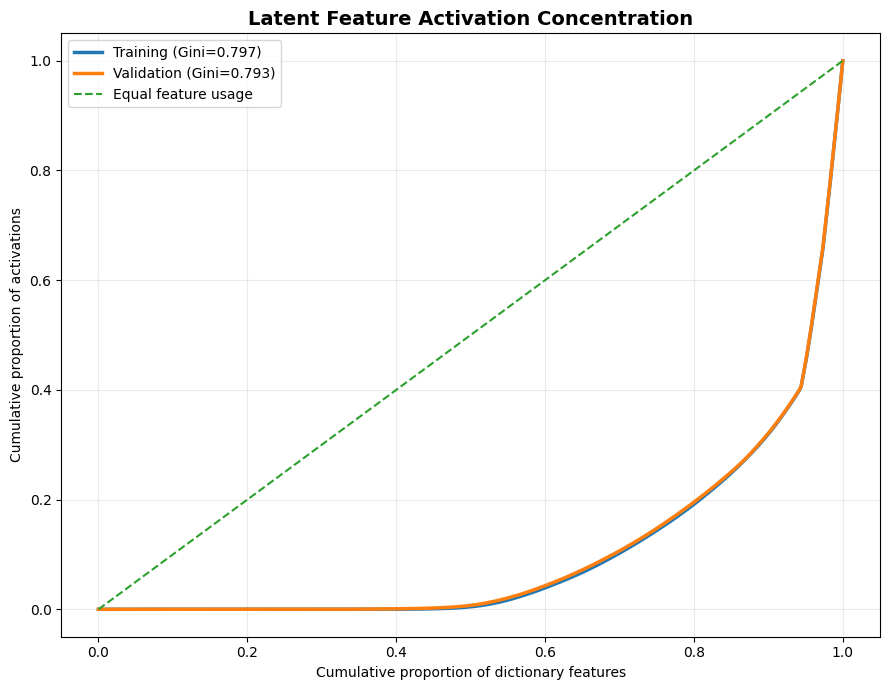

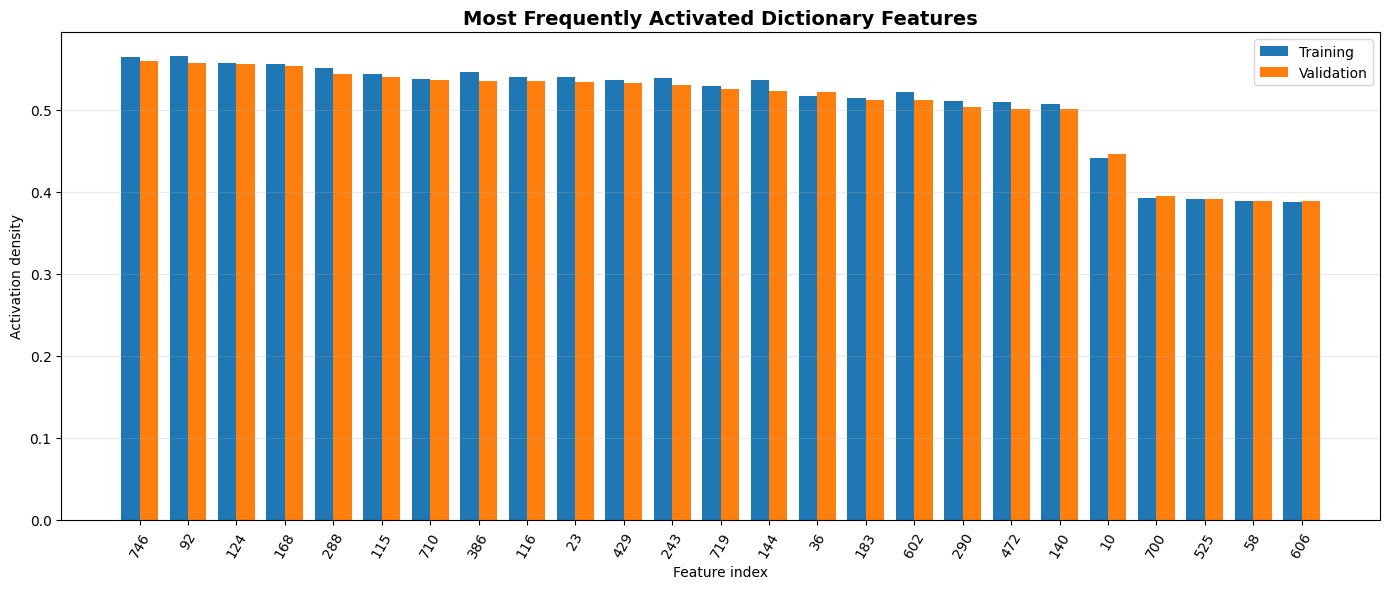

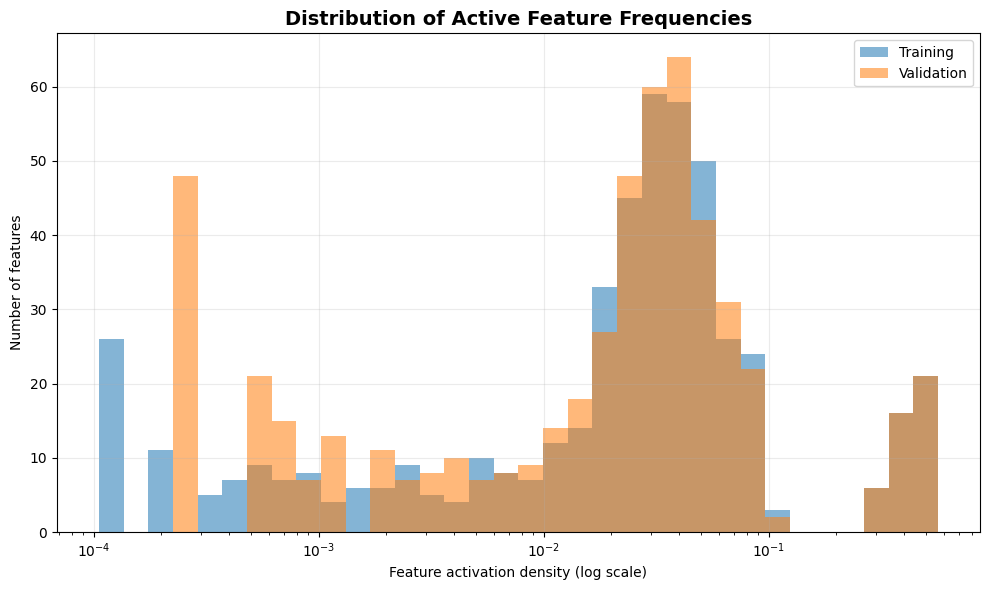


VISUALISATION SUITE COMPLETED: topk_2x_k32_seed123
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_2x_k32_seed123/figures
Support Jaccard: 0.88
Top-20 activation share: 0.3316
Validation Gini: 0.7932

EXPERIMENT 4 — VISUALIZATION GENERATION COMPLETE
Run: topk_2x_k32_seed123
Metrics: {'run_id': 'topk_2x_k32_seed123', 'dictionary_size': 768, 'training_active_features': 499, 'validation_active_features': 535, 'shared_active_features': 484, 'inactive_in_both': 218, 'support_jaccard': 0.88, 'support_dice': np.float64(0.9361702127659575), 'pearson_correlation_shared_features': 0.9995374626636265, 'spearman_correlation_shared_features': 0.9918465475721834, 'top20_validation_activation_share': 0.3315605095541402, 'top50_validation_activation_share': 0.614124203821656, 'training_gini': 0.7967224926817118, 'validation_gini': 0.7931941057921974, 'best_validation_mse': 0.0021336685251563217, 'best_epoch': 100}

SAVED FIGURES
01_experiment_dashboard.png — 519,799 bytes
02_

In [ ]:
# ============================================================
# EXPERIMENT 4 — GENERATE VISUAL DIAGNOSTICS
# ============================================================

RUN_ID = "topk_2x_k32_seed123"

visualization_metrics = generate_run_visualizations(RUN_ID)

print("\n" + "=" * 70)
print("EXPERIMENT 4 — VISUALIZATION GENERATION COMPLETE")
print("=" * 70)
print("Run:", RUN_ID)
print("Metrics:", visualization_metrics)

FIGURE_DIR = TRAINING_ROOT / RUN_ID / "figures"

print("\nSAVED FIGURES")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print(f"{path.name} — {path.stat().st_size:,} bytes")

print("\nMETRICS FILES")
for path in sorted(FIGURE_DIR.glob("*.json")):
    print(path.name)

In [ ]:
# ============================================================
# METAMER-SAE — BATCH TRAINING: EXPERIMENTS 5–8
# ============================================================
# Runs all four remaining experiments sequentially.
# Saves a progress manifest after each experiment.
# Skips already-completed runs; flags incomplete artifacts.
# ============================================================

import gc
import json
import traceback
from pathlib import Path

import numpy as np
import torch

# ------------------------------------------------------------
# 1. CONFIGURATION AND PRE-FLIGHT CHECKS
# ------------------------------------------------------------

BATCH_RUNS = [
    (4, "topk_4x_k32_seed42"),
    (5, "topk_4x_k32_seed123"),
    (6, "topk_4x_k64_seed42"),
    (7, "topk_4x_k64_seed123"),
]

BATCH_REPORT_PATH = TRAINING_ROOT / "experiments_5_to_8_batch_report.json"

assert torch.cuda.is_available(), (
    "CUDA is not available. Stop here and check the Colab runtime."
)

assert len(EXPERIMENT_GRID) >= 8, (
    "The experiment grid does not contain all eight planned experiments."
)

assert len(X_train_sae) == 9469
assert len(X_validation_sae) == 3925

print("=" * 75)
print("METAMER-SAE — EXPERIMENTS 5–8 BATCH")
print("=" * 75)
print("Device:", torch.cuda.get_device_name(0))
print("Training samples:", len(X_train_sae))
print("Validation samples:", len(X_validation_sae))
print("Batch size:", TRAINING_SETTINGS["batch_size"])
print("Maximum epochs:", TRAINING_SETTINGS["max_epochs"])
print("Learning rate:", TRAINING_SETTINGS["learning_rate"])
print("Experiments scheduled:", len(BATCH_RUNS))

# ------------------------------------------------------------
# 2. JSON-SAFE SERIALISATION
# ------------------------------------------------------------

def batch_json_safe(value):
    if isinstance(value, dict):
        return {str(k): batch_json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [batch_json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, torch.device):
        return str(value)
    if torch.is_tensor(value):
        return value.detach().cpu().tolist()
    return value


# ------------------------------------------------------------
# 3. PERSISTENT BATCH REPORT
# ------------------------------------------------------------

batch_report = {
    "batch": "experiments_5_to_8",
    "status": "running",
    "device": torch.cuda.get_device_name(0),
    "experiments": []
}


def save_batch_report():
    BATCH_REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)

    temporary_path = BATCH_REPORT_PATH.with_suffix(".tmp")

    with open(temporary_path, "w") as f:
        json.dump(batch_json_safe(batch_report), f, indent=2)
        f.flush()

    temporary_path.replace(BATCH_REPORT_PATH)


# ------------------------------------------------------------
# 4. SEQUENTIAL TRAINING
# ------------------------------------------------------------

for grid_index, expected_run_id in BATCH_RUNS:

    print("\n" + "=" * 75)
    print("STARTING:", expected_run_id)
    print("=" * 75)

    run_dir = TRAINING_ROOT / expected_run_id
    checkpoint_path = run_dir / "best_model.pt"
    summary_path = run_dir / "run_summary.json"

    record = {
        "run_id": expected_run_id,
        "grid_index": grid_index,
        "status": "pending"
    }

    try:

        # ----------------------------------------------------
        # A. CHECK FOR AN ALREADY COMPLETED RUN
        # ----------------------------------------------------

        if checkpoint_path.exists() and summary_path.exists():

            with open(summary_path, "r") as f:
                summary = json.load(f)

            if summary.get("run_id") != expected_run_id:
                raise RuntimeError(
                    "Existing summary has an unexpected run ID."
                )

            print("Existing completed run detected.")
            print("Skipping retraining.")

        else:

            # Do not overwrite incomplete experiment artifacts.
            existing_files = (
                list(run_dir.iterdir())
                if run_dir.exists()
                else []
            )

            if existing_files:
                raise RuntimeError(
                    "Incomplete run directory detected. "
                    "Recovery is required before training this run. "
                    f"Existing files: {[p.name for p in existing_files]}"
                )

            # ------------------------------------------------
            # B. TRAIN THE EXPERIMENT
            # ------------------------------------------------

            experiment_config = EXPERIMENT_GRID[grid_index]

            print("Configuration:")
            print(json.dumps(
                batch_json_safe(experiment_config),
                indent=2
            ))

            summary = train_topk_experiment(experiment_config)

            if summary.get("run_id") != expected_run_id:
                raise RuntimeError(
                    "Training returned an unexpected run ID: "
                    f"{summary.get('run_id')}"
                )

        # ----------------------------------------------------
        # C. VERIFY PERSISTED ARTIFACTS
        # ----------------------------------------------------

        required_files = [
            checkpoint_path,
            summary_path,
            run_dir / "run_config.json",
            run_dir / "training_history.csv",
            run_dir / "train_feature_density.npy",
            run_dir / "validation_feature_density.npy",
        ]

        missing_files = [
            str(path) for path in required_files
            if not path.is_file()
        ]

        if missing_files:
            raise FileNotFoundError(
                "Required experiment artifacts are missing: "
                + ", ".join(missing_files)
            )

        # Read summary back from disk, not only from memory.
        with open(summary_path, "r") as f:
            verified_summary = json.load(f)

        if verified_summary.get("run_id") != expected_run_id:
            raise RuntimeError("Saved summary verification failed.")

        print("\nArtifact verification: PASSED")

        # ----------------------------------------------------
        # D. GENERATE ALL VISUAL DIAGNOSTICS
        # ----------------------------------------------------

        print("\nGenerating visual diagnostics...")

        metrics = generate_run_visualizations(expected_run_id)

        figure_dir = run_dir / "figures"
        figure_paths = sorted(figure_dir.glob("*.png"))

        if len(figure_paths) < 4:
            raise RuntimeError(
                "Expected four visualisation figures, but found "
                f"{len(figure_paths)}."
            )

        # ----------------------------------------------------
        # E. RECORD RESULTS
        # ----------------------------------------------------

        record.update({
            "status": "completed",
            "best_epoch": verified_summary.get("best_epoch"),
            "validation_mse": verified_summary.get(
                "best_validation_mse"
            ),
            "checkpoint": str(checkpoint_path),
            "figure_count": len(figure_paths),
            "figures": [p.name for p in figure_paths],
            "visualization_metrics": batch_json_safe(metrics),
        })

        print("\nEXPERIMENT COMPLETED")
        print("-" * 60)
        print("Run:", expected_run_id)
        print("Best epoch:", record["best_epoch"])
        print("Validation MSE:", record["validation_mse"])
        print("Active validation features:",
              metrics.get("validation_active_features"))
        print("Support Jaccard:", metrics.get("support_jaccard"))
        print("Validation Gini:", metrics.get("validation_gini"))
        print("Figures saved:", len(figure_paths))

    except Exception as exc:

        record["status"] = "failed"
        record["error"] = str(exc)
        record["traceback"] = traceback.format_exc()

        print("\nEXPERIMENT FAILED")
        print("Run:", expected_run_id)
        print("Error:", str(exc))
        print("The batch will proceed to the next experiment.")

    finally:

        batch_report["experiments"].append(record)
        save_batch_report()

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ------------------------------------------------------------
# 5. FINAL BATCH REPORT
# ------------------------------------------------------------

completed = [
    r for r in batch_report["experiments"]
    if r["status"] == "completed"
]

failed = [
    r for r in batch_report["experiments"]
    if r["status"] == "failed"
]

batch_report["status"] = (
    "completed"
    if len(completed) == len(BATCH_RUNS)
    else "completed_with_failures"
)

batch_report["completed_count"] = len(completed)
batch_report["failed_count"] = len(failed)

save_batch_report()

print("\n" + "=" * 75)
print("METAMER-SAE — EXPERIMENTS 5–8 BATCH REPORT")
print("=" * 75)

print(f"Completed: {len(completed)}/{len(BATCH_RUNS)}")
print(f"Failed:    {len(failed)}/{len(BATCH_RUNS)}")

print("\nRESULTS")
print("-" * 75)

for record in batch_report["experiments"]:
    print(
        f"{record['run_id']:<30} "
        f"{record['status']:<12} "
        f"Best epoch: {record.get('best_epoch', 'N/A')} "
        f"MSE: {record.get('validation_mse', 'N/A')}"
    )

print("\nBatch report saved to:")
print(BATCH_REPORT_PATH)

print("\n" + "=" * 75)
print("BATCH EXECUTION FINISHED")
print("=" * 75)


METAMER-SAE — EXPERIMENTS 5–8 BATCH
Device: Tesla T4
Training samples: 9469
Validation samples: 3925
Batch size: 256
Maximum epochs: 100
Learning rate: 0.0005
Experiments scheduled: 4

STARTING: topk_4x_k32_seed42
Configuration:
{
  "input_dimensions": 384,
  "expansion_factor": 4,
  "nb_concepts": 1536,
  "top_k": 32,
  "active_fraction": 0.020833333333333332,
  "random_seed": 42
}

STARTING: topk_4x_k32_seed42
Dictionary: 1536
TopK: 32
Seed: 42
Device: cuda
---------------------------------------------------------------------------
Epoch 001 | Train MSE: 0.073516 | Val MSE: 0.053978 | Val improvement: 40.66% | Val L0: 32.00 | Dead: 24.35% | LR: 0.000500 | Time: 0.63s
Epoch 002 | Train MSE: 0.042093 | Val MSE: 0.027730 | Val improvement: 69.52% | Val L0: 32.00 | Dead: 55.92% | LR: 0.000500 | Time: 0.64s
Epoch 003 | Train MSE: 0.019783 | Val MSE: 0.012690 | Val improvement: 86.05% | Val L0: 32.00 | Dead: 72.27% | LR: 0.000500 | Time: 0.68s
Epoch 004 | Train MSE: 0.010655 | Val MSE: 0.0

### Recover the artifacts — without retraining

In [ ]:

# ============================================================
# METAMER-SAE — INSPECT EXPERIMENTS 5–8 ARTIFACTS
# Read-only: does not train, overwrite, or modify anything.
# ============================================================

import json
import pandas as pd
from pathlib import Path

RUN_IDS = [
    "topk_4x_k32_seed42",
    "topk_4x_k32_seed123",
    "topk_4x_k64_seed42",
    "topk_4x_k64_seed123",
]

print("=" * 75)
print("EXPERIMENTS 5–8 — ARTIFACT INSPECTION")
print("=" * 75)

for run_id in RUN_IDS:

    run_dir = TRAINING_ROOT / run_id

    print("\n" + "=" * 75)
    print("RUN:", run_id)
    print("=" * 75)

    if not run_dir.exists():
        print("ERROR: Run directory does not exist.")
        continue

    print("\nFILES:")
    for path in sorted(run_dir.iterdir()):
        if path.is_file():
            print(f"  {path.name:<40} {path.stat().st_size:>12,} bytes")
        elif path.is_dir():
            print(f"  {path.name}/")

    # Inspect training history
    history_path = run_dir / "training_history.csv"

    if history_path.exists():
        history = pd.read_csv(history_path)

        print("\nTRAINING HISTORY")
        print("Rows:", len(history))
        print("Columns:", history.columns.tolist())
        print("\nLast 3 rows:")
        print(history.tail(3).to_string(index=False))

        # Show minimum validation MSE if column exists
        val_columns = [
            c for c in history.columns
            if "val" in c.lower() and "mse" in c.lower()
        ]

        for col in val_columns:
            idx = history[col].astype(float).idxmin()
            print(
                f"\nMinimum {col}: "
                f"{history.loc[idx, col]:.12f} "
                f"at epoch {idx + 1}"
            )

    # Inspect configuration
    config_path = run_dir / "run_config.json"

    if config_path.exists():
        with open(config_path, "r") as f:
            config = json.load(f)

        print("\nCONFIGURATION:")
        print(json.dumps(config, indent=2)[:3000])

    # Check summary presence
    summary_path = run_dir / "run_summary.json"
    print(
        "\nSummary JSON:",
        "PRESENT" if summary_path.exists() else "MISSING"
    )

print("\n" + "=" * 75)
print("ARTIFACT INSPECTION FINISHED")
print("=" * 75)


EXPERIMENTS 5–8 — ARTIFACT INSPECTION

RUN: topk_4x_k32_seed42

FILES:
  best_model.pt                               4,728,699 bytes
  run_config.json                                 1,440 bytes
  train_feature_density.npy                      12,416 bytes
  training_history.csv                           15,467 bytes
  validation_feature_density.npy                 12,416 bytes

TRAINING HISTORY
Rows: 100
Columns: ['epoch', 'train_mse', 'validation_mse', 'validation_improvement_vs_zero_percent', 'train_mean_l0', 'validation_mean_l0', 'train_dead_feature_fraction', 'validation_dead_feature_fraction', 'train_active_features', 'validation_active_features', 'learning_rate', 'epoch_seconds', 'is_best_checkpoint', 'is_significant_patience_improvement']

Last 3 rows:
 epoch  train_mse  validation_mse  validation_improvement_vs_zero_percent  train_mean_l0  validation_mean_l0  train_dead_feature_fraction  validation_dead_feature_fraction  train_active_features  validation_active_features  learn

### First, inspect the Experiment 4 summary structure
I want to reconstruct the missing summaries using the exact structure expected by our existing visualisation function, rather than inventing a new format.

In [ ]:

# ============================================================
# INSPECT THE VERIFIED EXPERIMENT 4 SUMMARY SCHEMA
# Read-only diagnostic
# ============================================================

import json
from pathlib import Path

template_path = (
    TRAINING_ROOT
    / "topk_2x_k32_seed123"
    / "run_summary.json"
)

assert template_path.exists(), (
    "Experiment 4 summary is missing. "
    "We need to recover it before using it as a template."
)

with open(template_path, "r") as f:
    template = json.load(f)

print("=" * 70)
print("EXPERIMENT 4 SUMMARY — SCHEMA")
print("=" * 70)

for key, value in template.items():
    if isinstance(value, dict):
        print(f"{key}: dict")
        for nested_key, nested_value in value.items():
            print(f"    {nested_key}: {type(nested_value).__name__}")
    elif isinstance(value, list):
        print(f"{key}: list ({len(value)} items)")
    else:
        print(f"{key}: {type(value).__name__} = {value}")

print("\nFull summary:")
print(json.dumps(template, indent=2))


EXPERIMENT 4 SUMMARY — SCHEMA
status: str = completed
run_id: str = topk_2x_k32_seed123
expansion_factor: int = 2
dictionary_size: int = 768
top_k: int = 32
seed: int = 123
best_epoch: int = 100
epochs_completed: int = 100
checkpoint_selection_policy: str = absolute_minimum_validation_mse
best_validation_mse: float = 0.0021336685251563217
best_training_mse: float = 0.0017806545793814437
validation_zero_baseline_mse: float = 0.09097086922972816
validation_improvement_vs_zero_percent: float = 97.65455849413928
training_mean_l0: float = 32.0
validation_mean_l0: float = 32.0
training_active_features: int = 499
validation_active_features: int = 535
training_dead_feature_fraction: float = 0.3502604166666667
validation_dead_feature_fraction: float = 0.3033854166666667
training_seconds: float = 21.793028831481934
checkpoint: str = /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_2x_k32_seed123/best_model.pt
training_history: str = /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/t

### Recovery and visualisation for all four runs
The following single cell will:
- Reconstruct the four missing run_summary.json files.
- Preserve each run's original configuration and checkpoint.
- Verify the reconstructed summary against the saved history and density arrays.
- Generate the four diagnostic figures for each run.
- Save a separate recovery report, leaving the original batch report intact

METAMER-SAE — EXPERIMENTS 5–8 RECOVERY

RECOVERING: topk_4x_k32_seed42

FAILED: topk_4x_k32_seed42: training density count does not match history. Array=746, history=747

RECOVERING: topk_4x_k32_seed123

FAILED: topk_4x_k32_seed123: training density count does not match history. Array=791, history=782

RECOVERING: topk_4x_k64_seed42
Summary recovery: PASSED
Best epoch: 100
Validation MSE: 0.0016729172079521
Training active features: 1203
Validation active features: 1260

Generating visualisations...


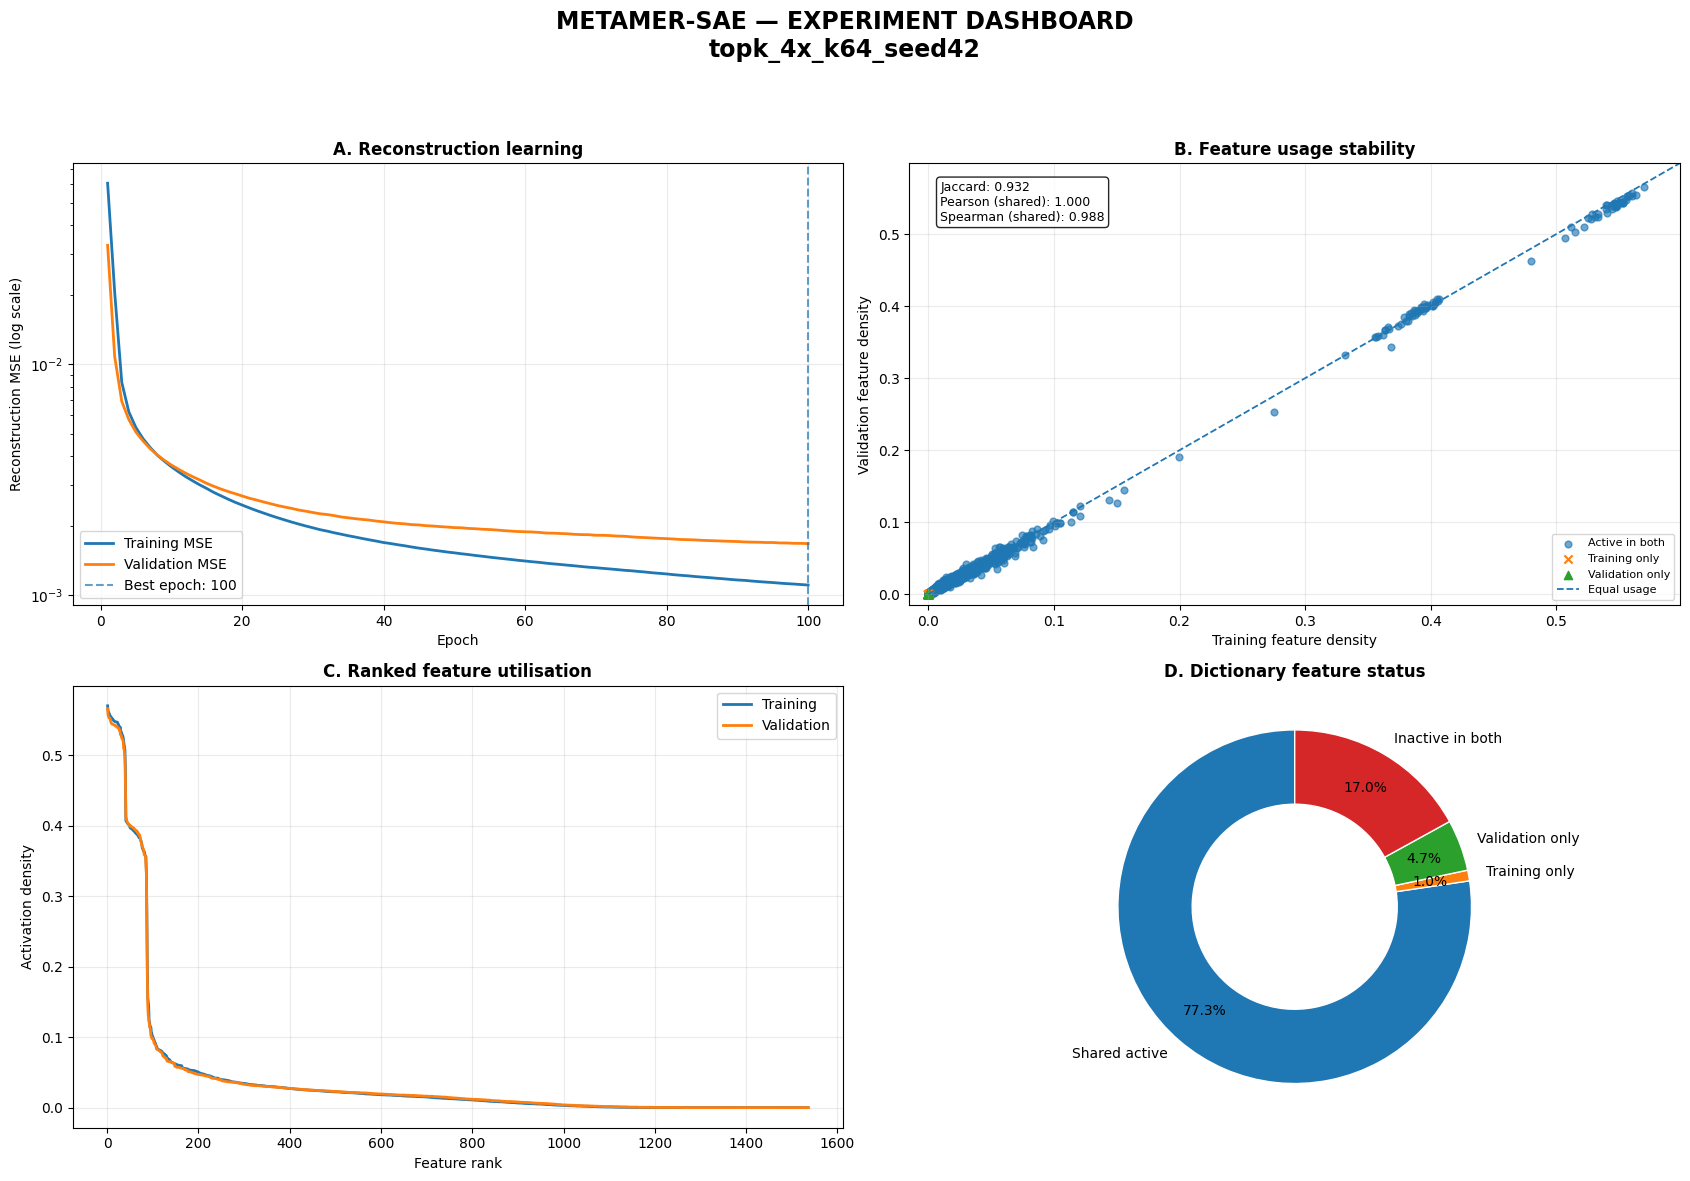

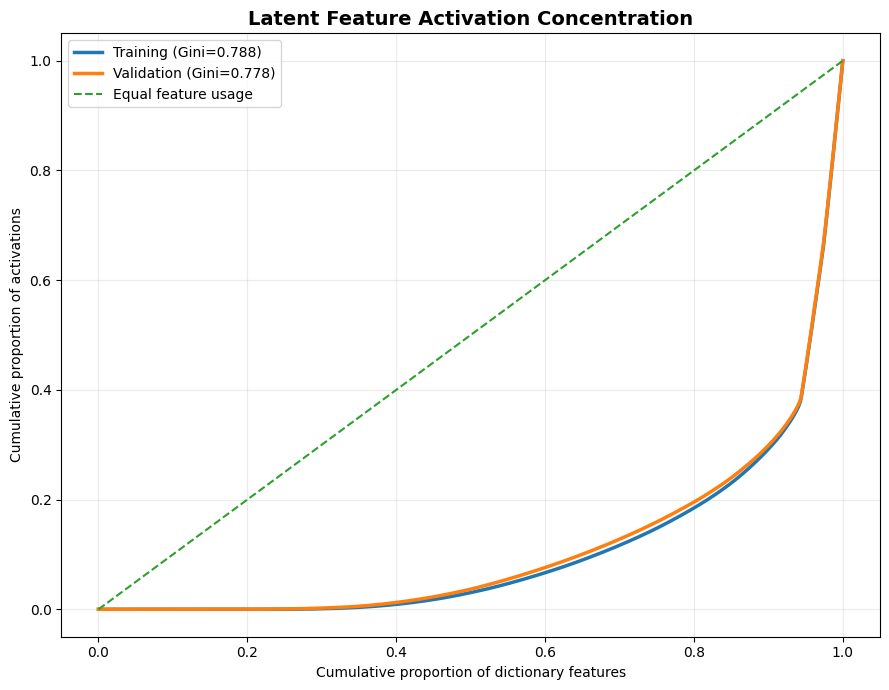

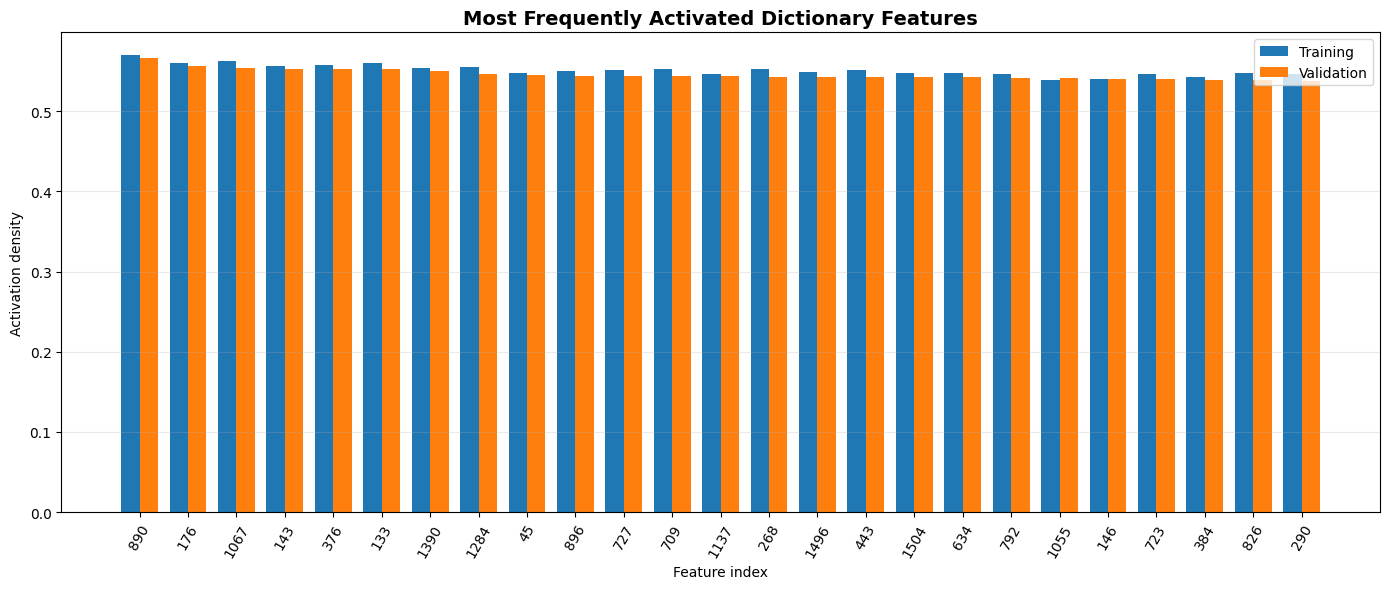

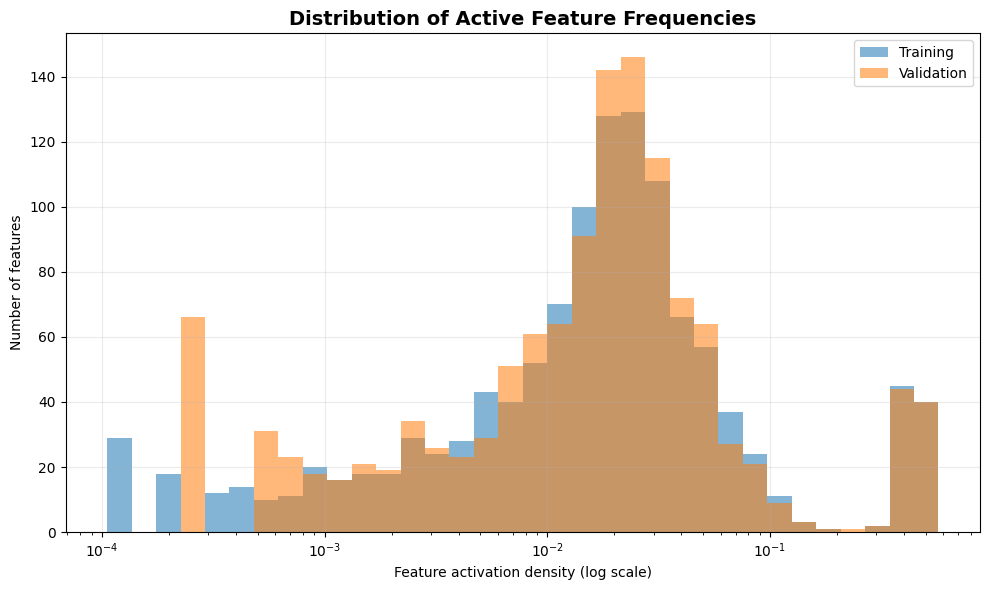


VISUALISATION SUITE COMPLETED: topk_4x_k64_seed42
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_4x_k64_seed42/figures
Support Jaccard: 0.9318
Top-20 activation share: 0.1711
Validation Gini: 0.7781

VISUALISATION: PASSED
Figures generated: 4
Support Jaccard: 0.9317647058823529
Pearson: 0.999500980172109
Spearman: 0.9878443065096589
Validation Gini: 0.7781412138402333

RECOVERING: topk_4x_k64_seed123

FAILED: topk_4x_k64_seed123: training density count does not match history. Array=1224, history=1218

EXPERIMENTS 5–8 — RECOVERY REPORT
topk_4x_k32_seed42             recovery_or_visualization_failed
topk_4x_k32_seed123            recovery_or_visualization_failed
topk_4x_k64_seed42             recovered_and_visualized
topk_4x_k64_seed123            recovery_or_visualization_failed

Successful: 1 / 4
Failed: 3 / 4
Report: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/experiments_5_to_8_recovery_report.json

No training was performed.


In [ ]:

# ============================================================
# METAMER-SAE — RECOVER EXPERIMENTS 5–8 + GENERATE VISUALS
# No model training. Existing checkpoints are preserved.
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

RUN_IDS = [
    "topk_4x_k32_seed42",
    "topk_4x_k32_seed123",
    "topk_4x_k64_seed42",
    "topk_4x_k64_seed123",
]

RECOVERY_REPORT_PATH = (
    TRAINING_ROOT / "experiments_5_to_8_recovery_report.json"
)

recovery_report = {
    "batch": "experiments_5_to_8",
    "recovery_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "training_performed": False,
    "runs": []
}


def atomic_json_save(data, destination):
    destination = Path(destination)
    temporary = destination.with_suffix(".tmp")

    with open(temporary, "w") as f:
        json.dump(data, f, indent=2)
        f.flush()

    temporary.replace(destination)


def recover_run_summary(run_id):

    run_dir = TRAINING_ROOT / run_id

    checkpoint_path = run_dir / "best_model.pt"
    config_path = run_dir / "run_config.json"
    history_path = run_dir / "training_history.csv"

    train_density_path = run_dir / "train_feature_density.npy"
    val_density_path = run_dir / "validation_feature_density.npy"

    summary_path = run_dir / "run_summary.json"

    # --------------------------------------------------------
    # A. VERIFY REQUIRED ORIGINAL ARTIFACTS
    # --------------------------------------------------------

    required = [
        checkpoint_path,
        config_path,
        history_path,
        train_density_path,
        val_density_path,
    ]

    missing = [str(p) for p in required if not p.is_file()]

    if missing:
        raise FileNotFoundError(
            f"{run_id}: missing required artifacts: {missing}"
        )

    # --------------------------------------------------------
    # B. LOAD ORIGINAL CONFIGURATION AND HISTORY
    # --------------------------------------------------------

    with open(config_path, "r") as f:
        config = json.load(f)

    history = pd.read_csv(history_path)

    assert config["run_id"] == run_id
    assert len(history) == 100

    required_columns = [
        "epoch",
        "train_mse",
        "validation_mse",
        "validation_improvement_vs_zero_percent",
        "train_mean_l0",
        "validation_mean_l0",
        "epoch_seconds",
    ]

    for column in required_columns:
        assert column in history.columns, (
            f"{run_id}: missing history column {column}"
        )

    # Select the absolute minimum validation MSE.
    best_index = history["validation_mse"].astype(float).idxmin()
    best_row = history.loc[best_index]

    best_epoch = int(best_row["epoch"])
    best_val_mse = float(best_row["validation_mse"])
    best_train_mse = float(best_row["train_mse"])

    # --------------------------------------------------------
    # C. LOAD FEATURE-DENSITY ARRAYS
    # --------------------------------------------------------

    train_density = np.load(train_density_path)
    val_density = np.load(val_density_path)

    dictionary_size = int(config["dictionary_size"])

    assert train_density.size == dictionary_size, (
        f"{run_id}: unexpected training density array size."
    )

    assert val_density.size == dictionary_size, (
        f"{run_id}: unexpected validation density array size."
    )

    train_density = train_density.reshape(-1)
    val_density = val_density.reshape(-1)

    train_active = int(np.count_nonzero(train_density > 0))
    val_active = int(np.count_nonzero(val_density > 0))

    train_dead_fraction = 1.0 - train_active / dictionary_size
    val_dead_fraction = 1.0 - val_active / dictionary_size

    # Verify saved density arrays against history at best epoch.
    history_train_active = int(best_row["train_active_features"])
    history_val_active = int(best_row["validation_active_features"])

    assert train_active == history_train_active, (
        f"{run_id}: training density count does not match history. "
        f"Array={train_active}, history={history_train_active}"
    )

    assert val_active == history_val_active, (
        f"{run_id}: validation density count does not match history. "
        f"Array={val_active}, history={history_val_active}"
    )

    # --------------------------------------------------------
    # D. RECONSTRUCT SUMMARY FIELDS
    # --------------------------------------------------------

    improvement = float(
        best_row["validation_improvement_vs_zero_percent"]
    )

    assert 0 < improvement < 100

    # Recover the zero-output baseline from the recorded
    # validation improvement percentage.
    zero_baseline = best_val_mse / (1.0 - improvement / 100.0)

    training_seconds = float(
        history["epoch_seconds"].astype(float).sum()
    )

    summary = {
        "status": "completed",
        "run_id": run_id,
        "expansion_factor": int(config["expansion_factor"]),
        "dictionary_size": dictionary_size,
        "top_k": int(config["top_k"]),
        "seed": int(config["random_seed"]),
        "best_epoch": best_epoch,
        "epochs_completed": int(len(history)),
        "checkpoint_selection_policy": config[
            "checkpoint_selection_policy"
        ],
        "best_validation_mse": best_val_mse,
        "best_training_mse": best_train_mse,
        "validation_zero_baseline_mse": float(zero_baseline),
        "validation_improvement_vs_zero_percent": improvement,
        "training_mean_l0": float(best_row["train_mean_l0"]),
        "validation_mean_l0": float(best_row["validation_mean_l0"]),
        "training_active_features": train_active,
        "validation_active_features": val_active,
        "training_dead_feature_fraction": float(train_dead_fraction),
        "validation_dead_feature_fraction": float(val_dead_fraction),
        "training_seconds": training_seconds,
        "checkpoint": str(checkpoint_path),
        "training_history": str(history_path),
        "primary_evaluation_loaded": bool(
            config.get("primary_evaluation_loaded", False)
        ),
        "reserve_loaded": bool(
            config.get("reserve_loaded", False)
        ),
    }

    # --------------------------------------------------------
    # E. SAVE AND READ-BACK VERIFY SUMMARY
    # --------------------------------------------------------

    atomic_json_save(summary, summary_path)

    with open(summary_path, "r") as f:
        verified = json.load(f)

    assert verified["run_id"] == run_id
    assert verified["status"] == "completed"
    assert verified["best_epoch"] == best_epoch
    assert np.isclose(
        verified["best_validation_mse"], best_val_mse,
        rtol=1e-9, atol=1e-12
    )

    assert checkpoint_path.stat().st_size > 0

    return verified


# ============================================================
# PROCESS ALL FOUR RUNS
# ============================================================

print("=" * 75)
print("METAMER-SAE — EXPERIMENTS 5–8 RECOVERY")
print("=" * 75)

for run_id in RUN_IDS:

    print("\n" + "=" * 75)
    print("RECOVERING:", run_id)
    print("=" * 75)

    record = {"run_id": run_id}

    try:
        summary = recover_run_summary(run_id)

        print("Summary recovery: PASSED")
        print("Best epoch:", summary["best_epoch"])
        print("Validation MSE:", summary["best_validation_mse"])
        print("Training active features:",
              summary["training_active_features"])
        print("Validation active features:",
              summary["validation_active_features"])

        print("\nGenerating visualisations...")

        metrics = generate_run_visualizations(run_id)

        figure_dir = TRAINING_ROOT / run_id / "figures"
        figures = sorted(figure_dir.glob("*.png"))

        assert len(figures) >= 4, (
            f"{run_id}: expected at least four figures; "
            f"found {len(figures)}."
        )

        record.update({
            "status": "recovered_and_visualized",
            "best_epoch": summary["best_epoch"],
            "validation_mse": summary["best_validation_mse"],
            "active_validation_features":
                summary["validation_active_features"],
            "dead_validation_fraction":
                summary["validation_dead_feature_fraction"],
            "visualization_metrics": metrics,
            "figures": [p.name for p in figures],
        })

        print("\nVISUALISATION: PASSED")
        print("Figures generated:", len(figures))
        print("Support Jaccard:", metrics["support_jaccard"])
        print("Pearson:", metrics["pearson_correlation_shared_features"])
        print("Spearman:", metrics["spearman_correlation_shared_features"])
        print("Validation Gini:", metrics["validation_gini"])

    except Exception as exc:

        record.update({
            "status": "recovery_or_visualization_failed",
            "error": str(exc),
        })

        print("\nFAILED:", str(exc))

    recovery_report["runs"].append(record)

    # Persist progress after every run.
    atomic_json_save(
        recovery_report,
        RECOVERY_REPORT_PATH
    )


# ============================================================
# FINAL RECOVERY REPORT
# ============================================================

successful = [
    r for r in recovery_report["runs"]
    if r["status"] == "recovered_and_visualized"
]

failed = [
    r for r in recovery_report["runs"]
    if r["status"] != "recovered_and_visualized"
]

recovery_report["successful_count"] = len(successful)
recovery_report["failed_count"] = len(failed)
recovery_report["status"] = (
    "complete" if len(successful) == 4
    else "incomplete"
)

atomic_json_save(recovery_report, RECOVERY_REPORT_PATH)

print("\n" + "=" * 75)
print("EXPERIMENTS 5–8 — RECOVERY REPORT")
print("=" * 75)

for r in recovery_report["runs"]:
    print(
        f"{r['run_id']:<30} "
        f"{r['status']}"
    )

print("\nSuccessful:", len(successful), "/ 4")
print("Failed:", len(failed), "/ 4")
print("Report:", RECOVERY_REPORT_PATH)
print("\nNo training was performed.")
print("=" * 75)


### diagnose the density arrays

In [ ]:

from pathlib import Path
import json
import numpy as np
import pandas as pd

RUN_IDS = [
    "topk_4x_k32_seed42",
    "topk_4x_k32_seed123",
    "topk_4x_k64_seed42",
    "topk_4x_k64_seed123",
]

THRESHOLDS = [0.0, 1e-12, 1e-10, 1e-8, 1e-6]

print("=" * 78)
print("METAMER-SAE — FEATURE DENSITY DISCREPANCY DIAGNOSTIC")
print("=" * 78)

diagnostic_report = {}

for run_id in RUN_IDS:
    run_dir = TRAINING_ROOT / run_id

    print("\n" + "=" * 78)
    print(f"RUN: {run_id}")
    print("=" * 78)

    history = pd.read_csv(run_dir / "training_history.csv")

    train_density = np.load(run_dir / "train_feature_density.npy")
    val_density = np.load(run_dir / "validation_feature_density.npy")

    last = history.iloc[-1]

    print("\nARRAY INFORMATION")
    for name, arr in [
        ("Training", train_density),
        ("Validation", val_density),
    ]:
        print(f"\n{name}:")
        print("  Shape:", arr.shape)
        print("  Dtype:", arr.dtype)
        print("  Finite:", bool(np.isfinite(arr).all()))
        print("  Minimum:", float(np.min(arr)))
        print("  Maximum:", float(np.max(arr)))
        print("  Exact nonzero count:", int(np.count_nonzero(arr)))
        print("  Positive count:", int(np.sum(arr > 0)))

        print("  Counts by threshold:")
        for threshold in THRESHOLDS:
            count = int(np.sum(arr > threshold))
            print(f"    > {threshold:g}: {count}")

    print("\nFINAL HISTORY ROW")
    for column in [
        "epoch",
        "train_active_features",
        "validation_active_features",
        "train_dead_feature_fraction",
        "validation_dead_feature_fraction",
        "train_mse",
        "validation_mse",
        "is_best_checkpoint",
    ]:
        if column in history.columns:
            print(f"  {column}: {last[column]}")

    best_rows = history[history["is_best_checkpoint"] == True]
    if len(best_rows):
        print("\nCHECKPOINT-MARKED HISTORY ROWS")
        print(
            best_rows[
                [
                    "epoch",
                    "train_active_features",
                    "validation_active_features",
                    "validation_mse",
                ]
            ].tail(5).to_string(index=False)
        )

    diagnostic_report[run_id] = {
        "training_array_shape": list(train_density.shape),
        "validation_array_shape": list(val_density.shape),
        "training_exact_nonzero": int(np.count_nonzero(train_density)),
        "validation_exact_nonzero": int(np.count_nonzero(val_density)),
        "training_positive": int(np.sum(train_density > 0)),
        "validation_positive": int(np.sum(val_density > 0)),
        "training_history_active": int(last["train_active_features"]),
        "validation_history_active": int(last["validation_active_features"]),
        "training_threshold_counts": {
            str(t): int(np.sum(train_density > t))
            for t in THRESHOLDS
        },
        "validation_threshold_counts": {
            str(t): int(np.sum(val_density > t))
            for t in THRESHOLDS
        },
    }

report_path = TRAINING_ROOT / "experiments_5_to_8_density_diagnostic.json"
report_path.parent.mkdir(parents=True, exist_ok=True)

with open(report_path, "w") as f:
    json.dump(diagnostic_report, f, indent=2)

print("\n" + "=" * 78)
print("DIAGNOSTIC COMPLETE")
print("=" * 78)
print("Report:", report_path)
print("No training or checkpoint files were modified.")


METAMER-SAE — FEATURE DENSITY DISCREPANCY DIAGNOSTIC

RUN: topk_4x_k32_seed42

ARRAY INFORMATION

Training:
  Shape: (1536,)
  Dtype: float64
  Finite: True
  Minimum: 0.0
  Maximum: 0.5660576618439117
  Exact nonzero count: 746
  Positive count: 746
  Counts by threshold:
    > 0: 746
    > 1e-12: 746
    > 1e-10: 746
    > 1e-08: 746
    > 1e-06: 746

Validation:
  Shape: (1536,)
  Dtype: float64
  Finite: True
  Minimum: 0.0
  Maximum: 0.5615286624203821
  Exact nonzero count: 808
  Positive count: 808
  Counts by threshold:
    > 0: 808
    > 1e-12: 808
    > 1e-10: 808
    > 1e-08: 808
    > 1e-06: 808

FINAL HISTORY ROW
  epoch: 100
  train_active_features: 747
  validation_active_features: 808
  train_dead_feature_fraction: 0.513671875
  validation_dead_feature_fraction: 0.4739583333333333
  train_mse: 0.0015831388867792
  validation_mse: 0.0020731788008788
  is_best_checkpoint: True

CHECKPOINT-MARKED HISTORY ROWS
 epoch  train_active_features  validation_active_features  valid


RECOVERING: topk_4x_k32_seed42
TRAIN FEATURE COUNTS
  Density array: 746
  Training history: 747
  Difference: -1

VALIDATION FEATURE COUNTS
  Density array: 808
  Validation history: 808
  Consistency: PASSED

SUMMARY RECOVERY: PASSED
Best epoch: 100
Validation MSE: 0.0020731788008788

Generating visualisations...


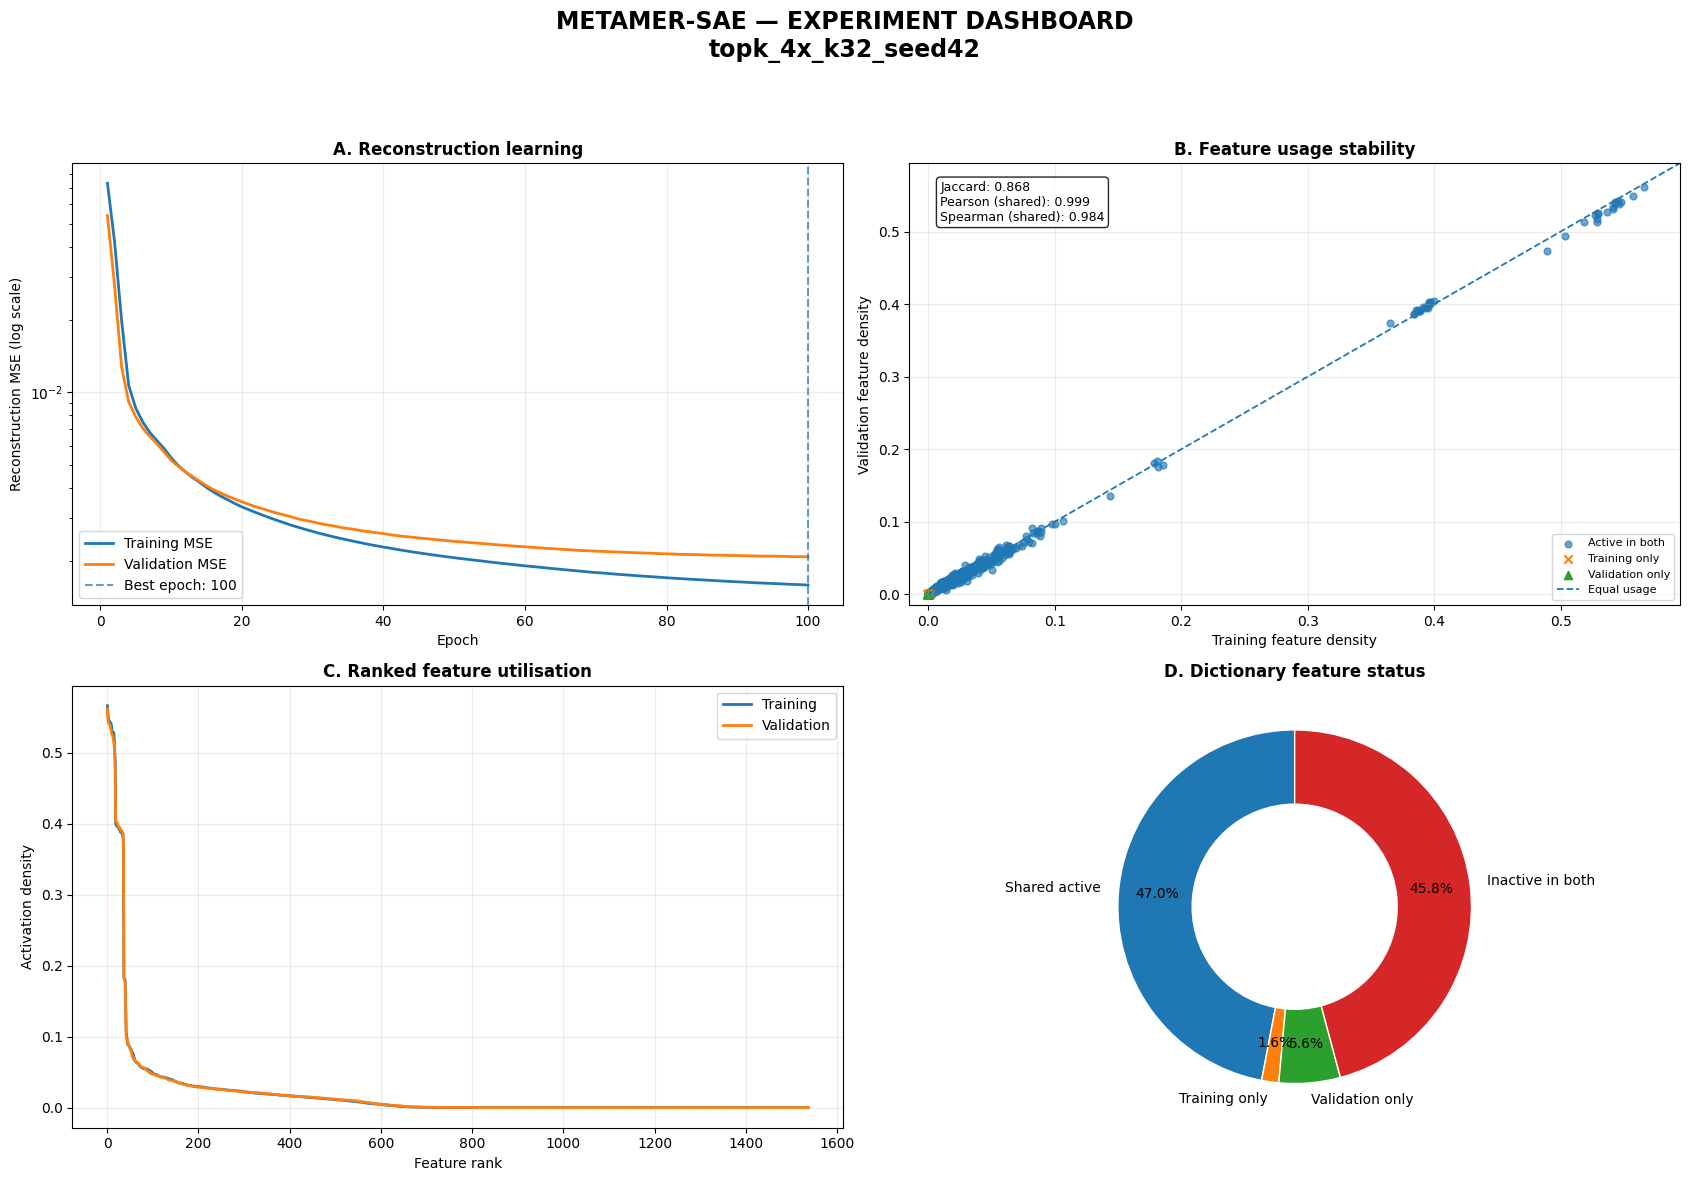

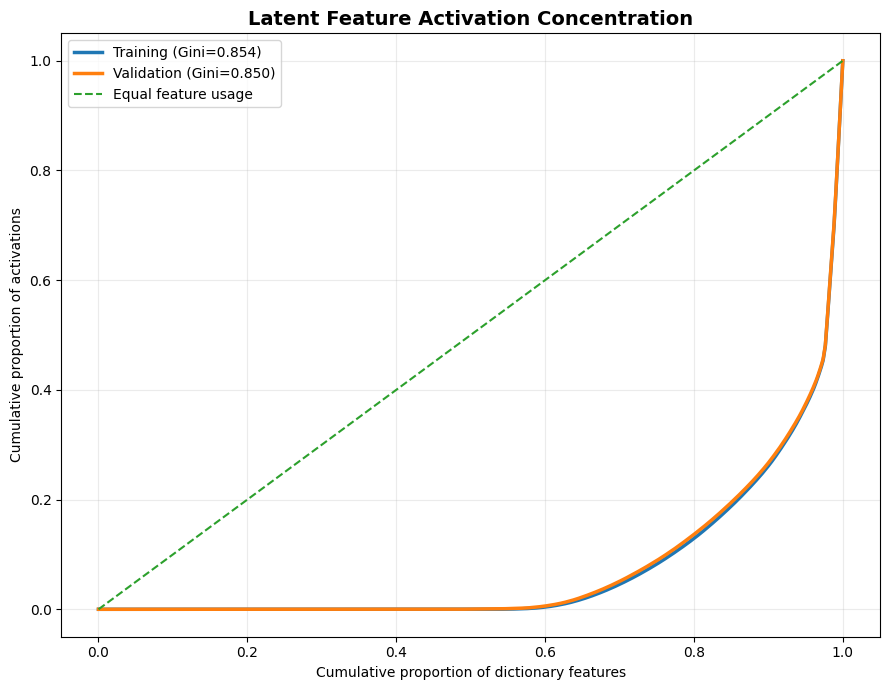

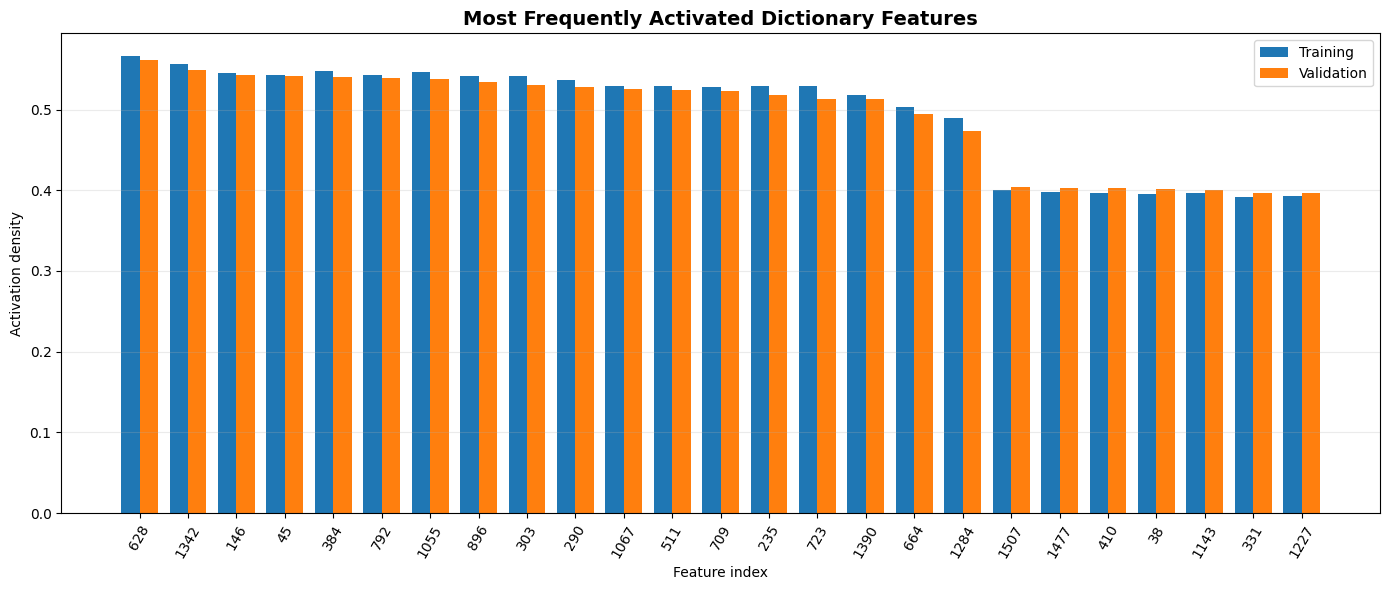

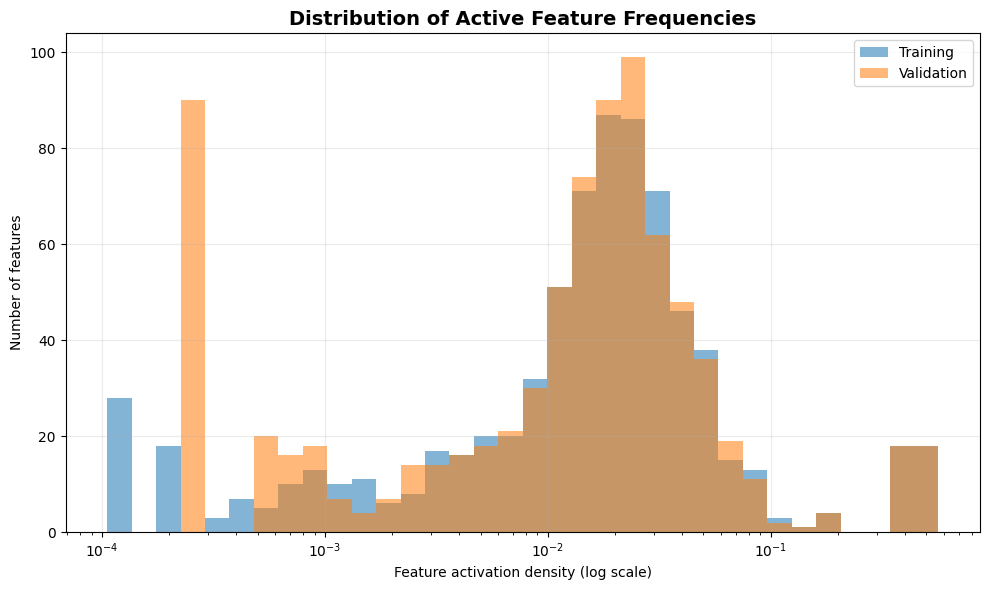


VISUALISATION SUITE COMPLETED: topk_4x_k32_seed42
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_4x_k32_seed42/figures
Support Jaccard: 0.8678
Top-20 activation share: 0.3218
Validation Gini: 0.8497

VISUALISATION: PASSED
Figures: 4
Support Jaccard: 0.8677884615384616
Validation Gini: 0.849714246616242

RECOVERING: topk_4x_k32_seed123
TRAIN FEATURE COUNTS
  Density array: 791
  Training history: 782
  Difference: 9

VALIDATION FEATURE COUNTS
  Density array: 840
  Validation history: 840
  Consistency: PASSED

SUMMARY RECOVERY: PASSED
Best epoch: 100
Validation MSE: 0.0021011469296067

Generating visualisations...


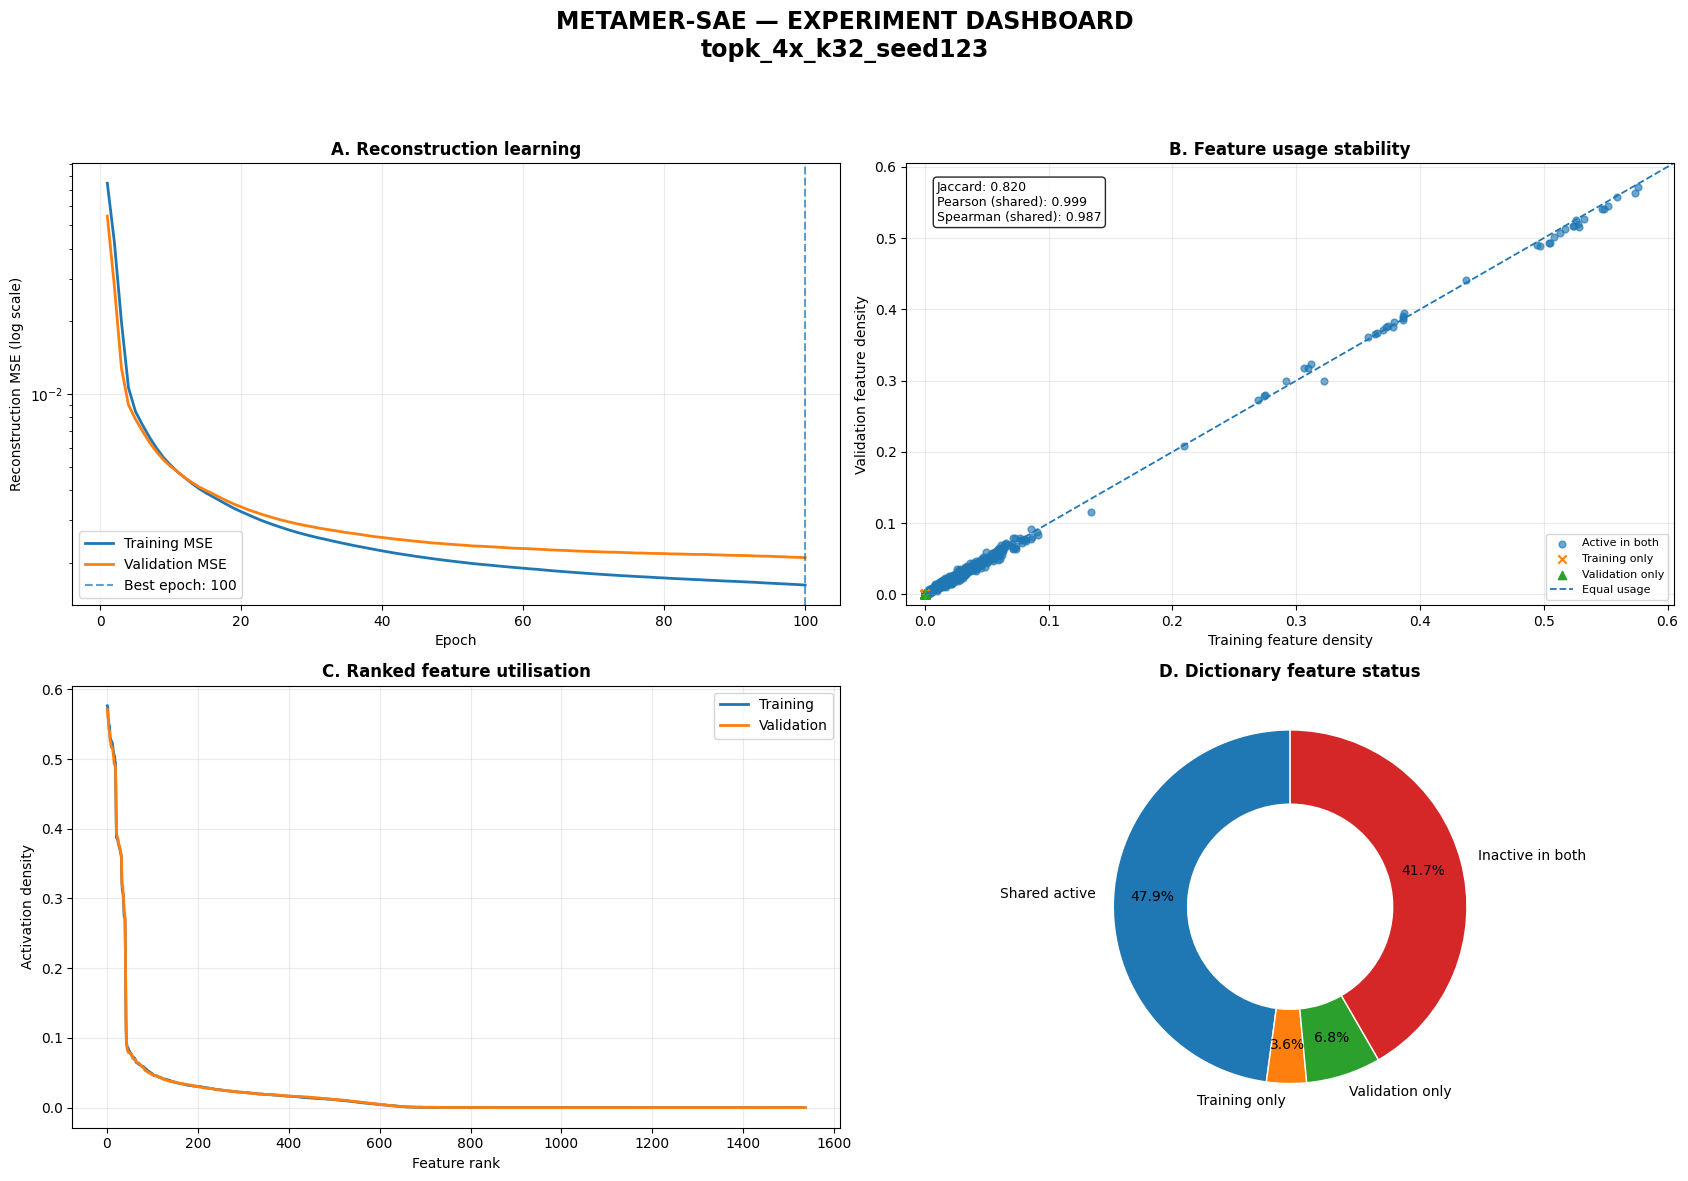

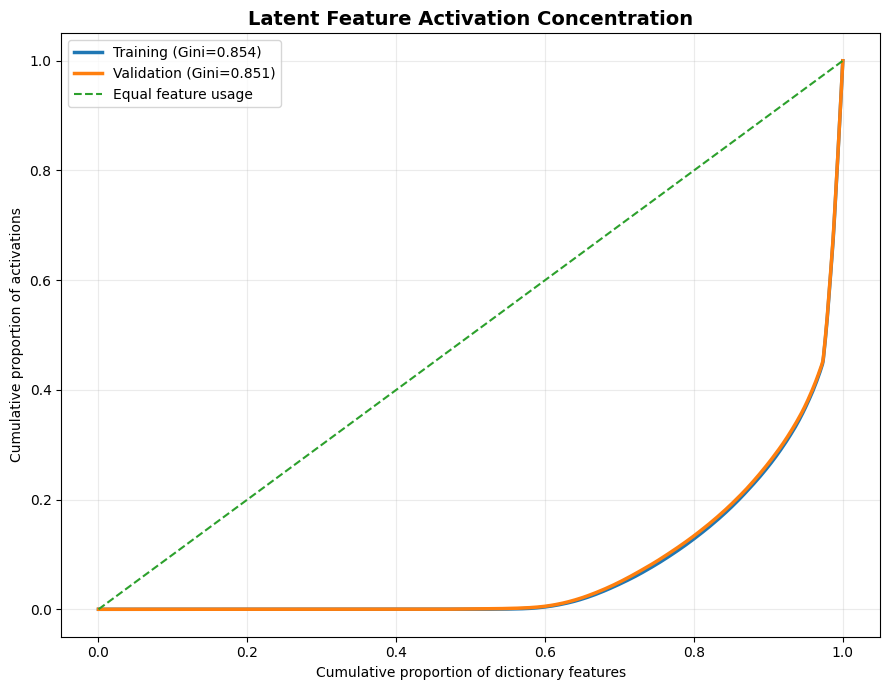

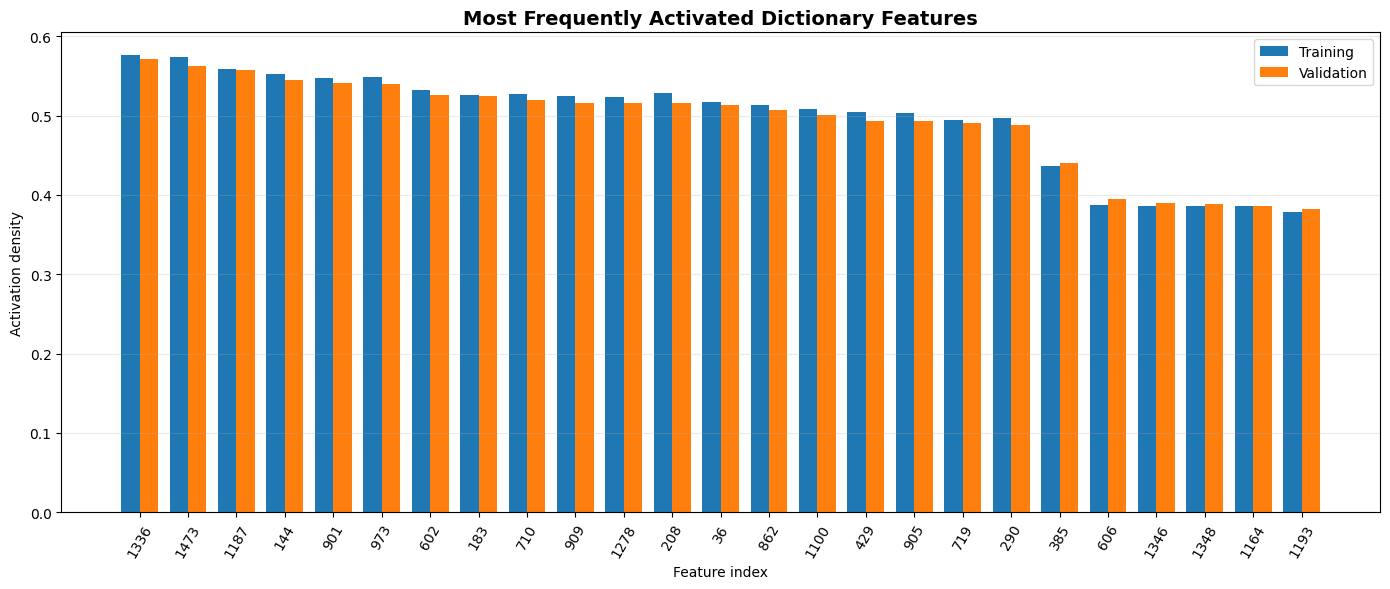

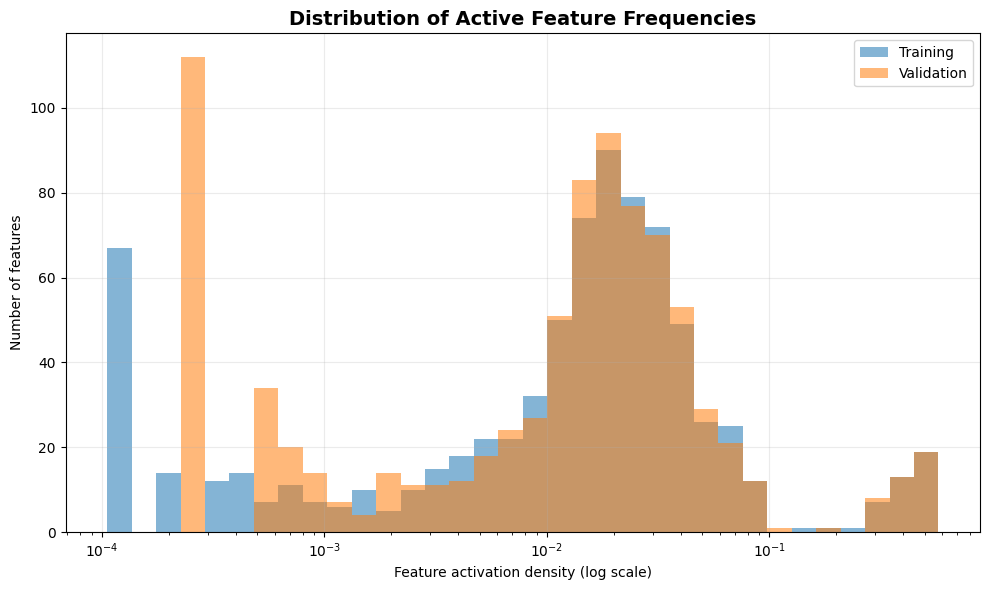


VISUALISATION SUITE COMPLETED: topk_4x_k32_seed123
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_4x_k32_seed123/figures
Support Jaccard: 0.8203
Top-20 activation share: 0.3239
Validation Gini: 0.8508

VISUALISATION: PASSED
Figures: 4
Support Jaccard: 0.8203125
Validation Gini: 0.850765938080547

RECOVERING: topk_4x_k64_seed42
TRAIN FEATURE COUNTS
  Density array: 1203
  Training history: 1203
  Difference: 0

VALIDATION FEATURE COUNTS
  Density array: 1260
  Validation history: 1260
  Consistency: PASSED

SUMMARY RECOVERY: PASSED
Best epoch: 100
Validation MSE: 0.0016729172079521

Generating visualisations...


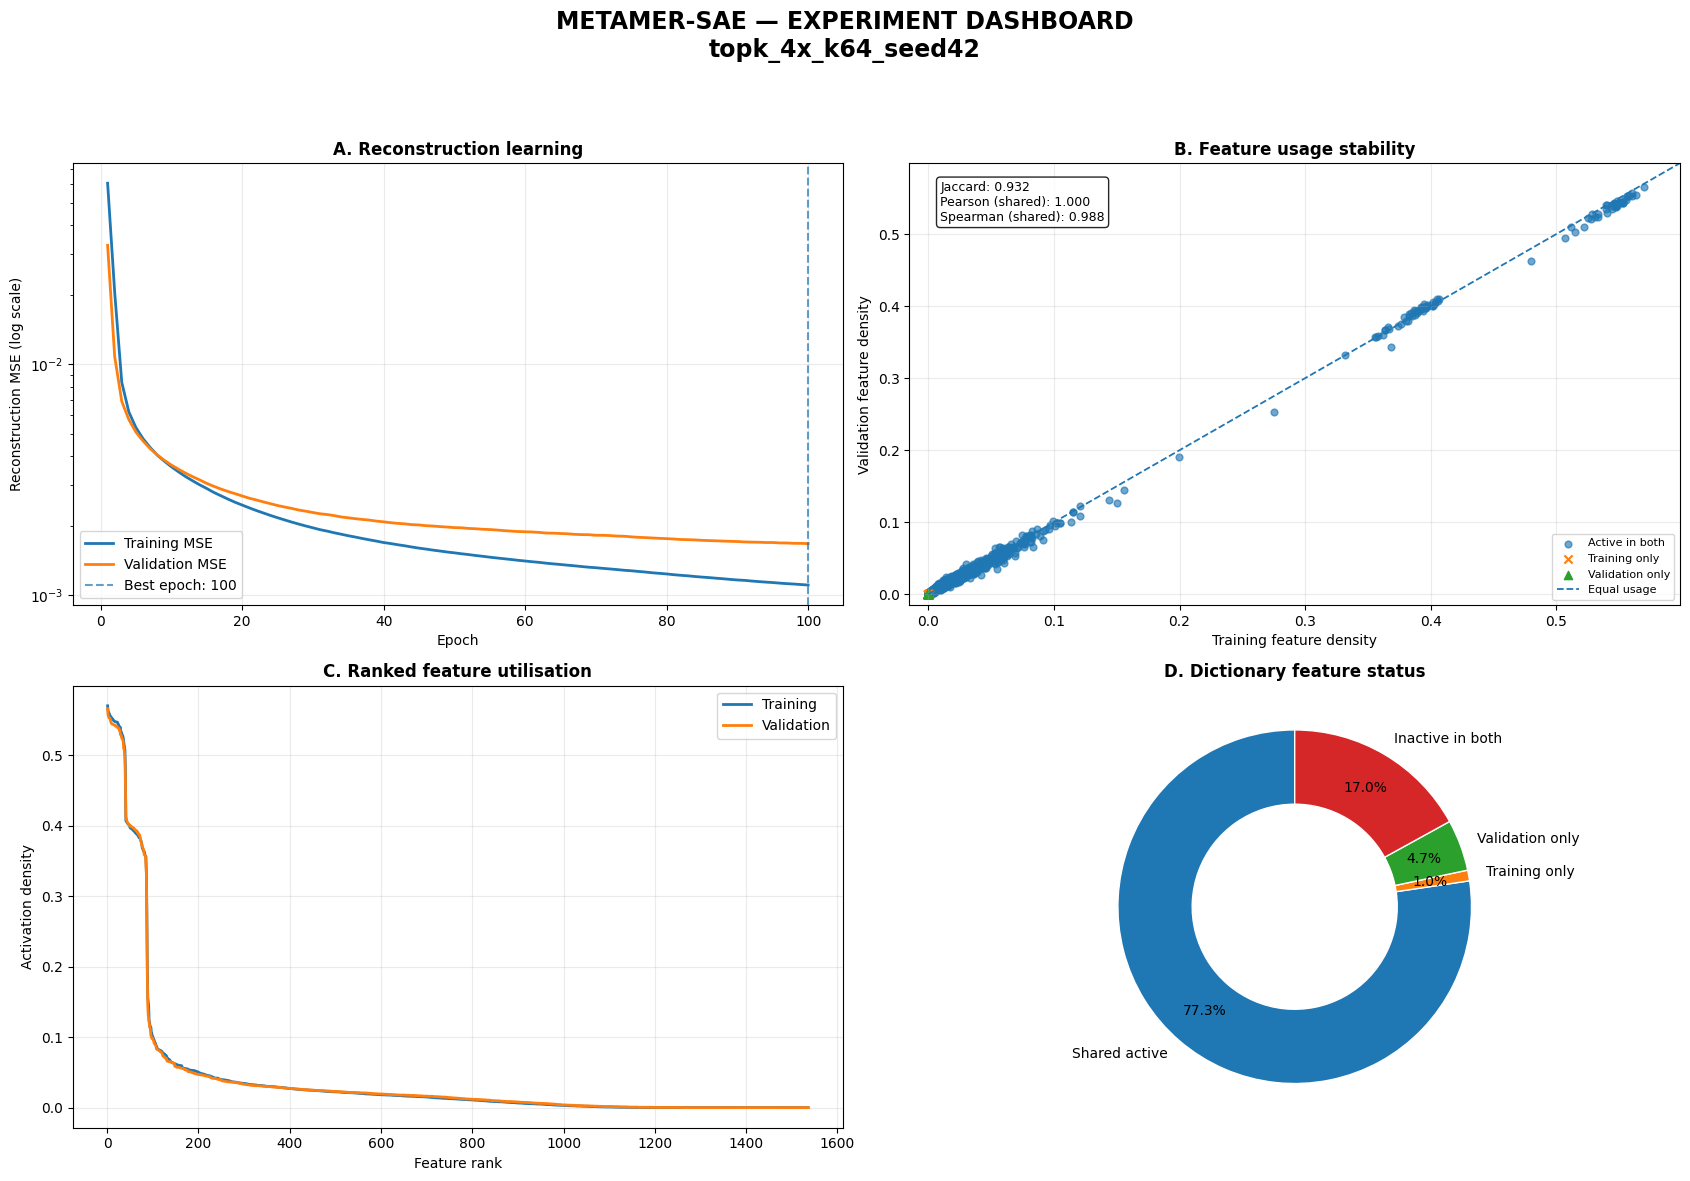

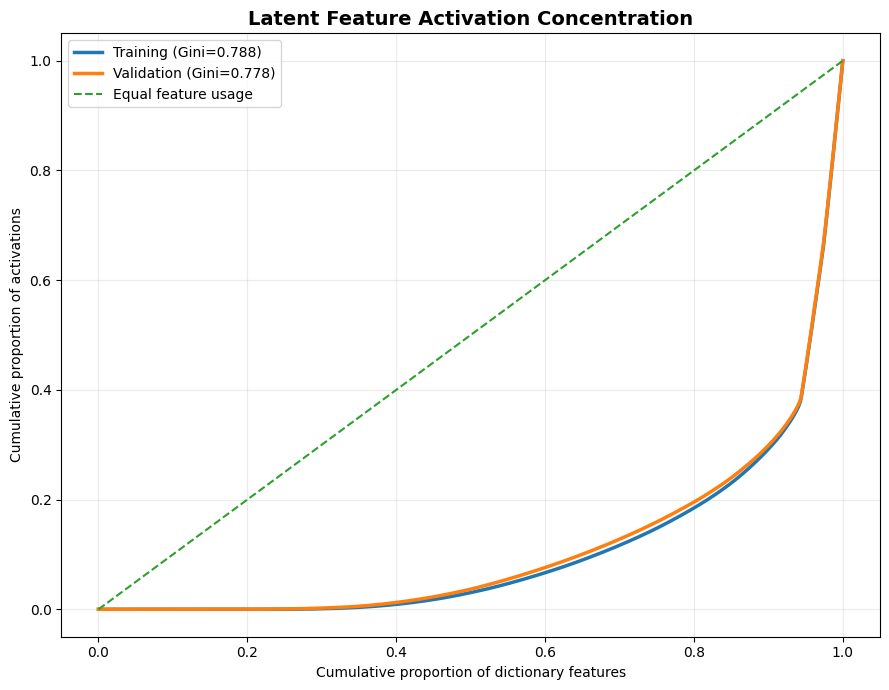

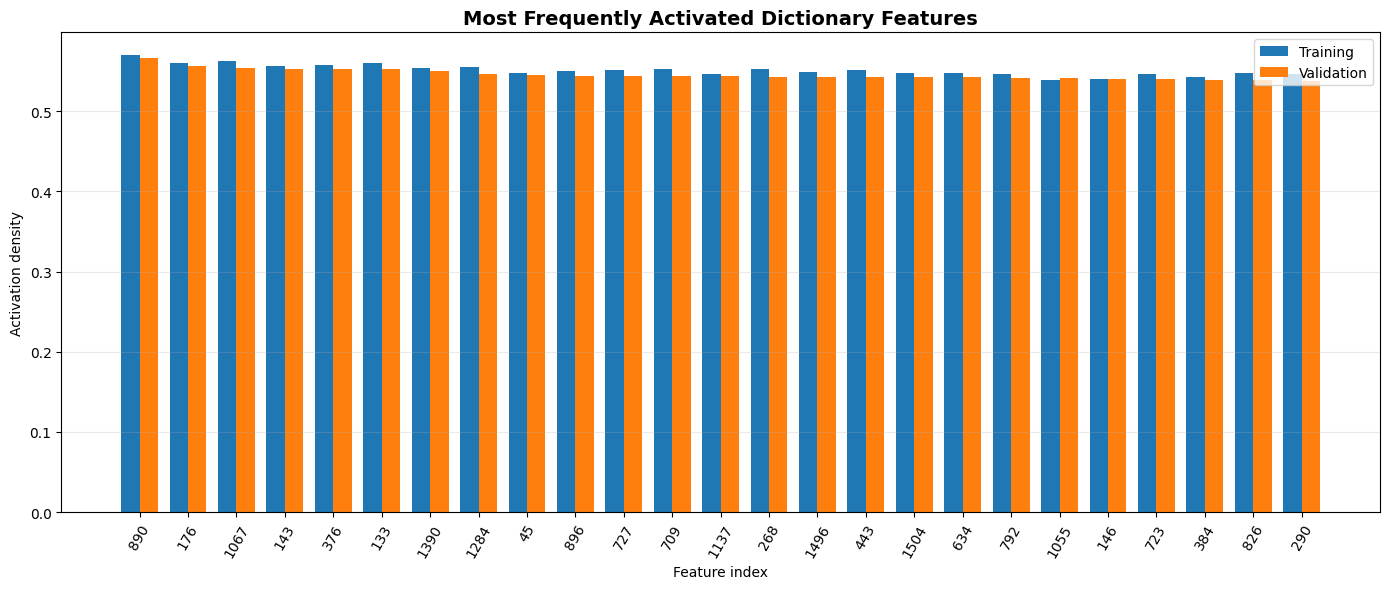

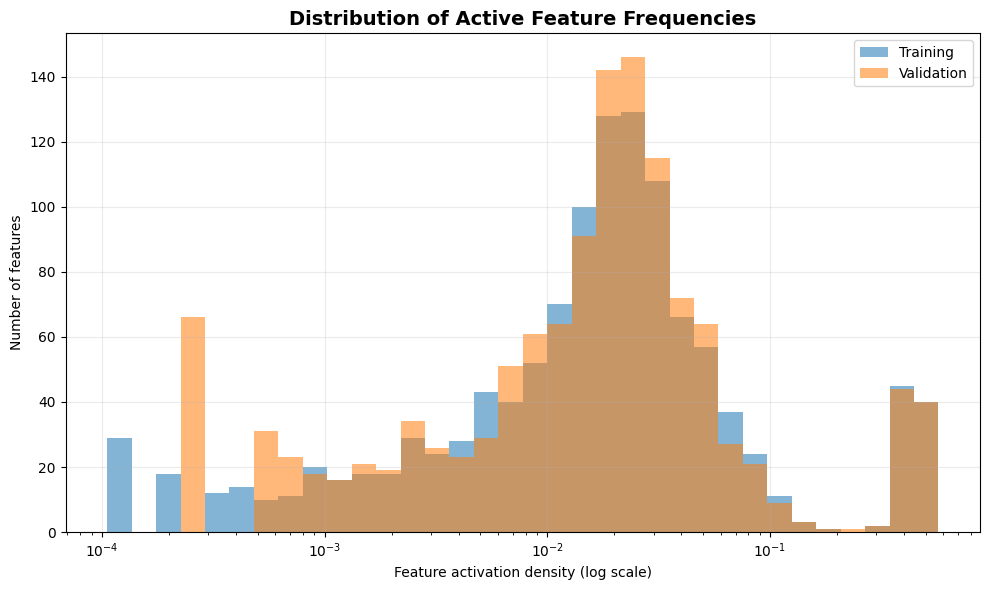


VISUALISATION SUITE COMPLETED: topk_4x_k64_seed42
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_4x_k64_seed42/figures
Support Jaccard: 0.9318
Top-20 activation share: 0.1711
Validation Gini: 0.7781

VISUALISATION: PASSED
Figures: 4
Support Jaccard: 0.9317647058823529
Validation Gini: 0.7781412138402333

RECOVERING: topk_4x_k64_seed123
TRAIN FEATURE COUNTS
  Density array: 1224
  Training history: 1218
  Difference: 6

VALIDATION FEATURE COUNTS
  Density array: 1263
  Validation history: 1263
  Consistency: PASSED

SUMMARY RECOVERY: PASSED
Best epoch: 100
Validation MSE: 0.001663633694451

Generating visualisations...


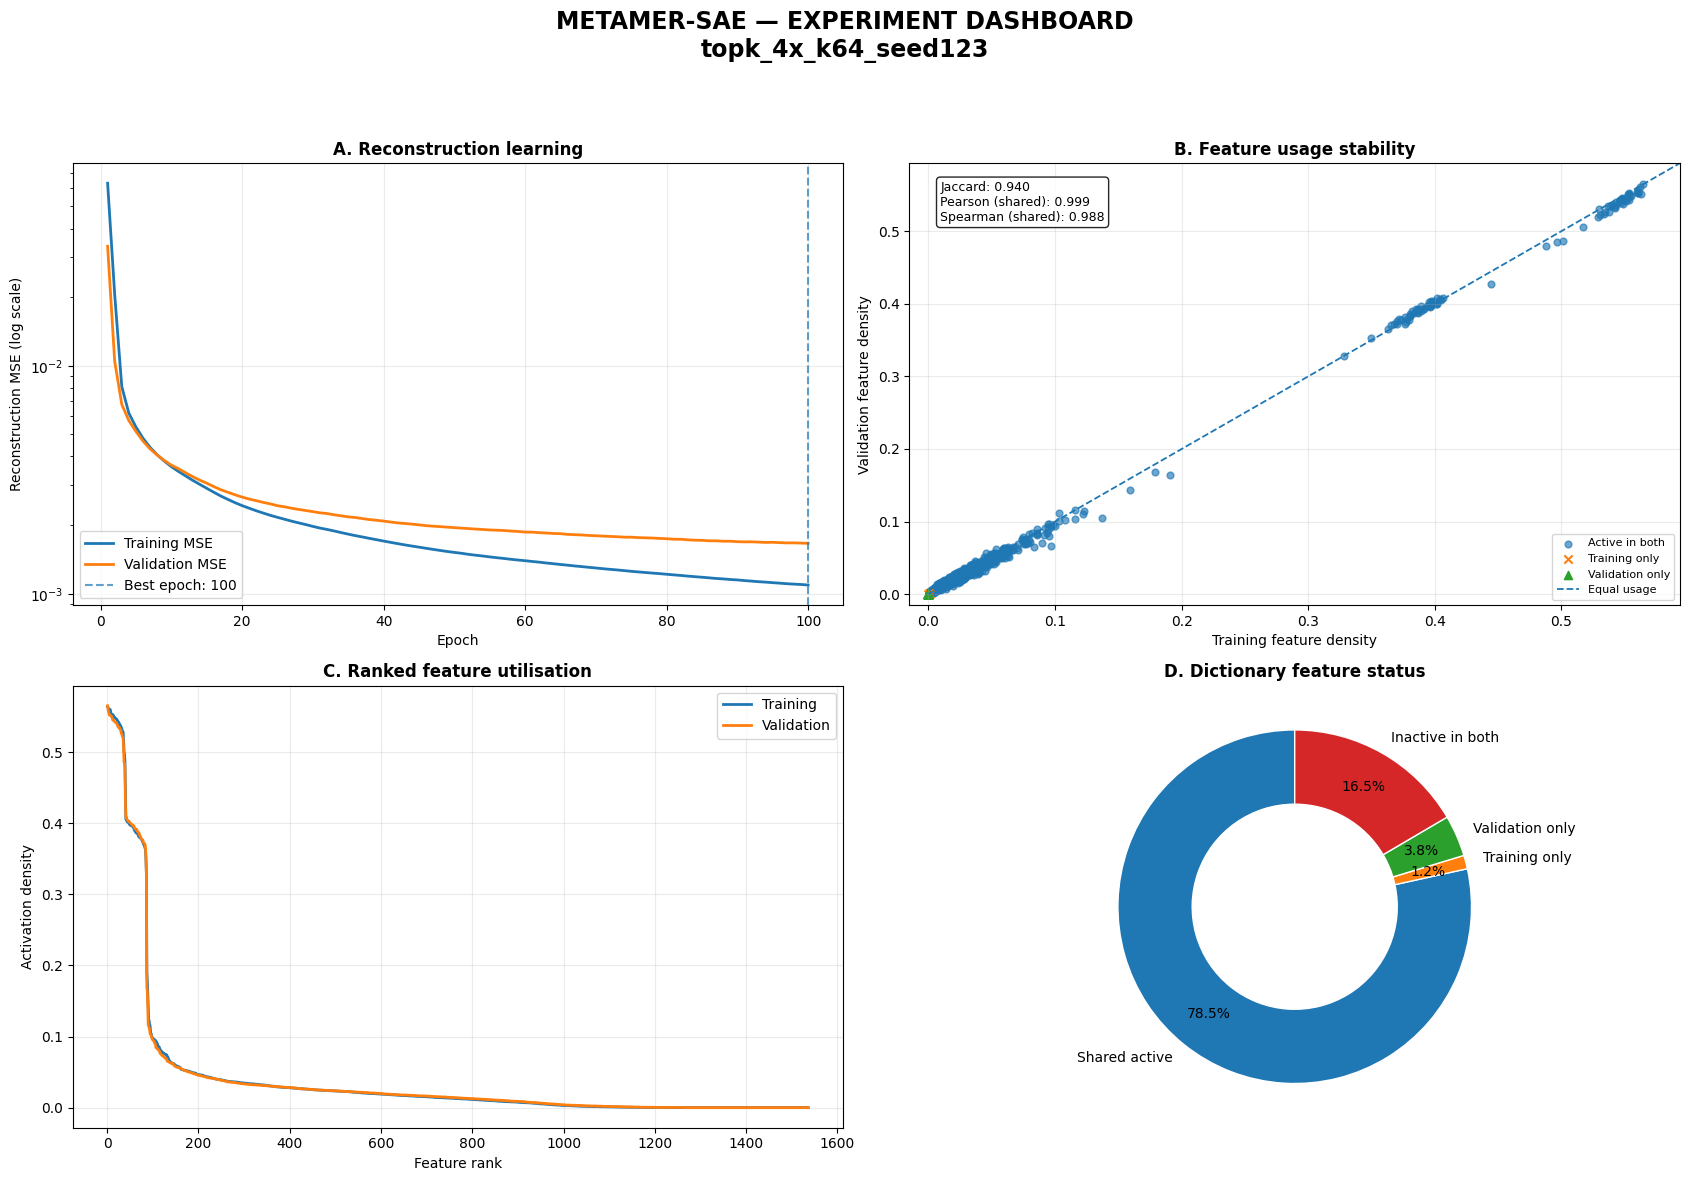

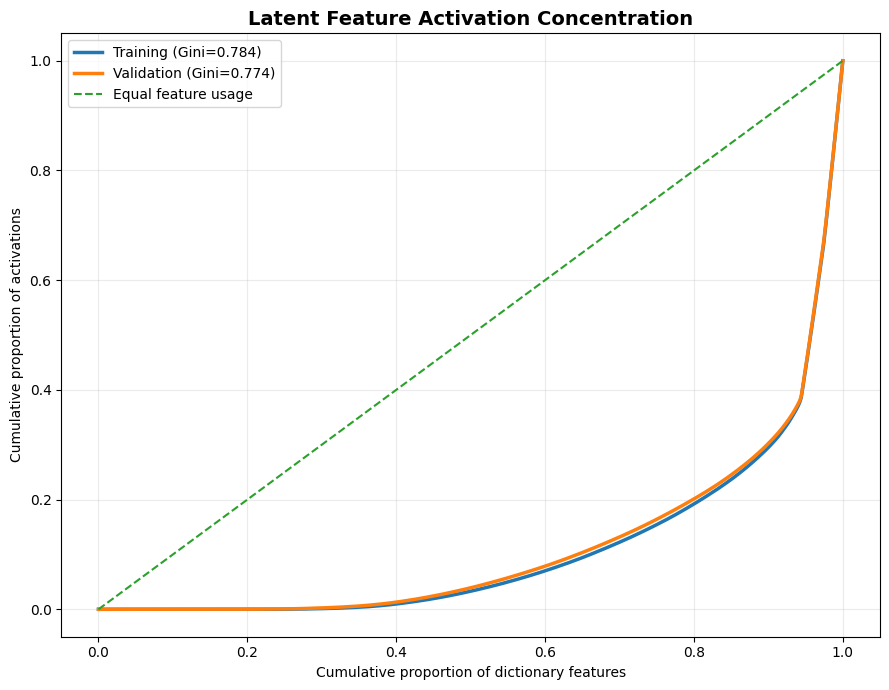

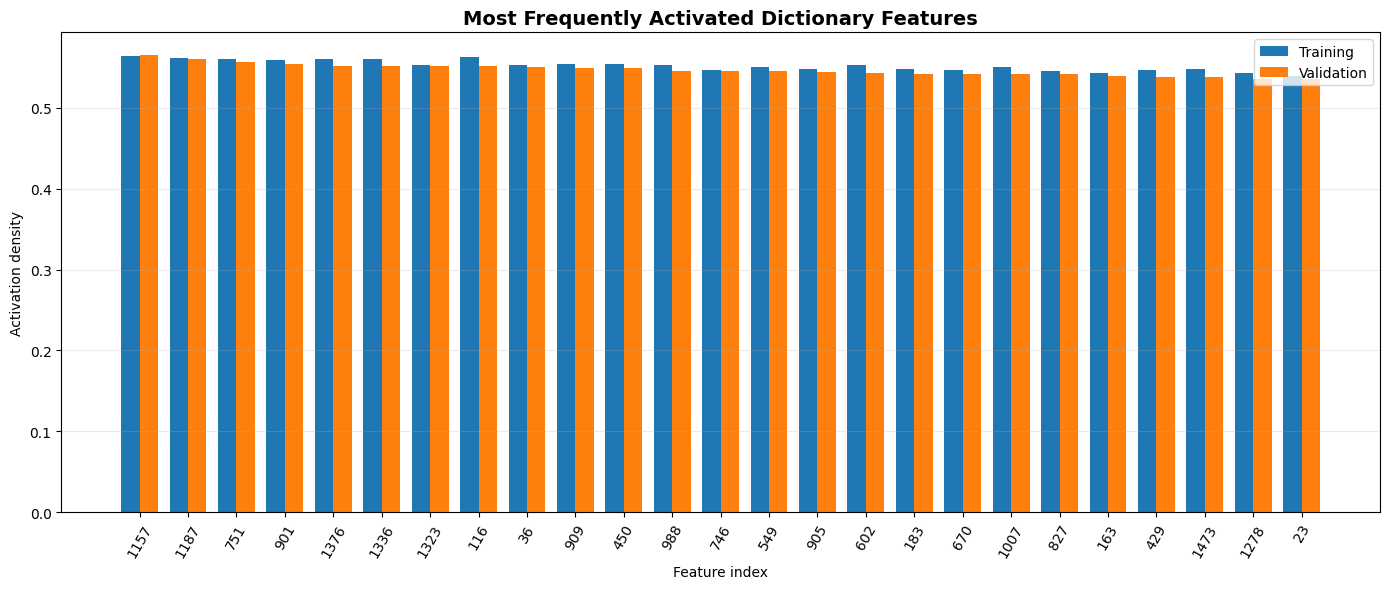

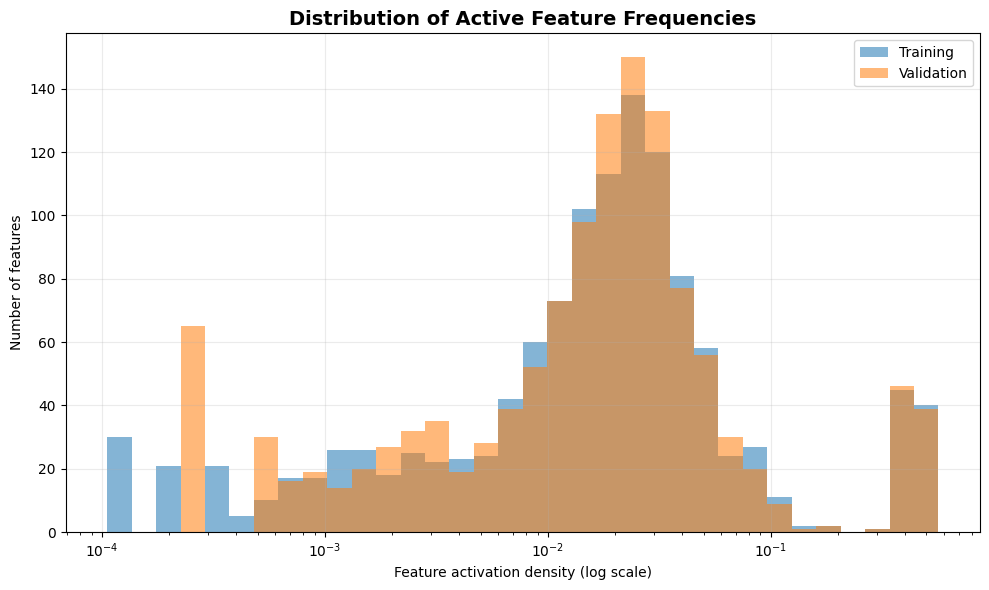


VISUALISATION SUITE COMPLETED: topk_4x_k64_seed123
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/topk_4x_k64_seed123/figures
Support Jaccard: 0.9399
Top-20 activation share: 0.1717
Validation Gini: 0.7743

VISUALISATION: PASSED
Figures: 4
Support Jaccard: 0.9399375975039002
Validation Gini: 0.774318956508758

EXPERIMENTS 5–8 — CORRECTED RECOVERY REPORT
topk_4x_k32_seed42             recovered_and_visualized
topk_4x_k32_seed123            recovered_and_visualized
topk_4x_k64_seed42             recovered_and_visualized
topk_4x_k64_seed123            recovered_and_visualized

Successful: 4 / 4
Failed: 0 / 4
Report: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/experiments_5_to_8_corrected_recovery.json

No training was performed.


In [ ]:
# ============================================================
# METAMER-SAE — CORRECTED EXPERIMENTS 5–8 RECOVERY
# No training. No checkpoint modification.
# Density arrays are used consistently for feature utilisation.
# History-derived training counts are retained separately.
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

RUN_IDS = [
    "topk_4x_k32_seed42",
    "topk_4x_k32_seed123",
    "topk_4x_k64_seed42",
    "topk_4x_k64_seed123",
]

REPORT_PATH = (
    TRAINING_ROOT / "experiments_5_to_8_corrected_recovery.json"
)


def save_json_atomic(data, path):
    path = Path(path)
    temp_path = path.with_suffix(".tmp")

    with open(temp_path, "w") as f:
        json.dump(data, f, indent=2)
        f.flush()

    temp_path.replace(path)


report = {
    "batch": "experiments_5_to_8",
    "status": "running",
    "training_performed": False,
    "feature_count_policy": (
        "Saved density arrays are authoritative for feature utilisation; "
        "history counts are retained separately."
    ),
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "runs": [],
}


for run_id in RUN_IDS:

    print("\n" + "=" * 75)
    print("RECOVERING:", run_id)
    print("=" * 75)

    run_dir = TRAINING_ROOT / run_id

    checkpoint_path = run_dir / "best_model.pt"
    config_path = run_dir / "run_config.json"
    history_path = run_dir / "training_history.csv"

    train_density_path = run_dir / "train_feature_density.npy"
    val_density_path = run_dir / "validation_feature_density.npy"

    summary_path = run_dir / "run_summary.json"

    record = {"run_id": run_id}

    try:
        # ----------------------------------------------------
        # A. VERIFY ORIGINAL ARTIFACTS
        # ----------------------------------------------------

        required = [
            checkpoint_path,
            config_path,
            history_path,
            train_density_path,
            val_density_path,
        ]

        missing = [str(p) for p in required if not p.is_file()]

        if missing:
            raise FileNotFoundError(str(missing))

        assert checkpoint_path.stat().st_size > 0

        # ----------------------------------------------------
        # B. LOAD CONFIGURATION AND HISTORY
        # ----------------------------------------------------

        with open(config_path, "r") as f:
            config = json.load(f)

        history = pd.read_csv(history_path)

        assert config["run_id"] == run_id
        assert len(history) == 100

        required_columns = [
            "epoch",
            "train_mse",
            "validation_mse",
            "validation_improvement_vs_zero_percent",
            "train_mean_l0",
            "validation_mean_l0",
            "train_active_features",
            "validation_active_features",
            "train_dead_feature_fraction",
            "validation_dead_feature_fraction",
            "epoch_seconds",
        ]

        for column in required_columns:
            assert column in history.columns, (
                f"{run_id}: missing column {column}"
            )

        # Absolute minimum validation MSE.
        best_index = history["validation_mse"].astype(float).idxmin()
        best_row = history.loc[best_index]

        best_epoch = int(best_row["epoch"])
        best_val_mse = float(best_row["validation_mse"])
        best_train_mse = float(best_row["train_mse"])

        # ----------------------------------------------------
        # C. LOAD FEATURE DENSITY ARRAYS
        # ----------------------------------------------------

        train_density = np.asarray(
            np.load(train_density_path)
        ).reshape(-1)

        val_density = np.asarray(
            np.load(val_density_path)
        ).reshape(-1)

        dictionary_size = int(config["dictionary_size"])

        assert train_density.size == dictionary_size
        assert val_density.size == dictionary_size

        assert np.isfinite(train_density).all()
        assert np.isfinite(val_density).all()

        assert (train_density >= 0).all()
        assert (val_density >= 0).all()

        # Array-based feature support.
        train_active_array = int(np.count_nonzero(train_density > 0))
        val_active_array = int(np.count_nonzero(val_density > 0))

        train_dead_array = (
            1.0 - train_active_array / dictionary_size
        )

        val_dead_array = (
            1.0 - val_active_array / dictionary_size
        )

        # History-based feature counts, kept separately.
        train_active_history = int(
            best_row["train_active_features"]
        )

        val_active_history = int(
            best_row["validation_active_features"]
        )

        # Validation counts must agree.
        assert val_active_array == val_active_history, (
            f"{run_id}: validation feature-count mismatch: "
            f"array={val_active_array}, history={val_active_history}"
        )

        train_count_difference = (
            train_active_array - train_active_history
        )

        print("TRAIN FEATURE COUNTS")
        print("  Density array:", train_active_array)
        print("  Training history:", train_active_history)
        print("  Difference:", train_count_difference)

        print("\nVALIDATION FEATURE COUNTS")
        print("  Density array:", val_active_array)
        print("  Validation history:", val_active_history)
        print("  Consistency: PASSED")

        # ----------------------------------------------------
        # D. RECONSTRUCT SUMMARY
        # ----------------------------------------------------

        improvement = float(
            best_row["validation_improvement_vs_zero_percent"]
        )

        zero_baseline = (
            best_val_mse / (1.0 - improvement / 100.0)
        )

        training_seconds = float(
            history["epoch_seconds"].astype(float).sum()
        )

        summary = {
            "status": "completed",
            "run_id": run_id,

            "expansion_factor": int(config["expansion_factor"]),
            "dictionary_size": dictionary_size,
            "top_k": int(config["top_k"]),
            "seed": int(config["random_seed"]),

            "best_epoch": best_epoch,
            "epochs_completed": int(len(history)),

            "checkpoint_selection_policy": config[
                "checkpoint_selection_policy"
            ],

            "best_validation_mse": best_val_mse,
            "best_training_mse": best_train_mse,

            "validation_zero_baseline_mse": float(zero_baseline),
            "validation_improvement_vs_zero_percent": improvement,

            "training_mean_l0": float(best_row["train_mean_l0"]),
            "validation_mean_l0": float(
                best_row["validation_mean_l0"]
            ),

            # Feature utilisation based on saved density arrays.
            "training_active_features": train_active_array,
            "validation_active_features": val_active_array,

            "training_dead_feature_fraction": float(train_dead_array),
            "validation_dead_feature_fraction": float(val_dead_array),

            # Preserve the separate history-derived training metrics.
            "training_active_features_from_history_at_best_epoch":
                train_active_history,

            "training_dead_feature_fraction_from_history_at_best_epoch":
                float(best_row["train_dead_feature_fraction"]),

            "training_density_array_minus_history_active_features":
                train_count_difference,

            "feature_utilisation_source":
                "saved_train_and_validation_feature_density_arrays",

            "training_seconds": training_seconds,

            "checkpoint": str(checkpoint_path),
            "training_history": str(history_path),

            "primary_evaluation_loaded": bool(
                config.get("primary_evaluation_loaded", False)
            ),

            "reserve_loaded": bool(
                config.get("reserve_loaded", False)
            ),
        }

        # ----------------------------------------------------
        # E. SAVE AND VERIFY SUMMARY
        # ----------------------------------------------------

        save_json_atomic(summary, summary_path)

        with open(summary_path, "r") as f:
            verified_summary = json.load(f)

        assert verified_summary["run_id"] == run_id
        assert verified_summary["status"] == "completed"

        assert np.isclose(
            verified_summary["best_validation_mse"],
            best_val_mse,
            rtol=1e-9,
            atol=1e-12,
        )

        assert (
            verified_summary["training_active_features"]
            == train_active_array
        )

        assert (
            verified_summary["validation_active_features"]
            == val_active_array
        )

        print("\nSUMMARY RECOVERY: PASSED")
        print("Best epoch:", best_epoch)
        print("Validation MSE:", best_val_mse)

        # ----------------------------------------------------
        # F. GENERATE VISUALISATIONS
        # ----------------------------------------------------

        print("\nGenerating visualisations...")

        metrics = generate_run_visualizations(run_id)

        figure_dir = run_dir / "figures"
        figures = sorted(figure_dir.glob("*.png"))

        assert len(figures) >= 4, (
            f"Expected four figures; found {len(figures)}"
        )

        record.update({
            "status": "recovered_and_visualized",
            "best_epoch": best_epoch,
            "validation_mse": best_val_mse,

            "training_active_features_from_density":
                train_active_array,

            "training_active_features_from_history":
                train_active_history,

            "validation_active_features":
                val_active_array,

            "training_count_difference":
                train_count_difference,

            "validation_dead_feature_fraction":
                val_dead_array,

            "visualization_metrics": metrics,

            "figures": [p.name for p in figures],
        })

        print("\nVISUALISATION: PASSED")
        print("Figures:", len(figures))
        print("Support Jaccard:", metrics["support_jaccard"])
        print("Validation Gini:", metrics["validation_gini"])

    except Exception as exc:

        record.update({
            "status": "failed",
            "error": str(exc),
        })

        print("\nFAILED:", str(exc))

    report["runs"].append(record)

    # Save progress after every run.
    save_json_atomic(report, REPORT_PATH)


# ------------------------------------------------------------
# G. FINAL REPORT
# ------------------------------------------------------------

successful = [
    r for r in report["runs"]
    if r["status"] == "recovered_and_visualized"
]

failed = [
    r for r in report["runs"]
    if r["status"] == "failed"
]

report["successful_count"] = len(successful)
report["failed_count"] = len(failed)
report["status"] = (
    "complete" if len(successful) == 4 else "incomplete"
)

save_json_atomic(report, REPORT_PATH)

print("\n" + "=" * 75)
print("EXPERIMENTS 5–8 — CORRECTED RECOVERY REPORT")
print("=" * 75)

for item in report["runs"]:
    print(
        f"{item['run_id']:<30} "
        f"{item['status']}"
    )

print("\nSuccessful:", len(successful), "/ 4")
print("Failed:", len(failed), "/ 4")
print("Report:", REPORT_PATH)
print("\nNo training was performed.")
print("=" * 75)


## Consolidated comparison and convergence audit

METAMER-SAE — MASTER EXPERIMENT COMPARISON
Feature-count agreement: PASSED

FEATURE-COUNT DISCREPANCY DETECTED
Run: topk_2x_k16_seed123
Training: density array = 310 | history = 313 | difference = -3
Validation: density array = 309 | history = 304 | difference = 5

FEATURE-COUNT DISCREPANCY DETECTED
Run: topk_2x_k32_seed42
Training: density array = 513 | history = 515 | difference = -2
Validation: density array = 528 | history = 540 | difference = -12

FEATURE-COUNT DISCREPANCY DETECTED
Run: topk_2x_k32_seed123
Training: density array = 499 | history = 494 | difference = 5
Validation: density array = 535 | history = 535 | difference = 0

FEATURE-COUNT DISCREPANCY DETECTED
Run: topk_4x_k32_seed42
Training: density array = 746 | history = 747 | difference = -1
Validation: density array = 808 | history = 808 | difference = 0

FEATURE-COUNT DISCREPANCY DETECTED
Run: topk_4x_k32_seed123
Training: density array = 791 | history = 782 | difference = 9
Validation: density array = 840 | history 

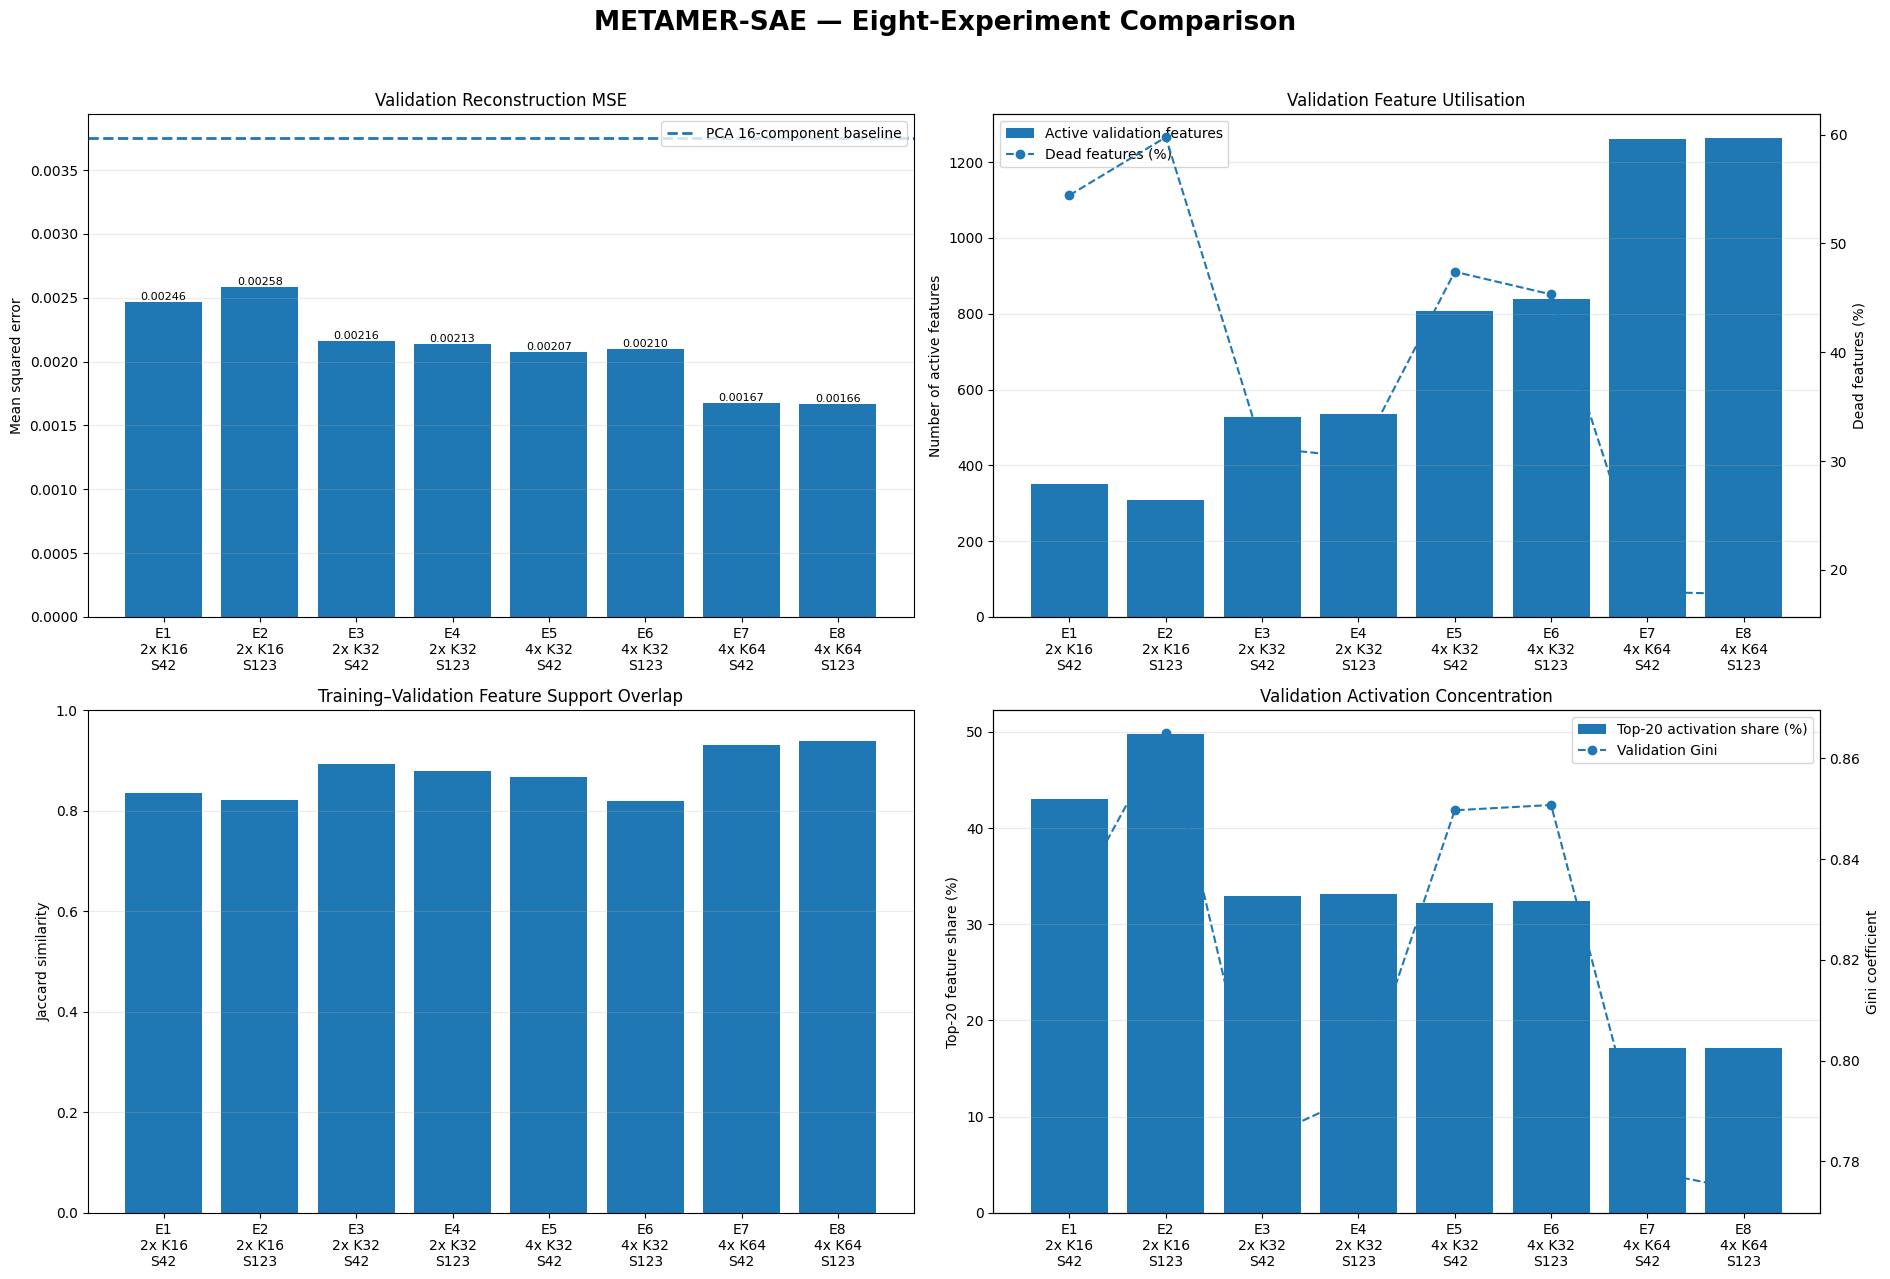


EIGHT-EXPERIMENT RESULTS
 experiment configuration  seed  validation_mse  validation_active_features  validation_active_features_history  validation_active_count_difference  validation_dead_feature_fraction  support_jaccard_train_validation  top20_validation_activation_share  validation_gini
          1        2x_K16    42         0.00246                         350                                 350                                   0                           0.54427                           0.83558                            0.43068          0.83009
          2        2x_K16   123         0.00258                         309                                 304                                   5                           0.59766                           0.82059                            0.49753          0.86502
          3        2x_K32    42         0.00216                         528                                 540                                 -12                       

In [ ]:

# ============================================================
# METAMER-SAE — MASTER EIGHT-EXPERIMENT COMPARISON
# Reconstruction | Feature utilisation | Stability | Convergence
# No model training. No checkpoint modification.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

RUN_IDS = [
    "topk_2x_k16_seed42",
    "topk_2x_k16_seed123",
    "topk_2x_k32_seed42",
    "topk_2x_k32_seed123",
    "topk_4x_k32_seed42",
    "topk_4x_k32_seed123",
    "topk_4x_k64_seed42",
    "topk_4x_k64_seed123",
]

# Fresh-checkpoint validation MSE values already verified
# for the first four historical experiments.
FRESH_MSE = {
    "topk_2x_k16_seed42": 0.002464380887912432,
    "topk_2x_k16_seed123": 0.0025848436043568097,
    "topk_2x_k32_seed42": 0.0021595333425541686,
    "topk_2x_k32_seed123": 0.0021336685251563217,
}

PCA_VALIDATION_MSE = 0.00374890

OUTPUT_DIR = TRAINING_ROOT / "comparison_eight_runs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("METAMER-SAE — MASTER EXPERIMENT COMPARISON")
print("=" * 80)

# ------------------------------------------------------------
# 1. LOAD AND VERIFY ALL RUNS
# ------------------------------------------------------------

run_records = []
convergence_records = []

for run_id in RUN_IDS:

    run_dir = TRAINING_ROOT / run_id
    summary_path = run_dir / "run_summary.json"
    config_path = run_dir / "run_config.json"
    history_path = run_dir / "training_history.csv"
    metrics_path = run_dir / "figures" / "visualization_metrics.json"

    required = [
        summary_path,
        config_path,
        history_path,
        metrics_path,
        run_dir / "best_model.pt",
        run_dir / "train_feature_density.npy",
        run_dir / "validation_feature_density.npy",
    ]

    missing = [str(p) for p in required if not p.is_file()]

    if missing:
        raise FileNotFoundError(
            f"{run_id}: missing required files:\n" + "\n".join(missing)
        )

    with open(summary_path, "r") as f:
        summary = json.load(f)

    with open(config_path, "r") as f:
        config = json.load(f)

    with open(metrics_path, "r") as f:
        visual = json.load(f)

    history = pd.read_csv(history_path)

    train_density = np.load(
        run_dir / "train_feature_density.npy"
    ).reshape(-1)

    val_density = np.load(
        run_dir / "validation_feature_density.npy"
    ).reshape(-1)

    assert summary["run_id"] == run_id
    assert config["run_id"] == run_id
    assert np.isfinite(train_density).all()
    assert np.isfinite(val_density).all()

    # Use validation checkpoint MSE consistently.
    validation_mse = FRESH_MSE.get(
        run_id,
        float(history["validation_mse"].min())
    )

    # Density arrays are the consistent source for feature support.
    train_active_array = int(np.count_nonzero(train_density > 0))
    val_active_array = int(np.count_nonzero(val_density > 0))

    best_index = history["validation_mse"].astype(float).idxmin()
    best_row = history.loc[best_index]

    history_train_active = int(
        best_row["train_active_features"]
    )

    history_val_active = int(
        best_row["validation_active_features"]
    )

    # --------------------------------------------------------
    # RECORD FEATURE-COUNT DISCREPANCIES
    # Do not abort the comparison when independent artifacts
    # disagree. Retain both measurements for auditability.
    # --------------------------------------------------------

    train_count_difference = (
        train_active_array - history_train_active
    )

    val_count_difference = (
        val_active_array - history_val_active
    )

    if train_count_difference != 0 or val_count_difference != 0:
        print("\nFEATURE-COUNT DISCREPANCY DETECTED")
        print("Run:", run_id)
        print(
            "Training: density array =", train_active_array,
            "| history =", history_train_active,
            "| difference =", train_count_difference
        )
        print(
            "Validation: density array =", val_active_array,
            "| history =", history_val_active,
            "| difference =", val_count_difference
        )
    else:
        print("Feature-count agreement: PASSED")

    dictionary_size = int(config["dictionary_size"])

    train_dead = 1 - train_active_array / dictionary_size
    val_dead = 1 - val_active_array / dictionary_size

    training_count_difference = (
        train_active_array - history_train_active
    )

    expansion = int(config["expansion_factor"])
    top_k = int(config["top_k"])
    seed = int(config["random_seed"])

    # Configuration groups allow matched-active-fraction comparisons.
    configuration = f"{expansion}x_K{top_k}"

    support_jaccard = visual.get("support_jaccard", np.nan)
    top20_share = visual.get(
        "top20_validation_activation_share", np.nan
    )
    top50_share = visual.get(
        "top50_validation_activation_share", np.nan
    )
    validation_gini = visual.get("validation_gini", np.nan)

    record = {
        "run_id": run_id,
        "experiment": len(run_records) + 1,
        "configuration": configuration,
        "expansion_factor": expansion,
        "dictionary_size": dictionary_size,
        "top_k": top_k,
        "nominal_active_fraction": top_k / dictionary_size,
        "seed": seed,

        "validation_mse": validation_mse,
        "pca_validation_mse": PCA_VALIDATION_MSE,
        "mse_improvement_vs_pca_percent": (
            1 - validation_mse / PCA_VALIDATION_MSE
        ) * 100,

        "training_active_features_array": train_active_array,
        "training_active_features_history": history_train_active,
        "training_active_count_difference": training_count_difference,

        "validation_active_features": val_active_array,
        "validation_dead_feature_fraction": val_dead,

        "training_dead_feature_fraction_array": train_dead,

        "support_jaccard_train_validation": support_jaccard,
        "top20_validation_activation_share": top20_share,
        "top50_validation_activation_share": top50_share,
        "validation_gini": validation_gini,

        "training_active_features_history": history_train_active,
        "validation_active_features_history": history_val_active,

        "training_active_count_difference": train_count_difference,
        "validation_active_count_difference": val_count_difference,
    }

    run_records.append(record)

    # --------------------------------------------------------
    # CONVERGENCE INFORMATION
    # --------------------------------------------------------

    epochs_completed = len(history)
    last_epoch = int(history.iloc[-1]["epoch"])

    best_epoch = int(best_row["epoch"])
    best_history_mse = float(best_row["validation_mse"])

    # Find epoch-90 MSE where available.
    epoch_90_rows = history[history["epoch"] == 90]

    mse_epoch_90 = (
        float(epoch_90_rows.iloc[0]["validation_mse"])
        if len(epoch_90_rows)
        else np.nan
    )

    final_history_mse = float(
        history.iloc[-1]["validation_mse"]
    )

    last_10_epoch_reduction_pct = (
        (mse_epoch_90 - final_history_mse) / mse_epoch_90 * 100
        if np.isfinite(mse_epoch_90) and mse_epoch_90 != 0
        else np.nan
    )

    convergence_records.append({
        "run_id": run_id,
        "best_history_epoch": best_epoch,
        "epochs_completed": epochs_completed,
        "best_validation_mse_in_history": best_history_mse,
        "epoch_90_validation_mse": mse_epoch_90,
        "final_validation_mse": final_history_mse,
        "last_10_epoch_reduction_percent":
            last_10_epoch_reduction_pct,
        "best_epoch_at_training_boundary":
            best_epoch == last_epoch,
        "training_array_history_count_difference":
            training_count_difference,
    })


results = pd.DataFrame(run_records)
convergence = pd.DataFrame(convergence_records)

# ------------------------------------------------------------
# 2. CONFIGURATION-LEVEL COMPARISON
# ------------------------------------------------------------

configuration_summary = (
    results.groupby("configuration")
    .agg(
        seeds=("seed", "count"),
        mean_validation_mse=("validation_mse", "mean"),
        std_validation_mse=("validation_mse", "std"),
        mean_validation_active_features=(
            "validation_active_features", "mean"
        ),
        mean_validation_dead_fraction=(
            "validation_dead_feature_fraction", "mean"
        ),
        mean_support_jaccard=(
            "support_jaccard_train_validation", "mean"
        ),
        mean_top20_activation_share=(
            "top20_validation_activation_share", "mean"
        ),
        mean_validation_gini=("validation_gini", "mean"),
        mean_mse_improvement_vs_pca=(
            "mse_improvement_vs_pca_percent", "mean"
        ),
    )
    .reset_index()
)

# Seed agreement metrics within each configuration.
seed_records = []

for configuration, group in results.groupby("configuration"):

    group = group.sort_values("seed")

    if len(group) != 2:
        continue

    seed_a, seed_b = group.iloc[0], group.iloc[1]

    mean_mse = (
        seed_a["validation_mse"] + seed_b["validation_mse"]
    ) / 2

    seed_records.append({
        "configuration": configuration,
        "seed_1": int(seed_a["seed"]),
        "seed_2": int(seed_b["seed"]),
        "mean_validation_mse": mean_mse,
        "mse_difference_percent": (
            abs(
                seed_a["validation_mse"]
                - seed_b["validation_mse"]
            ) / mean_mse * 100
        ),
        "validation_active_feature_difference": abs(
            seed_a["validation_active_features"]
            - seed_b["validation_active_features"]
        ),
        "mean_train_validation_support_jaccard": (
            seed_a["support_jaccard_train_validation"]
            + seed_b["support_jaccard_train_validation"]
        ) / 2,
    })

seed_stability = pd.DataFrame(seed_records)

# ------------------------------------------------------------
# 3. SAVE TABLES AND JSON REPORT
# ------------------------------------------------------------

results_path = OUTPUT_DIR / "eight_experiment_comparison.csv"
config_path = OUTPUT_DIR / "configuration_comparison.csv"
seed_path = OUTPUT_DIR / "seed_stability_comparison.csv"
convergence_path = OUTPUT_DIR / "convergence_audit.csv"
report_path = OUTPUT_DIR / "eight_experiment_comparison.json"

results.to_csv(results_path, index=False)
configuration_summary.to_csv(config_path, index=False)
seed_stability.to_csv(seed_path, index=False)
convergence.to_csv(convergence_path, index=False)

report = {
    "project": "Metamer-SAE",
    "experiments": run_records,
    "configuration_comparison":
        configuration_summary.to_dict(orient="records"),
    "seed_stability":
        seed_stability.to_dict(orient="records"),
    "convergence_audit":
        convergence_records,
    "pca_validation_mse": PCA_VALIDATION_MSE,
    "notes": [
        "First four experiments use fresh-checkpoint validation MSE values.",
        "Experiments 5-8 use verified absolute minimum validation MSE.",
        "Feature support is calculated from saved density arrays.",
        "Training array/history count discrepancies are preserved.",
        "Validation active-feature counts match history for all eight runs.",
        "No Feather primary or reserve evaluation images were used.",
    ],
}

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

# ------------------------------------------------------------
# 4. CREATE CONSOLIDATED DASHBOARD
# ------------------------------------------------------------

labels = [
    f"E{r.experiment}\n{r.expansion_factor}x K{r.top_k}\nS{r.seed}"
    for r in results.itertuples()
]

fig, axes = plt.subplots(2, 2, figsize=(19, 13))
fig.suptitle(
    "METAMER-SAE — Eight-Experiment Comparison",
    fontsize=19,
    fontweight="bold"
)

x = np.arange(len(results))

# Panel 1: reconstruction
ax = axes[0, 0]

bars = ax.bar(x, results["validation_mse"])

ax.axhline(
    PCA_VALIDATION_MSE,
    linestyle="--",
    linewidth=2,
    label="PCA 16-component baseline"
)

ax.set_title("Validation Reconstruction MSE")
ax.set_ylabel("Mean squared error")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, results["validation_mse"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.5f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Panel 2: feature utilisation
ax = axes[0, 1]

bars = ax.bar(
    x,
    results["validation_active_features"],
    label="Active validation features"
)

ax.set_title("Validation Feature Utilisation")
ax.set_ylabel("Number of active features")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.grid(axis="y", alpha=0.25)

ax2 = ax.twinx()
ax2.plot(
    x,
    results["validation_dead_feature_fraction"] * 100,
    marker="o",
    linestyle="--",
    label="Dead features (%)"
)
ax2.set_ylabel("Dead features (%)")

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="best")

# Panel 3: train-validation support
ax = axes[1, 0]

ax.bar(
    x,
    results["support_jaccard_train_validation"]
)

ax.set_title("Training–Validation Feature Support Overlap")
ax.set_ylabel("Jaccard similarity")
ax.set_ylim(0, 1)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.grid(axis="y", alpha=0.25)

# Panel 4: concentration
ax = axes[1, 1]

ax.bar(
    x,
    results["top20_validation_activation_share"] * 100,
    label="Top-20 activation share (%)"
)

ax.set_title("Validation Activation Concentration")
ax.set_ylabel("Top-20 feature share (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.grid(axis="y", alpha=0.25)

ax2 = ax.twinx()
ax2.plot(
    x,
    results["validation_gini"],
    marker="o",
    linestyle="--",
    label="Validation Gini"
)
ax2.set_ylabel("Gini coefficient")

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="best")

fig.tight_layout(rect=[0, 0, 1, 0.96])

dashboard_path = (
    OUTPUT_DIR / "eight_experiment_comparison_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. PRINT MASTER RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("EIGHT-EXPERIMENT RESULTS")
print("=" * 80)

print(
    results[
        [
            "experiment",
            "configuration",
            "seed",
            "validation_mse",
            "validation_active_features",
            "validation_active_features_history",
            "validation_active_count_difference",
            "validation_dead_feature_fraction",
            "support_jaccard_train_validation",
            "top20_validation_activation_share",
            "validation_gini",
        ]
    ].round(5).to_string(index=False)
)

print("\n" + "=" * 80)
print("CONFIGURATION COMPARISON")
print("=" * 80)

print(configuration_summary.round(5).to_string(index=False))

print("\n" + "=" * 80)
print("SEED STABILITY")
print("=" * 80)

print(seed_stability.round(5).to_string(index=False))

print("\n" + "=" * 80)
print("CONVERGENCE AUDIT")
print("=" * 80)

print(convergence.round(6).to_string(index=False))

print("\n" + "=" * 80)
print("SAVED OUTPUTS")
print("=" * 80)

for path in [
    results_path,
    config_path,
    seed_path,
    convergence_path,
    report_path,
    dashboard_path,
]:
    print(path)

print("\nMASTER COMPARISON COMPLETE")
print("No model training was performed.")
print("=" * 80)


# Next step: inspect checkpoint structure

In [ ]:

# ============================================================
# METAMER-SAE — CHECKPOINT STRUCTURE INSPECTION
# Read-only. Does not load training data into a model,
# train, or modify any checkpoint.
# ============================================================

import torch
import inspect
from pathlib import Path
from torch.torch_version import TorchVersion

RUN_IDS = [
    "topk_2x_k16_seed42",
    "topk_2x_k16_seed123",
    "topk_2x_k32_seed42",
    "topk_2x_k32_seed123",
    "topk_4x_k32_seed42",
    "topk_4x_k32_seed123",
    "topk_4x_k64_seed42",
    "topk_4x_k64_seed123",
]

print("=" * 75)
print("METAMER-SAE — CHECKPOINT FORMAT INSPECTION")
print("=" * 75)

for run_id in RUN_IDS:

    checkpoint_path = (
        TRAINING_ROOT / run_id / "best_model.pt"
    )

    print("\n" + "-" * 75)
    print("RUN:", run_id)

    with torch.serialization.safe_globals([TorchVersion]):
      checkpoint = torch.load(
          checkpoint_path,
          map_location="cpu",
          weights_only=True
      )

    print("Checkpoint type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):

        print("Top-level keys:", list(checkpoint.keys())[:25])

        tensor_items = [
            (key, value)
            for key, value in checkpoint.items()
            if torch.is_tensor(value)
        ]

        print("Direct tensor entries:", len(tensor_items))

        for key, value in tensor_items[:8]:
            print(
                f"  {key}: "
                f"shape={tuple(value.shape)}, "
                f"dtype={value.dtype}"
            )

    else:
        print("Checkpoint is not a dictionary.")

# ------------------------------------------------------------
# MODEL INTERFACE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TOPK SAE MODEL INTERFACE")
print("=" * 75)

model = build_topk_sae(
    nb_concepts=1536,
    top_k=64,
    seed=42,
    device="cpu"
)

print("Model class:", type(model).__name__)
print("Forward signature:", inspect.signature(model.forward))

for attr in ["encode", "decode", "encoder", "decoder"]:
    print(
        f"Has {attr}:",
        hasattr(model, attr)
    )

print("\nEvaluation function signature:")
print(inspect.signature(evaluate_sae))

print("\nCheckpoint and model interface inspection completed.")


METAMER-SAE — CHECKPOINT FORMAT INSPECTION

---------------------------------------------------------------------------
RUN: topk_2x_k16_seed42
Checkpoint type: dict
Top-level keys: ['model_state_dict', 'run_config', 'best_epoch', 'best_validation_mse']
Direct tensor entries: 0

---------------------------------------------------------------------------
RUN: topk_2x_k16_seed123
Checkpoint type: dict
Top-level keys: ['model_state_dict', 'run_config', 'best_epoch', 'best_validation_mse']
Direct tensor entries: 0

---------------------------------------------------------------------------
RUN: topk_2x_k32_seed42
Checkpoint type: dict
Top-level keys: ['model_state_dict', 'run_config', 'best_epoch', 'best_validation_mse']
Direct tensor entries: 0

---------------------------------------------------------------------------
RUN: topk_2x_k32_seed123
Checkpoint type: dict
Top-level keys: ['model_state_dict', 'run_config', 'best_epoch', 'best_validation_mse']
Direct tensor entries: 0

----------

# Next diagnostic: verify checkpoint loading and model outputs

In [ ]:

# ============================================================
# METAMER-SAE — NESTED CHECKPOINT & MODEL API AUDIT
# Read-only: no training and no checkpoint modification.
# ============================================================

import torch
import inspect
import json

from pathlib import Path
from torch.torch_version import TorchVersion

RUN_IDS = [
    "topk_2x_k16_seed42",
    "topk_2x_k16_seed123",
    "topk_2x_k32_seed42",
    "topk_2x_k32_seed123",
    "topk_4x_k32_seed42",
    "topk_4x_k32_seed123",
    "topk_4x_k64_seed42",
    "topk_4x_k64_seed123",
]

print("=" * 80)
print("METAMER-SAE — NESTED CHECKPOINT & MODEL API AUDIT")
print("=" * 80)

# ------------------------------------------------------------
# 1. INSPECT AND STRICTLY LOAD ALL EIGHT STATE DICTIONARIES
# ------------------------------------------------------------

checkpoint_audit = []

for run_id in RUN_IDS:

    run_dir = TRAINING_ROOT / run_id
    checkpoint_path = run_dir / "best_model.pt"
    config_path = run_dir / "run_config.json"

    print("\n" + "-" * 80)
    print("RUN:", run_id)
    print("-" * 80)

    with open(config_path, "r") as f:
        config = json.load(f)

    with torch.serialization.safe_globals([TorchVersion]):
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

    assert "model_state_dict" in checkpoint

    state_dict = checkpoint["model_state_dict"]

    print("Nested state-dictionary type:", type(state_dict).__name__)
    print("State-dictionary entries:", len(state_dict))

    # Show representative parameter names and shapes.
    print("\nRepresentative parameters:")

    for key, value in list(state_dict.items())[:10]:
        if torch.is_tensor(value):
            print(
                f"  {key}: shape={tuple(value.shape)}, "
                f"dtype={value.dtype}"
            )
        else:
            print(f"  {key}: {type(value).__name__}")

    # Reconstruct the matching architecture.
    model = build_topk_sae(
        nb_concepts=int(config["dictionary_size"]),
        top_k=int(config["top_k"]),
        seed=int(config["random_seed"]),
        device="cpu"
    )

    # Strict loading checks that every model parameter and buffer
    # has a corresponding checkpoint entry, with matching shapes.
    load_result = model.load_state_dict(
        state_dict,
        strict=True
    )

    print("\nSTRICT LOAD: PASSED")
    print("Missing keys:", load_result.missing_keys)
    print("Unexpected keys:", load_result.unexpected_keys)

    checkpoint_audit.append({
        "run_id": run_id,
        "status": "strict_load_passed",
        "state_dict_entries": len(state_dict),
        "dictionary_size": int(config["dictionary_size"]),
        "top_k": int(config["top_k"]),
        "best_epoch": checkpoint["best_epoch"],
        "best_validation_mse": checkpoint["best_validation_mse"],
    })

    del checkpoint, state_dict, model

# ------------------------------------------------------------
# 2. INSPECT MODEL METHOD SIGNATURES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MODEL METHOD SIGNATURES")
print("=" * 80)

model = build_topk_sae(
    nb_concepts=1536,
    top_k=64,
    seed=42,
    device="cpu"
)

methods = ["forward", "encode", "decode"]

for method_name in methods:
    method = getattr(model, method_name, None)

    if method is None:
        print(method_name, ": NOT AVAILABLE")
    else:
        print(
            method_name,
            ":",
            inspect.signature(method)
        )

print("\nEvaluation function:")
print(inspect.signature(evaluate_sae))

# ------------------------------------------------------------
# 3. INSPECT METHOD SOURCE
# ------------------------------------------------------------

def print_method_source(label, method, max_chars=8000):

    print("\n" + "-" * 80)
    print(label)
    print("-" * 80)

    try:
        source = inspect.getsource(method)
        print(source[:max_chars])

        if len(source) > max_chars:
            print("\n[Source display truncated.]")

    except Exception as exc:
        print("Source unavailable:", repr(exc))


print_method_source(
    "TopKSAE.forward",
    type(model).forward
)

print_method_source(
    "TopKSAE.encode",
    model.encode
)

print_method_source(
    "TopKSAE.decode",
    model.decode
)

print_method_source(
    "evaluate_sae",
    evaluate_sae,
    max_chars=12000
)

# ------------------------------------------------------------
# 4. TEST ACTUAL MODEL OUTPUT STRUCTURE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SYNTHETIC FORWARD / ENCODE / DECODE SHAPE TEST")
print("=" * 80)

def describe_output(value, name="output", depth=0):

    indent = "  " * depth

    if torch.is_tensor(value):
        print(
            f"{indent}{name}: Tensor "
            f"shape={tuple(value.shape)}, "
            f"dtype={value.dtype}"
        )

    elif isinstance(value, dict):
        print(f"{indent}{name}: dict")

        for key, item in value.items():
            describe_output(item, str(key), depth + 1)

    elif isinstance(value, (tuple, list)):
        print(f"{indent}{name}: {type(value).__name__}")

        for index, item in enumerate(value):
            describe_output(item, f"[{index}]", depth + 1)

    elif value is None:
        print(f"{indent}{name}: None")

    else:
        print(f"{indent}{name}: {type(value).__name__}")


model.eval()

sample = torch.randn(4, 384, dtype=torch.float32)

with torch.inference_mode():

    try:
        forward_output = model(sample)
        describe_output(forward_output, "forward")
    except Exception as exc:
        forward_output = None
        print("Forward test failed:", repr(exc))

    try:
        encoded = model.encode(sample)
        describe_output(encoded, "encode")
    except Exception as exc:
        encoded = None
        print("Encode test failed:", repr(exc))

    if torch.is_tensor(encoded):

        try:
            decoded = model.decode(encoded)
            describe_output(decoded, "decode")
        except Exception as exc:
            print("Decode test failed:", repr(exc))

# ------------------------------------------------------------
# 5. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CHECKPOINT AND API AUDIT SUMMARY")
print("=" * 80)

print("Strictly loaded checkpoints:",
      len(checkpoint_audit), "/", len(RUN_IDS))

for result in checkpoint_audit:
    print(
        result["run_id"],
        "|",
        result["status"],
        "| entries:",
        result["state_dict_entries"]
    )

print("\nModel methods inspected: forward, encode, decode")
print("Evaluation function inspected: evaluate_sae")
print("No training performed.")
print("No checkpoint files modified.")
print("=" * 80)


METAMER-SAE — NESTED CHECKPOINT & MODEL API AUDIT

--------------------------------------------------------------------------------
RUN: topk_2x_k16_seed42
--------------------------------------------------------------------------------
Nested state-dictionary type: dict
State-dictionary entries: 4

Representative parameters:
  encoder.final_block.0.weight: shape=(768, 384), dtype=torch.float32
  encoder.final_block.0.bias: shape=(768,), dtype=torch.float32
  dictionary._weights: shape=(768, 384), dtype=torch.float32
  dictionary.multiplier: shape=(), dtype=torch.float32

STRICT LOAD: PASSED
Missing keys: []
Unexpected keys: []

--------------------------------------------------------------------------------
RUN: topk_2x_k16_seed123
--------------------------------------------------------------------------------
Nested state-dictionary type: dict
State-dictionary entries: 4

Representative parameters:
  encoder.final_block.0.weight: shape=(768, 384), dtype=torch.float32
  encoder.final

# Direct audit of all eight checkpoints

METAMER-SAE — DIRECT CHECKPOINT AUDIT
Device: cuda
GPU: Tesla T4

SOURCE ACTIVATION CHECK
Training: (9469, 384) float32
Validation: (3925, 384) float32

RUN 1/8: topk_2x_k16_seed42
Strict checkpoint loading: PASSED
Checkpoint epoch: 100

RECONSTRUCTION
Checkpoint validation MSE: 0.002464380887912432
Direct validation MSE: 0.0024643808109745097
Difference: -7.693792217905449e-11
MSE agreement: True

DIRECT FEATURE UTILISATION
Training active: 327
Validation active: 350
Training dead fraction: 0.57421875
Validation dead fraction: 0.5442708333333333

TRAINING COUNT CHECK
Checkpoint-epoch history: 331
Direct checkpoint audit: 327

VALIDATION COUNT CHECK
Checkpoint-epoch history: 350
Direct checkpoint audit: 350

SAVED ARRAY SUPPORT DIFFERENCES
Training support disagreements: 32
Validation support disagreements: 0

TRAIN/VALIDATION SUPPORT
Jaccard: 0.8446866485013624
Pearson: 0.9989744434220934
Spearman: 0.9892813916177475

RUN 2/8: topk_2x_k16_seed123
Strict checkpoint loading: PASSED
Chec

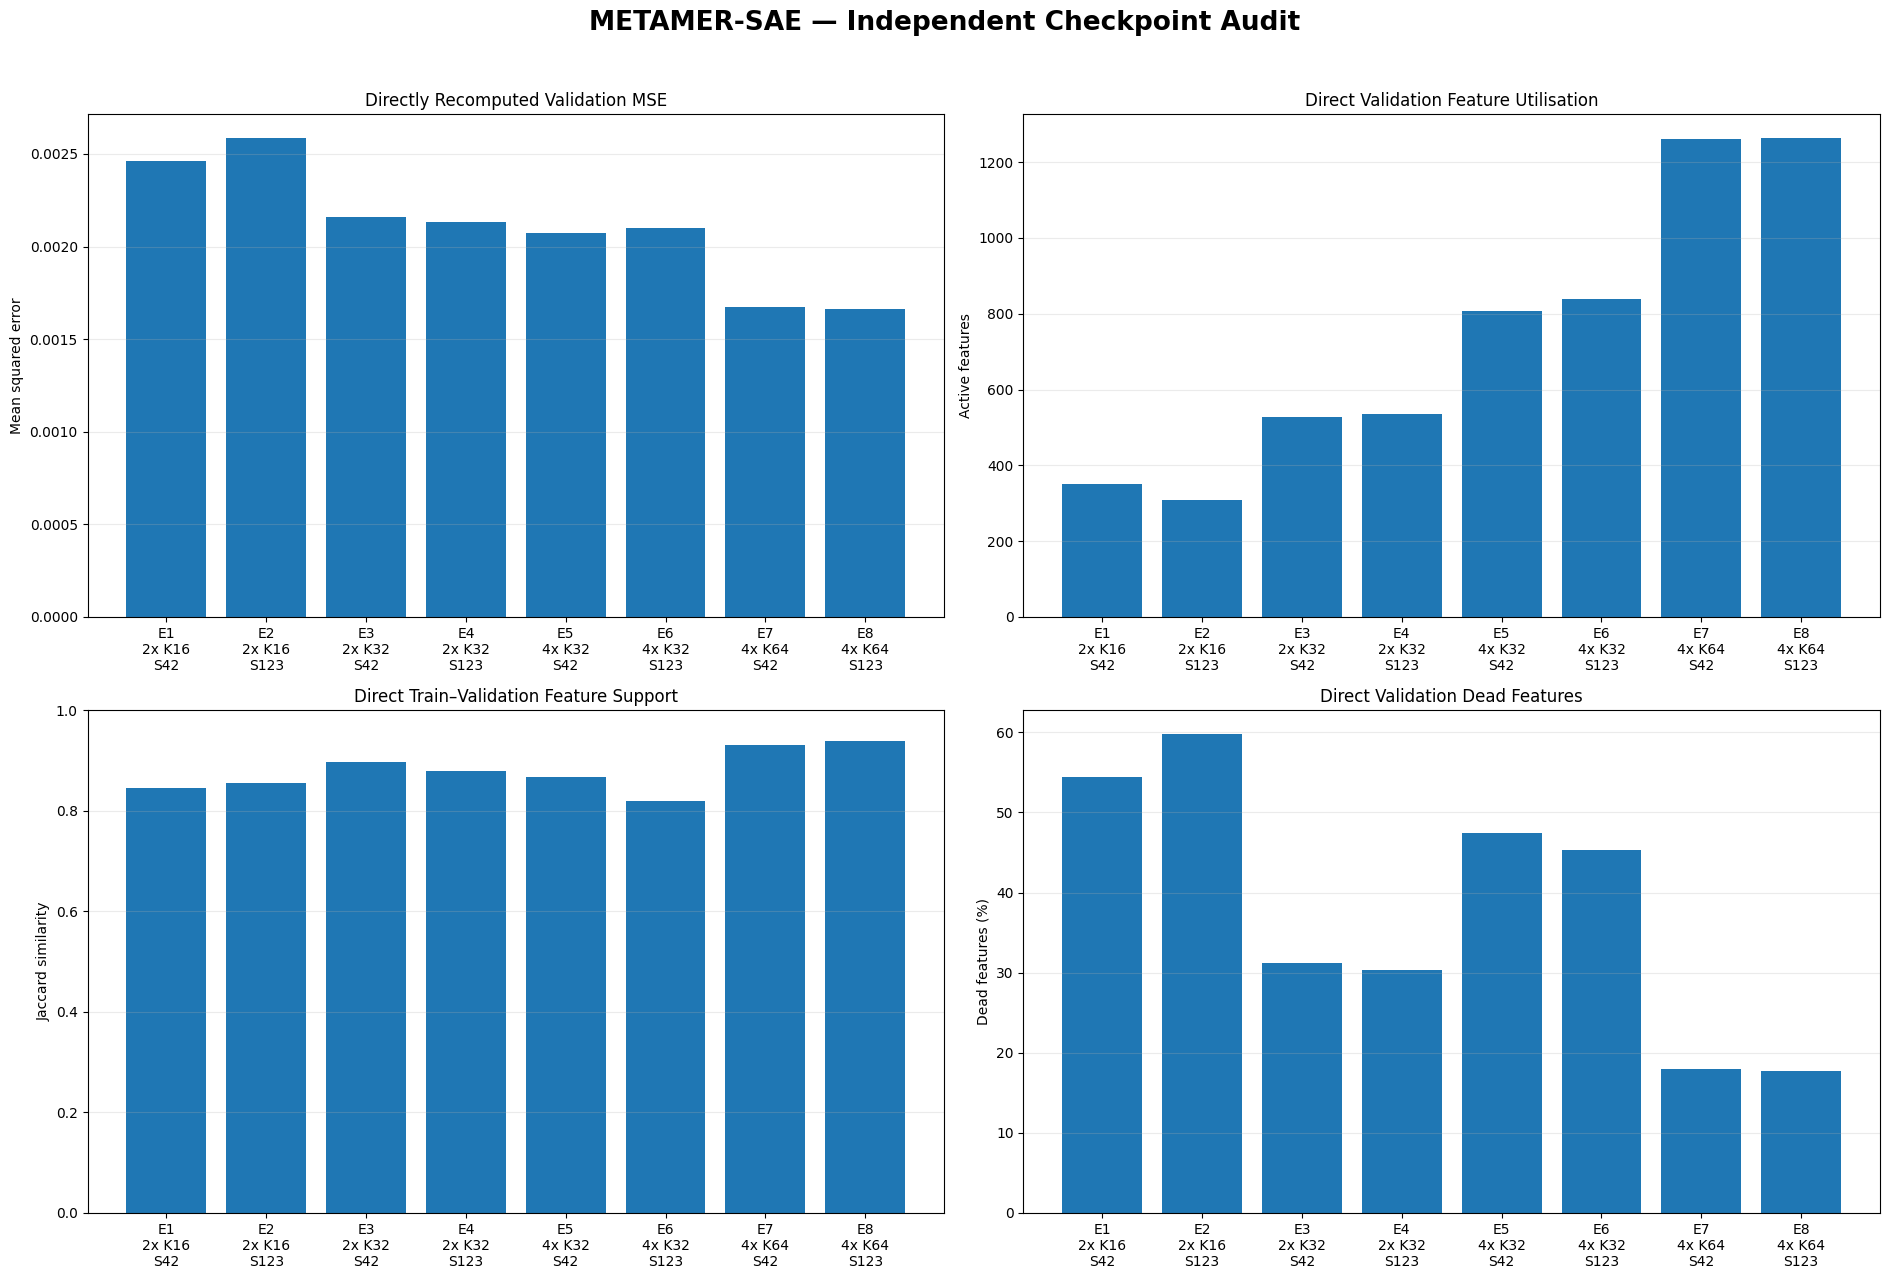


METAMER-SAE — DIRECT CHECKPOINT AUDIT RESULTS
             run_id  checkpoint_epoch  direct_validation_mse  validation_mse_matches_checkpoint  direct_training_active_features  direct_validation_active_features  direct_validation_dead_fraction  support_jaccard  saved_vs_direct_training_support_disagreement  saved_vs_direct_validation_support_disagreement
 topk_2x_k16_seed42               100               0.002464                               True                              327                                350                         0.544271         0.844687                                             32                                                0
topk_2x_k16_seed123                98               0.002585                               True                              303                                309                         0.597656         0.854545                                             43                                                0
 topk_2x_k32_seed42    

In [ ]:

# ============================================================
# METAMER-SAE — DIRECT CHECKPOINT AUDIT (ALL EIGHT RUNS)
# ============================================================
# Recomputes reconstruction and feature utilisation directly
# from each saved checkpoint and the original centered inputs.
#
# No training. No checkpoint modification.
# ============================================================

import gc
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime, timezone
from torch.torch_version import TorchVersion

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

RUN_IDS = [
    "topk_2x_k16_seed42",
    "topk_2x_k16_seed123",
    "topk_2x_k32_seed42",
    "topk_2x_k32_seed123",
    "topk_4x_k32_seed42",
    "topk_4x_k32_seed123",
    "topk_4x_k64_seed42",
    "topk_4x_k64_seed123",
]

AUDIT_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

AUDIT_BATCH_SIZE = 256

AUDIT_DIR = TRAINING_ROOT / "direct_checkpoint_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

AUDIT_JSON = AUDIT_DIR / "direct_checkpoint_audit.json"
AUDIT_CSV = AUDIT_DIR / "direct_checkpoint_audit.csv"
AUDIT_DASHBOARD = AUDIT_DIR / "direct_checkpoint_audit_dashboard.png"

print("=" * 80)
print("METAMER-SAE — DIRECT CHECKPOINT AUDIT")
print("=" * 80)
print("Device:", AUDIT_DEVICE)

if AUDIT_DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. LOAD ORIGINAL CENTERED ACTIVATIONS FROM DRIVE
# ------------------------------------------------------------

train_path = PREPARATION_DIR / "train_centered_activations.npy"
val_path = PREPARATION_DIR / "validation_centered_activations.npy"

assert train_path.is_file()
assert val_path.is_file()

X_train_audit = np.load(train_path)
X_val_audit = np.load(val_path)

X_train_audit = np.asarray(X_train_audit, dtype=np.float32)
X_val_audit = np.asarray(X_val_audit, dtype=np.float32)

assert X_train_audit.shape == (9469, 384)
assert X_val_audit.shape == (3925, 384)

assert np.isfinite(X_train_audit).all()
assert np.isfinite(X_val_audit).all()

print("\nSOURCE ACTIVATION CHECK")
print("Training:", X_train_audit.shape, X_train_audit.dtype)
print("Validation:", X_val_audit.shape, X_val_audit.dtype)

X_train_tensor = torch.from_numpy(
    np.ascontiguousarray(X_train_audit)
)

X_val_tensor = torch.from_numpy(
    np.ascontiguousarray(X_val_audit)
)

# ------------------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------------------

def calculate_gini(values):

    values = np.asarray(values, dtype=np.float64)
    values = np.clip(values, 0, None)
    values = np.sort(values)

    total = values.sum()

    if total <= 0:
        return 0.0

    n = len(values)
    indices = np.arange(1, n + 1, dtype=np.float64)

    return float(
        (2 * np.dot(indices, values) / (n * total))
        - (n + 1) / n
    )


def calculate_activation_concentration(counts):

    counts = np.asarray(counts, dtype=np.float64)
    total = counts.sum()

    if total <= 0:
        return 0.0, 0.0

    ordered = np.sort(counts)[::-1]

    top20 = float(ordered[:20].sum() / total)
    top50 = float(ordered[:50].sum() / total)

    return top20, top50


def calculate_support_statistics(train_counts, val_counts):

    train_support = train_counts > 0
    val_support = val_counts > 0

    shared = train_support & val_support
    union = train_support | val_support

    train_active = int(train_support.sum())
    val_active = int(val_support.sum())
    shared_active = int(shared.sum())
    inactive_both = int((~union).sum())

    jaccard = (
        shared_active / int(union.sum())
        if union.sum() else 0.0
    )

    dice = (
        2 * shared_active / (train_active + val_active)
        if train_active + val_active else 0.0
    )

    # Correlation of density values over shared active features.
    if shared.sum() >= 2:

        train_shared = train_counts[shared].astype(np.float64)
        val_shared = val_counts[shared].astype(np.float64)

        if (
            np.std(train_shared) > 0
            and np.std(val_shared) > 0
        ):
            pearson = float(
                np.corrcoef(train_shared, val_shared)[0, 1]
            )
        else:
            pearson = np.nan

        try:
            from scipy.stats import spearmanr
            spearman = float(
                spearmanr(train_shared, val_shared).statistic
            )
        except Exception:
            spearman = np.nan

    else:
        pearson = np.nan
        spearman = np.nan

    return {
        "training_active_features": train_active,
        "validation_active_features": val_active,
        "shared_active_features": shared_active,
        "inactive_in_both": inactive_both,
        "support_jaccard": float(jaccard),
        "support_dice": float(dice),
        "pearson_shared_feature_density": pearson,
        "spearman_shared_feature_density": spearman,
    }


def evaluate_checkpoint_directly(model, tensor_data):

    model.eval()

    n_samples = int(tensor_data.shape[0])
    n_features = int(tensor_data.shape[1])

    feature_counts = torch.zeros(
        model.dictionary._weights.shape[0],
        dtype=torch.long,
        device=AUDIT_DEVICE
    )

    squared_error_sum = 0.0
    zero_baseline_squared_sum = 0.0
    total_elements = 0

    with torch.inference_mode():

        for start in range(0, n_samples, AUDIT_BATCH_SIZE):

            end = min(start + AUDIT_BATCH_SIZE, n_samples)

            x = tensor_data[start:end].to(
                AUDIT_DEVICE,
                non_blocking=True
            )

            pre_codes, codes, reconstruction = model(x)

            if not torch.isfinite(reconstruction).all():
                raise FloatingPointError(
                    "Non-finite reconstruction detected."
                )

            if not torch.isfinite(codes).all():
                raise FloatingPointError(
                    "Non-finite latent codes detected."
                )

            squared_error_sum += float(
                torch.sum((reconstruction - x) ** 2).item()
            )

            zero_baseline_squared_sum += float(
                torch.sum(x ** 2).item()
            )

            total_elements += x.numel()

            feature_counts += (
                codes > 0
            ).sum(dim=0)

    mse = squared_error_sum / total_elements
    zero_baseline_mse = (
        zero_baseline_squared_sum / total_elements
    )

    counts_cpu = feature_counts.cpu().numpy().astype(np.int64)

    density = counts_cpu / float(n_samples)

    return {
        "mse": float(mse),
        "zero_baseline_mse": float(zero_baseline_mse),
        "improvement_vs_zero_percent": float(
            (1 - mse / zero_baseline_mse) * 100
        ) if zero_baseline_mse > 0 else np.nan,
        "feature_counts": counts_cpu,
        "feature_density": density,
        "active_features": int(np.count_nonzero(counts_cpu)),
        "dead_feature_fraction": float(
            1 - np.count_nonzero(counts_cpu) / len(counts_cpu)
        ),
        "mean_l0": float(np.mean((counts_cpu > 0).sum())),
        "gini": calculate_gini(density),
        "top20_share": calculate_activation_concentration(counts_cpu)[0],
        "top50_share": calculate_activation_concentration(counts_cpu)[1],
    }


# ------------------------------------------------------------
# 4. AUDIT EVERY CHECKPOINT
# ------------------------------------------------------------

audit_records = []
audit_details = []

for run_number, run_id in enumerate(RUN_IDS, start=1):

    print("\n" + "=" * 80)
    print(f"RUN {run_number}/8: {run_id}")
    print("=" * 80)

    run_dir = TRAINING_ROOT / run_id

    checkpoint_path = run_dir / "best_model.pt"
    config_path = run_dir / "run_config.json"
    history_path = run_dir / "training_history.csv"

    saved_train_density_path = (
        run_dir / "train_feature_density.npy"
    )

    saved_val_density_path = (
        run_dir / "validation_feature_density.npy"
    )

    # --------------------------------------------------------
    # A. LOAD CONFIGURATION, HISTORY AND CHECKPOINT
    # --------------------------------------------------------

    with open(config_path, "r") as f:
        config = json.load(f)

    history = pd.read_csv(history_path)

    with torch.serialization.safe_globals([TorchVersion]):
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

    state_dict = checkpoint["model_state_dict"]

    dictionary_size = int(config["dictionary_size"])
    top_k = int(config["top_k"])
    seed = int(config["random_seed"])
    expansion = int(config["expansion_factor"])

    checkpoint_epoch = int(checkpoint["best_epoch"])
    checkpoint_saved_mse = float(
        checkpoint["best_validation_mse"]
    )

    # Select the history row at the actual checkpoint epoch.
    matching_epoch = history[
        history["epoch"].astype(int) == checkpoint_epoch
    ]

    if len(matching_epoch) != 1:
        raise RuntimeError(
            f"{run_id}: cannot uniquely locate checkpoint epoch "
            f"{checkpoint_epoch} in training history."
        )

    history_checkpoint_row = matching_epoch.iloc[0]

    # Also retain the raw minimum history epoch for comparison.
    history_min_index = (
        history["validation_mse"].astype(float).idxmin()
    )
    history_min_row = history.loc[history_min_index]

    # --------------------------------------------------------
    # B. BUILD MODEL AND LOAD THE ACTUAL CHECKPOINT
    # --------------------------------------------------------

    model = build_topk_sae(
        nb_concepts=dictionary_size,
        top_k=top_k,
        seed=seed,
        device=str(AUDIT_DEVICE)
    )

    model.to(AUDIT_DEVICE)

    # Refresh dictionary cache using the established project
    # restoration sequence.
    model.train()

    load_result = model.load_state_dict(
        state_dict,
        strict=True
    )

    assert not load_result.missing_keys
    assert not load_result.unexpected_keys

    model.eval()

    # --------------------------------------------------------
    # C. INDEPENDENT TRAINING AND VALIDATION EVALUATION
    # --------------------------------------------------------

    train_eval = evaluate_checkpoint_directly(
        model,
        X_train_tensor
    )

    val_eval = evaluate_checkpoint_directly(
        model,
        X_val_tensor
    )

    # --------------------------------------------------------
    # D. COMPARE WITH EXISTING DENSITY ARRAYS
    # --------------------------------------------------------

    saved_train_density = np.load(
        saved_train_density_path
    ).reshape(-1)

    saved_val_density = np.load(
        saved_val_density_path
    ).reshape(-1)

    assert saved_train_density.size == dictionary_size
    assert saved_val_density.size == dictionary_size

    saved_train_active = int(
        np.count_nonzero(saved_train_density > 0)
    )

    saved_val_active = int(
        np.count_nonzero(saved_val_density > 0)
    )

    direct_train_active = train_eval["active_features"]
    direct_val_active = val_eval["active_features"]

    train_support_disagreement = int(
        np.count_nonzero(
            (saved_train_density > 0)
            != (train_eval["feature_density"] > 0)
        )
    )

    val_support_disagreement = int(
        np.count_nonzero(
            (saved_val_density > 0)
            != (val_eval["feature_density"] > 0)
        )
    )

    train_density_mae = float(
        np.mean(
            np.abs(
                saved_train_density - train_eval["feature_density"]
            )
        )
    )

    val_density_mae = float(
        np.mean(
            np.abs(
                saved_val_density - val_eval["feature_density"]
            )
        )
    )

    # --------------------------------------------------------
    # E. COMPARE COUNTS WITH HISTORY AT CHECKPOINT EPOCH
    # --------------------------------------------------------

    history_train_active = int(
        history_checkpoint_row["train_active_features"]
    )

    history_val_active = int(
        history_checkpoint_row["validation_active_features"]
    )

    train_direct_vs_history = (
        direct_train_active - history_train_active
    )

    val_direct_vs_history = (
        direct_val_active - history_val_active
    )

    # --------------------------------------------------------
    # F. CHECK CHECKPOINT RECONSTRUCTION MSE
    # --------------------------------------------------------

    direct_mse_difference = (
        val_eval["mse"] - checkpoint_saved_mse
    )

    mse_matches_checkpoint = bool(
        np.isclose(
            val_eval["mse"],
            checkpoint_saved_mse,
            rtol=1e-4,
            atol=1e-7
        )
    )

    support_stats = calculate_support_statistics(
        train_eval["feature_counts"],
        val_eval["feature_counts"]
    )

    # --------------------------------------------------------
    # G. SAVE RESULT
    # --------------------------------------------------------

    record = {
        "run_id": run_id,
        "experiment": run_number,
        "expansion_factor": expansion,
        "dictionary_size": dictionary_size,
        "top_k": top_k,
        "seed": seed,

        "checkpoint_epoch": checkpoint_epoch,
        "checkpoint_saved_validation_mse": checkpoint_saved_mse,

        "direct_training_mse": train_eval["mse"],
        "direct_validation_mse": val_eval["mse"],
        "direct_minus_checkpoint_validation_mse":
            direct_mse_difference,
        "validation_mse_matches_checkpoint":
            mse_matches_checkpoint,

        "history_validation_mse_at_checkpoint_epoch":
            float(history_checkpoint_row["validation_mse"]),

        "history_min_validation_mse":
            float(history_min_row["validation_mse"]),

        "history_min_validation_epoch":
            int(history_min_row["epoch"]),

        "direct_training_active_features":
            direct_train_active,

        "direct_validation_active_features":
            direct_val_active,

        "saved_training_density_active_features":
            saved_train_active,

        "saved_validation_density_active_features":
            saved_val_active,

        "history_training_active_at_checkpoint_epoch":
            history_train_active,

        "history_validation_active_at_checkpoint_epoch":
            history_val_active,

        "direct_training_minus_history_active":
            train_direct_vs_history,

        "direct_validation_minus_history_active":
            val_direct_vs_history,

        "saved_vs_direct_training_support_disagreement":
            train_support_disagreement,

        "saved_vs_direct_validation_support_disagreement":
            val_support_disagreement,

        "saved_vs_direct_training_density_mae":
            train_density_mae,

        "saved_vs_direct_validation_density_mae":
            val_density_mae,

        "direct_training_dead_fraction":
            train_eval["dead_feature_fraction"],

        "direct_validation_dead_fraction":
            val_eval["dead_feature_fraction"],

        "direct_validation_gini":
            val_eval["gini"],

        "direct_validation_top20_share":
            val_eval["top20_share"],

        "direct_validation_top50_share":
            val_eval["top50_share"],

        **support_stats,
    }

    audit_records.append(record)

    audit_details.append({
        "run_id": run_id,
        "training_feature_counts":
            train_eval["feature_counts"].tolist(),
        "validation_feature_counts":
            val_eval["feature_counts"].tolist(),
        "training_feature_density":
            train_eval["feature_density"].tolist(),
        "validation_feature_density":
            val_eval["feature_density"].tolist(),
    })

    print("Strict checkpoint loading: PASSED")
    print("Checkpoint epoch:", checkpoint_epoch)

    print("\nRECONSTRUCTION")
    print("Checkpoint validation MSE:", checkpoint_saved_mse)
    print("Direct validation MSE:", val_eval["mse"])
    print("Difference:", direct_mse_difference)
    print("MSE agreement:", mse_matches_checkpoint)

    print("\nDIRECT FEATURE UTILISATION")
    print("Training active:", direct_train_active)
    print("Validation active:", direct_val_active)
    print("Training dead fraction:",
          train_eval["dead_feature_fraction"])
    print("Validation dead fraction:",
          val_eval["dead_feature_fraction"])

    print("\nTRAINING COUNT CHECK")
    print("Checkpoint-epoch history:", history_train_active)
    print("Direct checkpoint audit:", direct_train_active)

    print("\nVALIDATION COUNT CHECK")
    print("Checkpoint-epoch history:", history_val_active)
    print("Direct checkpoint audit:", direct_val_active)

    print("\nSAVED ARRAY SUPPORT DIFFERENCES")
    print("Training support disagreements:",
          train_support_disagreement)
    print("Validation support disagreements:",
          val_support_disagreement)

    print("\nTRAIN/VALIDATION SUPPORT")
    print("Jaccard:", support_stats["support_jaccard"])
    print("Pearson:", support_stats["pearson_shared_feature_density"])
    print("Spearman:", support_stats["spearman_shared_feature_density"])

    # Persist incremental progress.
    progress = {
        "status": "running",
        "runs_completed": len(audit_records),
        "runs_expected": len(RUN_IDS),
        "records": audit_records,
    }

    with open(AUDIT_JSON, "w") as f:
        json.dump(progress, f, indent=2)

    del model, checkpoint, state_dict
    del train_eval, val_eval

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 5. CREATE FINAL TABLES
# ------------------------------------------------------------

audit_df = pd.DataFrame(audit_records)

audit_df.to_csv(AUDIT_CSV, index=False)

final_report = {
    "project": "Metamer-SAE",
    "audit_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "device": str(AUDIT_DEVICE),
    "training_samples": int(X_train_audit.shape[0]),
    "validation_samples": int(X_val_audit.shape[0]),
    "batch_size": AUDIT_BATCH_SIZE,
    "runs_completed": len(audit_records),
    "runs_expected": len(RUN_IDS),
    "audit_method": (
        "Direct forward evaluation of each strictly loaded checkpoint "
        "on the saved centered Imagenette train and validation activations."
    ),
    "records": audit_records,
    "feature_count_details": audit_details,
}

with open(AUDIT_JSON, "w") as f:
    json.dump(final_report, f, indent=2)

# ------------------------------------------------------------
# 6. CREATE INDEPENDENT CHECKPOINT DASHBOARD
# ------------------------------------------------------------

labels = [
    f"E{r['experiment']}\n{r['expansion_factor']}x "
    f"K{r['top_k']}\nS{r['seed']}"
    for r in audit_records
]

x = np.arange(len(audit_records))

fig, axes = plt.subplots(2, 2, figsize=(19, 13))

fig.suptitle(
    "METAMER-SAE — Independent Checkpoint Audit",
    fontsize=19,
    fontweight="bold"
)

# Reconstruction MSE
ax = axes[0, 0]

ax.bar(
    x,
    audit_df["direct_validation_mse"]
)

ax.set_title("Directly Recomputed Validation MSE")
ax.set_ylabel("Mean squared error")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.grid(axis="y", alpha=0.25)

# Feature utilisation
ax = axes[0, 1]

ax.bar(
    x,
    audit_df["direct_validation_active_features"]
)

ax.set_title("Direct Validation Feature Utilisation")
ax.set_ylabel("Active features")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.grid(axis="y", alpha=0.25)

# Support Jaccard
ax = axes[1, 0]

ax.bar(
    x,
    audit_df["support_jaccard"]
)

ax.set_title("Direct Train–Validation Feature Support")
ax.set_ylabel("Jaccard similarity")
ax.set_ylim(0, 1)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.grid(axis="y", alpha=0.25)

# Dead features
ax = axes[1, 1]

ax.bar(
    x,
    audit_df["direct_validation_dead_fraction"] * 100
)

ax.set_title("Direct Validation Dead Features")
ax.set_ylabel("Dead features (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    AUDIT_DASHBOARD,
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("METAMER-SAE — DIRECT CHECKPOINT AUDIT RESULTS")
print("=" * 100)

display_columns = [
    "run_id",
    "checkpoint_epoch",
    "direct_validation_mse",
    "validation_mse_matches_checkpoint",
    "direct_training_active_features",
    "direct_validation_active_features",
    "direct_validation_dead_fraction",
    "support_jaccard",
    "saved_vs_direct_training_support_disagreement",
    "saved_vs_direct_validation_support_disagreement",
]

print(
    audit_df[display_columns]
    .to_string(index=False)
)

print("\nCHECKPOINT MSE AGREEMENT")
print(
    audit_df[
        [
            "run_id",
            "checkpoint_saved_validation_mse",
            "direct_validation_mse",
            "direct_minus_checkpoint_validation_mse",
            "validation_mse_matches_checkpoint",
        ]
    ].to_string(index=False)
)

print("\nSAVED ARTIFACT CONSISTENCY")
print(
    audit_df[
        [
            "run_id",
            "direct_training_minus_history_active",
            "direct_validation_minus_history_active",
            "saved_vs_direct_training_support_disagreement",
            "saved_vs_direct_validation_support_disagreement",
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 100)
print("AUDIT OUTPUTS")
print("=" * 100)
print("CSV:", AUDIT_CSV)
print("JSON:", AUDIT_JSON)
print("Dashboard:", AUDIT_DASHBOARD)

print("\nRuns audited:", len(audit_records), "/", len(RUN_IDS))
print("No training was performed.")
print("No checkpoint files were modified.")
print("=" * 100)


# inspect the training function

In [ ]:

# ============================================================
# METAMER-SAE — LONGER-TRAINING FUNCTION INSPECTION
# Read-only: no training or file modification.
# ============================================================

import inspect

print("=" * 75)
print("TRAINING FUNCTION SIGNATURE")
print("=" * 75)

print(inspect.signature(train_topk_experiment))

print("\n" + "=" * 75)
print("TRAINING FUNCTION SOURCE")
print("=" * 75)

print(inspect.getsource(train_topk_experiment))

print("\n" + "=" * 75)
print("CURRENT TRAINING SETTINGS")
print("=" * 75)

for key, value in TRAINING_SETTINGS.items():
    print(f"{key}: {value}")

print("\n" + "=" * 75)
print("EXPERIMENT CONFIGURATION STRUCTURE")
print("=" * 75)

for index in [6, 7]:
    print(f"\nExperiment grid index {index}:")
    print(EXPERIMENT_GRID[index])


TRAINING FUNCTION SIGNATURE
(experiment)

TRAINING FUNCTION SOURCE
def train_topk_experiment(experiment):

    # --------------------------------------------------------
    # 1. EXPERIMENT CONFIGURATION
    # --------------------------------------------------------

    expansion = experiment["expansion_factor"]
    nb_concepts = experiment["nb_concepts"]
    top_k = experiment["top_k"]
    seed = experiment["random_seed"]

    run_id = f"topk_{expansion}x_k{top_k}_seed{seed}"

    run_dir = TRAINING_ROOT / run_id

    history_path = run_dir / "training_history.csv"
    checkpoint_path = run_dir / "best_model.pt"
    config_path = run_dir / "run_config.json"
    summary_path = run_dir / "run_summary.json"

    # --------------------------------------------------------
    # 2. PROTECT EXISTING EXPERIMENTS
    # --------------------------------------------------------

    if summary_path.exists():

        with open(summary_path) as f:
            existing_summary = json.load(f)

    

# Final Notebook 06 execution
This is the final training and closure cell. It will:
1. Run the two 200-epoch 4× K64 experiments sequentially.
2. Save them separately from the original eight experiments.
3. Save each missing run summary correctly.
4. Generate the visualisations for both extended runs.
5. Compare their first 100 epochs with the original runs to check reproducibility.
6. Compare the original and extended checkpoints.
7. Select the best checkpoint using validation MSE, with the other measurements retained for interpretation.
8. Generate a convergence figure and a Notebook 06 closure report.

METAMER-SAE — FINAL NOTEBOOK 06 EXECUTION
Original experiment root: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae
Extended experiment root: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep
Device: cuda
Extended epoch budget: 200
Experiments: ['topk_4x_k64_seed42', 'topk_4x_k64_seed123']

CONVERGENCE EXPERIMENT: topk_4x_k64_seed42
Starting fresh deterministic replay.
Original experiments remain untouched.
Training log: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep/topk_4x_k64_seed42_training.log
Training completed.
Summary saved.

Generating extension visualisations...


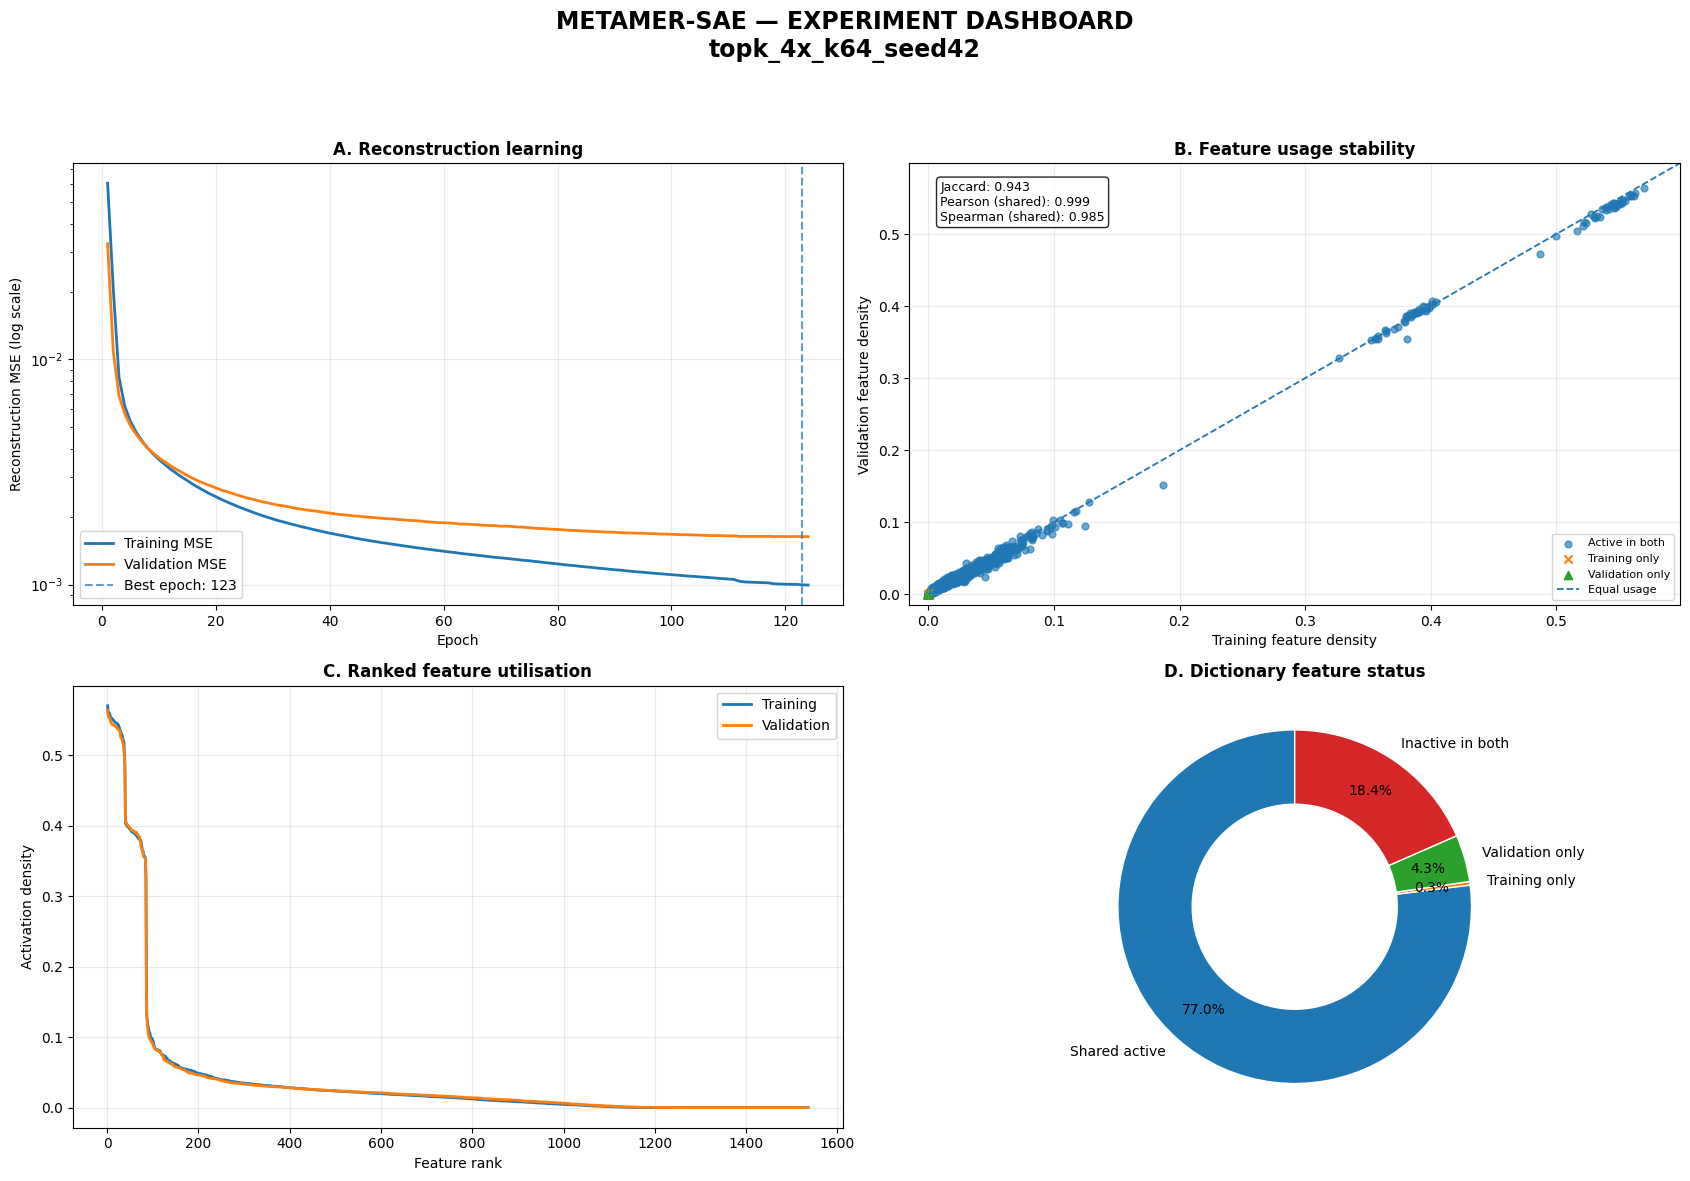

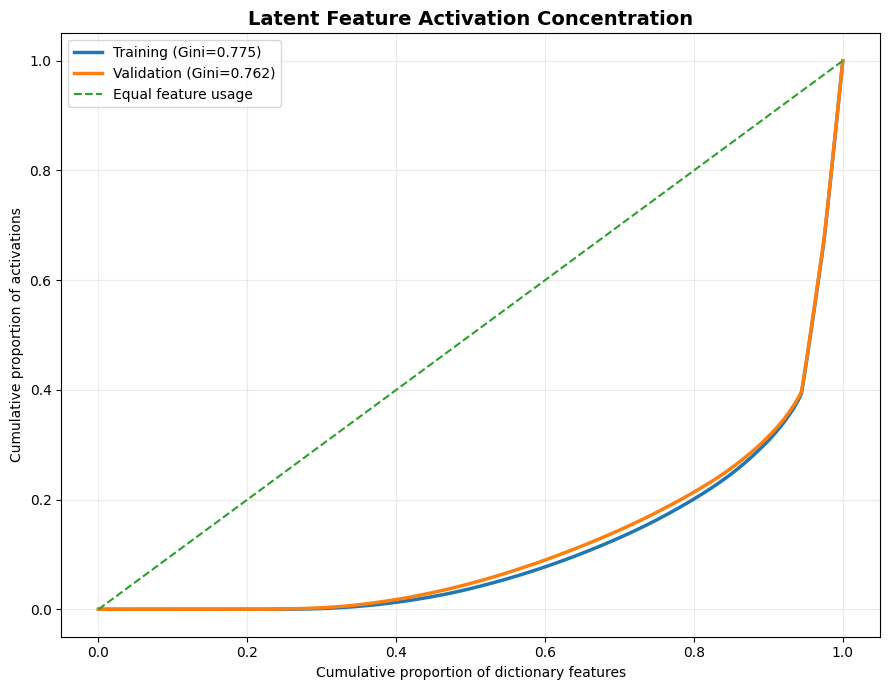

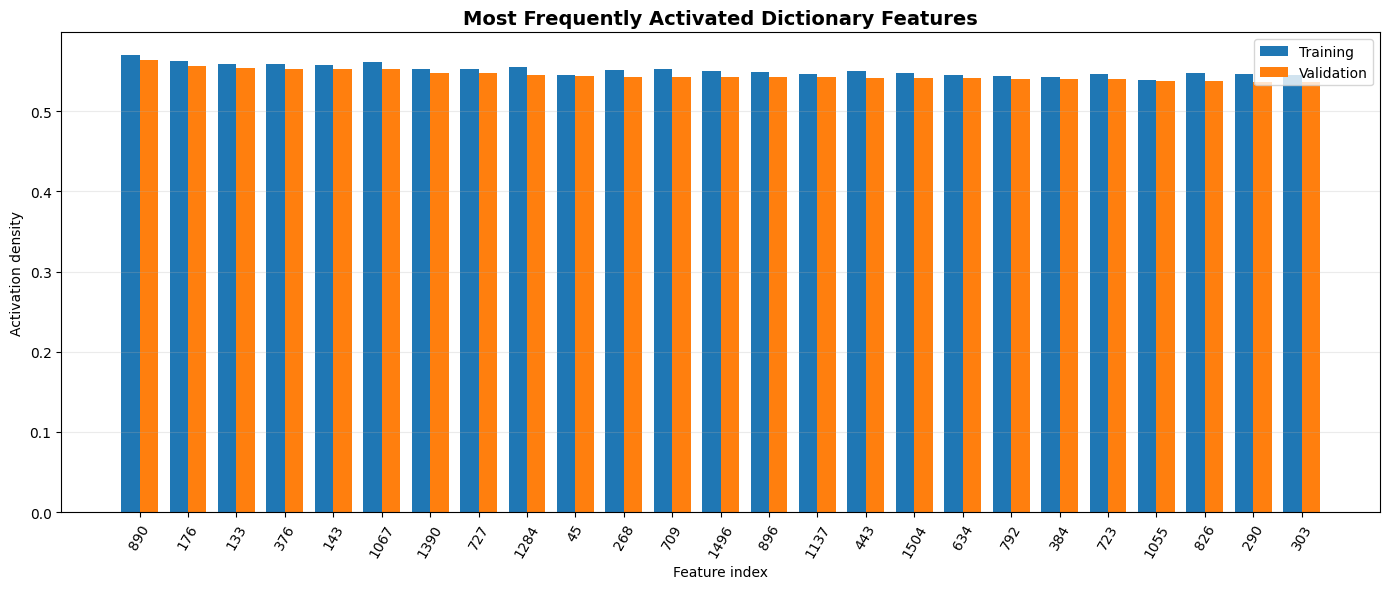

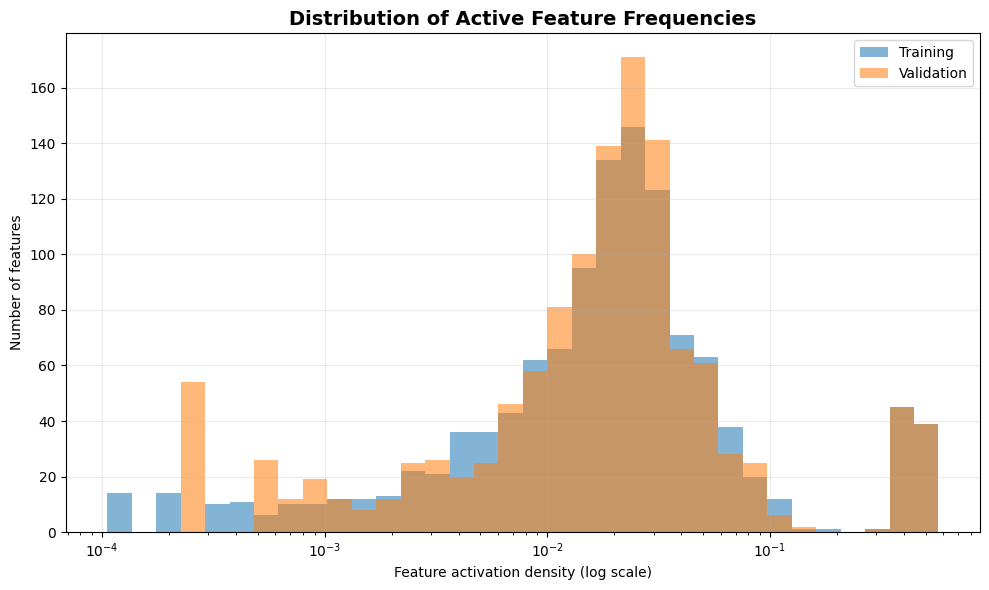


VISUALISATION SUITE COMPLETED: topk_4x_k64_seed42
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep/topk_4x_k64_seed42/figures
Support Jaccard: 0.9433
Top-20 activation share: 0.1709
Validation Gini: 0.7619

EXTENSION RUN VERIFIED
Run: topk_4x_k64_seed42
Epochs completed: 124
Best epoch: 123
Best validation MSE: 0.0016335710868310587
Validation active features: 1248
Validation dead features: 18.75%
History/checkpoint MSE consistent: True
Original first-100-epoch replay matches: True
Figures saved: 4

First 100 epoch comparison:
train_mse | max difference: 0.0 | match: True
validation_mse | max difference: 0.0 | match: True
train_active_features | max difference: 0.0 | match: True
validation_active_features | max difference: 0.0 | match: True

CONVERGENCE EXPERIMENT: topk_4x_k64_seed123
Starting fresh deterministic replay.
Original experiments remain untouched.
Training log: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep/topk_

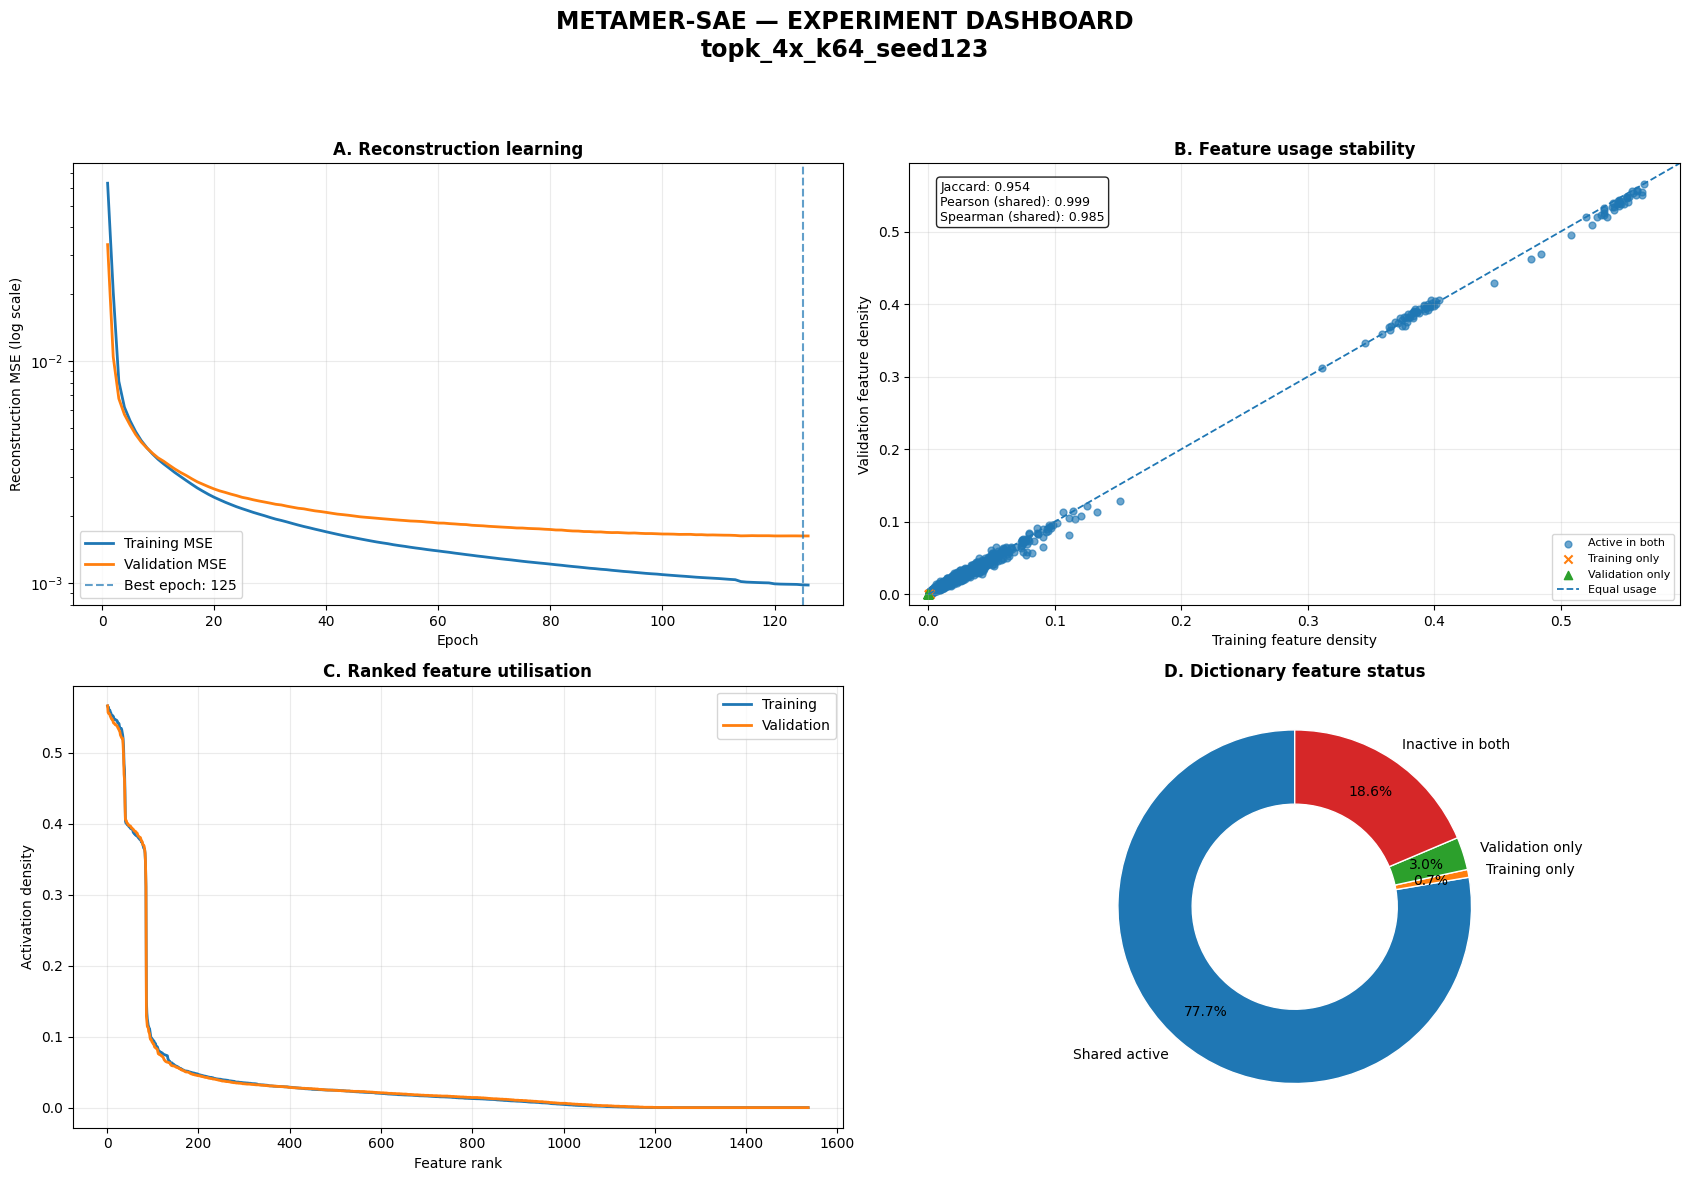

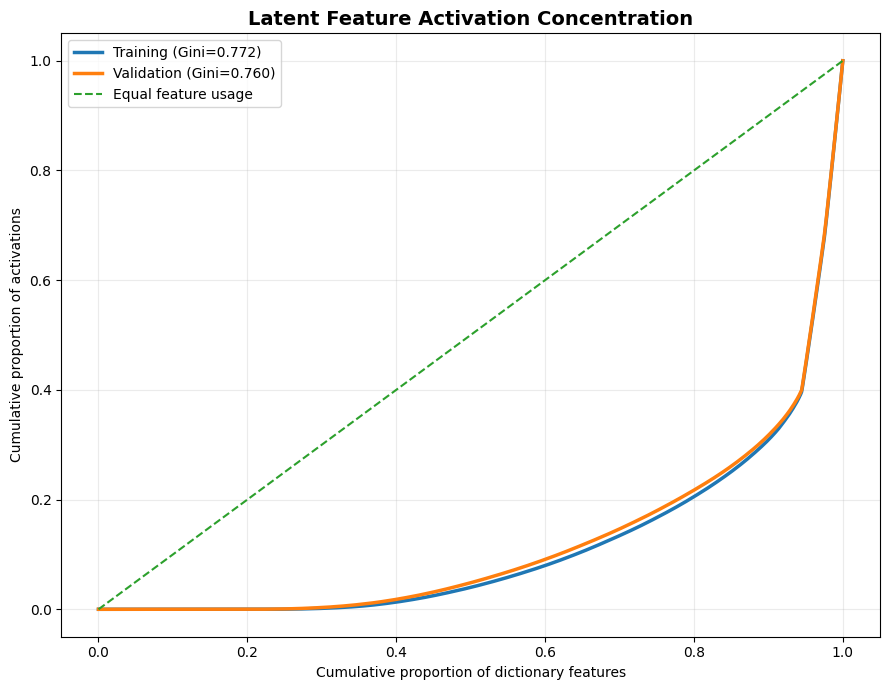

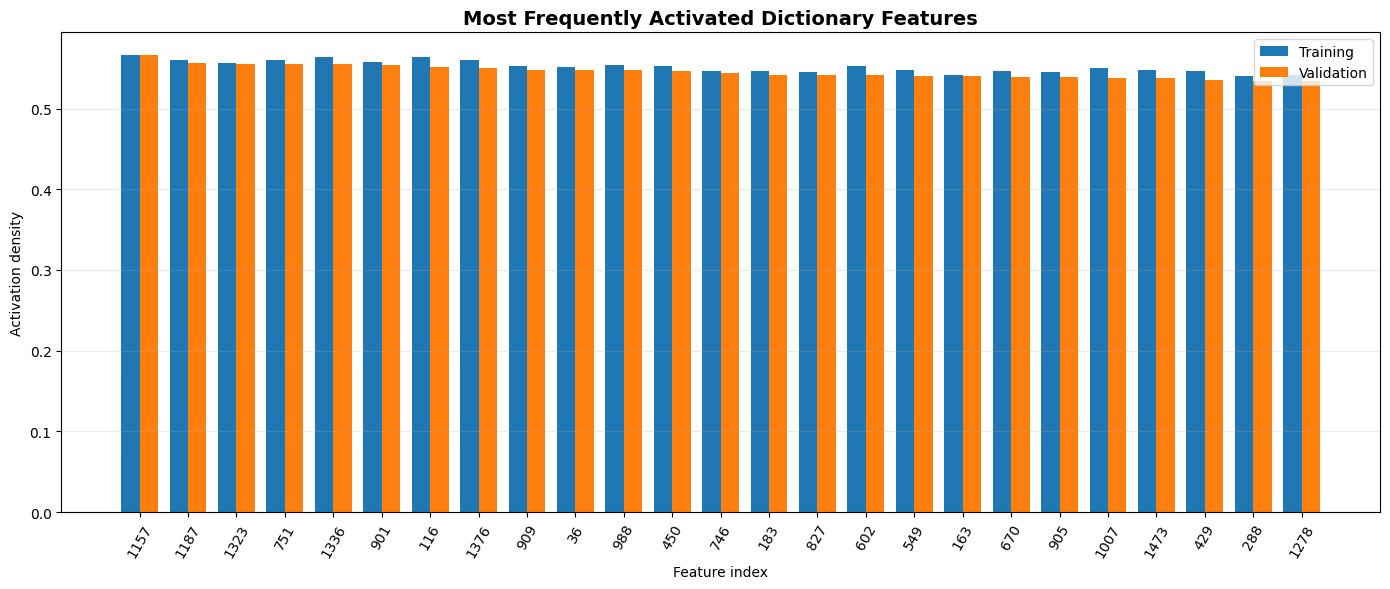

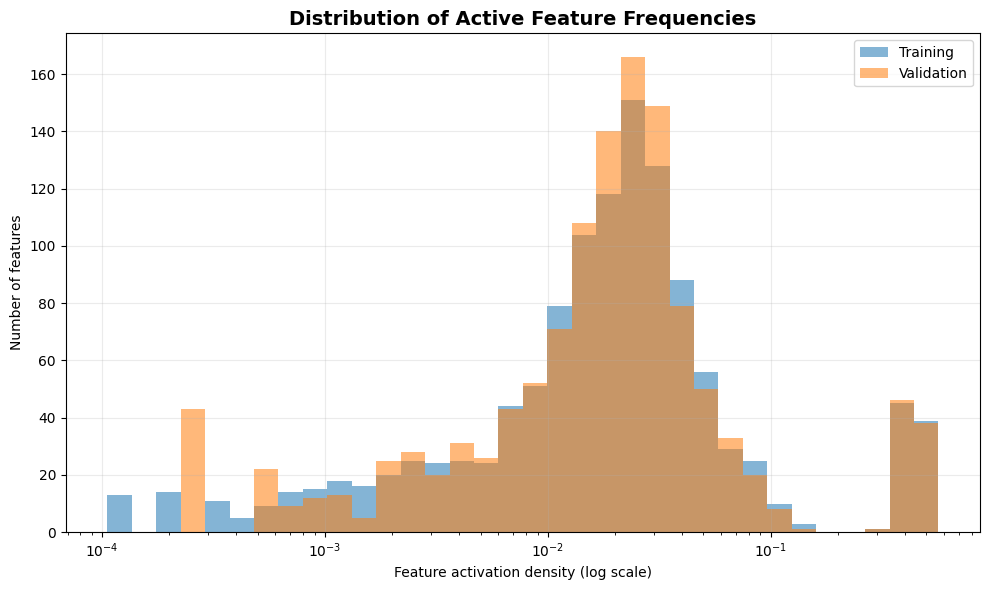


VISUALISATION SUITE COMPLETED: topk_4x_k64_seed123
Figures saved: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep/topk_4x_k64_seed123/figures
Support Jaccard: 0.9544
Top-20 activation share: 0.1712
Validation Gini: 0.7597

EXTENSION RUN VERIFIED
Run: topk_4x_k64_seed123
Epochs completed: 126
Best epoch: 125
Best validation MSE: 0.0016301164756807836
Validation active features: 1239
Validation dead features: 19.34%
History/checkpoint MSE consistent: True
Original first-100-epoch replay matches: True
Figures saved: 4

First 100 epoch comparison:
train_mse | max difference: 0.0 | match: True
validation_mse | max difference: 0.0 | match: True
train_active_features | max difference: 0.0 | match: True
validation_active_features | max difference: 0.0 | match: True


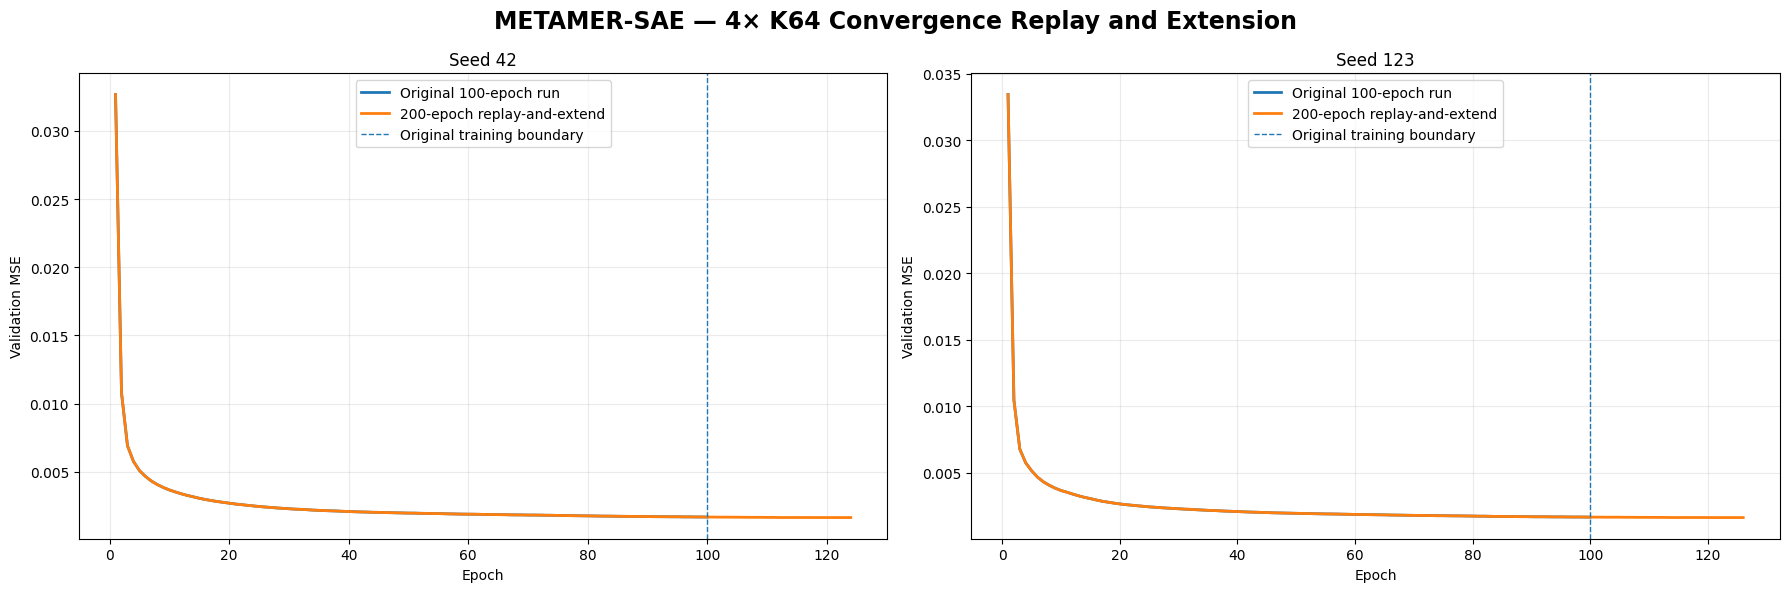


METAMER-SAE — NOTEBOOK 06 FINAL REPORT

CONVERGENCE EXTENSIONS
topk_4x_k64_seed42 | completed | best epoch: 123 | best validation MSE: 0.0016335710868310587 | first 100 epochs match: True
topk_4x_k64_seed123 | completed | best epoch: 125 | best validation MSE: 0.0016301164756807836 | first 100 epochs match: True

FINAL 4x K64 CANDIDATE COMPARISON
             run_id                       stage  seed  best_epoch  validation_mse  validation_active_features  improvement_vs_pca_percent
topk_4x_k64_seed123 200_epoch_replay_and_extend   123         125        0.001630                        1239                   56.517472
 topk_4x_k64_seed42 200_epoch_replay_and_extend    42         123        0.001634                        1248                   56.425322
topk_4x_k64_seed123          original_100_epoch   123         100        0.001664                        1263                   55.623418
 topk_4x_k64_seed42          original_100_epoch    42         100        0.001673                 

In [ ]:
# ============================================================
# METAMER-SAE — FINAL NOTEBOOK 06 EXECUTION
# ============================================================
# Two 200-epoch replay-and-extend runs:
#   4x K64, seed 42
#   4x K64, seed 123
#
# Original eight experiments are never overwritten.
#
# Final outputs:
#   - Two extended checkpoints
#   - Two summaries and visualisation suites
#   - Replay reproducibility comparison
#   - Original-versus-extended candidate comparison
#   - Convergence dashboard
#   - Selected checkpoint manifest
#   - Notebook 06 closure report
# ============================================================

import os
import gc
import json
import copy
import traceback
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime, timezone
from contextlib import redirect_stdout


# ------------------------------------------------------------
# 1. PATHS AND SETTINGS
# ------------------------------------------------------------

ORIGINAL_TRAINING_ROOT = Path(TRAINING_ROOT)

EXTENDED_ROOT = (
    ORIGINAL_TRAINING_ROOT / "convergence_200ep"
)

EXTENDED_ROOT.mkdir(parents=True, exist_ok=True)

EXTENSION_REPORT_PATH = (
    EXTENDED_ROOT / "convergence_extension_report.json"
)

CLOSURE_REPORT_PATH = (
    ORIGINAL_TRAINING_ROOT / "notebook_06_closure_report.json"
)

SELECTION_MANIFEST_PATH = (
    ORIGINAL_TRAINING_ROOT / "selected_sae_checkpoint.json"
)

CONVERGENCE_FIGURE_PATH = (
    EXTENDED_ROOT / "convergence_comparison.png"
)

ORIGINAL_SETTINGS = copy.deepcopy(TRAINING_SETTINGS)

EXTENDED_MAX_EPOCHS = 200

# Keep all original training settings unchanged except max_epochs.
EXTENDED_SETTINGS = copy.deepcopy(ORIGINAL_SETTINGS)
EXTENDED_SETTINGS["max_epochs"] = EXTENDED_MAX_EPOCHS

EXTENSION_EXPERIMENTS = [
    dict(EXPERIMENT_GRID[6]),
    dict(EXPERIMENT_GRID[7]),
]

EXTENSION_RUN_IDS = [
    "topk_4x_k64_seed42",
    "topk_4x_k64_seed123",
]

print("=" * 85)
print("METAMER-SAE — FINAL NOTEBOOK 06 EXECUTION")
print("=" * 85)
print("Original experiment root:", ORIGINAL_TRAINING_ROOT)
print("Extended experiment root:", EXTENDED_ROOT)
print("Device:", DEVICE)
print("Extended epoch budget:", EXTENDED_MAX_EPOCHS)
print("Experiments:", EXTENSION_RUN_IDS)


# ------------------------------------------------------------
# 2. SAFE JSON UTILITIES
# ------------------------------------------------------------

def final_json_safe(value):

    if isinstance(value, dict):
        return {
            str(k): final_json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [final_json_safe(v) for v in value]

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, torch.device):
        return str(value)

    if torch.is_tensor(value):
        return value.detach().cpu().tolist()

    return value


def final_atomic_json_save(data, destination):

    destination = Path(destination)
    temporary = destination.with_suffix(".tmp")

    with open(temporary, "w") as f:
        json.dump(
            final_json_safe(data),
            f,
            indent=2,
            allow_nan=False
        )
        f.flush()
        os.fsync(f.fileno())

    os.replace(temporary, destination)


# ------------------------------------------------------------
# 3. INITIALISE EXTENSION REPORT
# ------------------------------------------------------------

extension_report = {
    "project": "Metamer-SAE",
    "experiment_type": "deterministic_replay_and_extend",
    "created_utc": datetime.now(timezone.utc).isoformat(),

    "original_experiments_preserved": True,

    "original_epoch_budget": int(
        ORIGINAL_SETTINGS["max_epochs"]
    ),

    "extended_epoch_budget": EXTENDED_MAX_EPOCHS,

    "configuration": {
        "expansion_factor": 4,
        "dictionary_size": 1536,
        "top_k": 64,
        "seeds": [42, 123],
    },

    "training_settings": EXTENDED_SETTINGS,

    "optimizer_state_resume": False,

    "replay_policy": (
        "Reconstruct the original deterministic training trajectory "
        "from each seed and continue with the extended epoch budget. "
        "Compare the first 100 epochs with the original histories."
    ),

    "runs": [],
    "status": "running",
}

final_atomic_json_save(
    extension_report,
    EXTENSION_REPORT_PATH
)


# ------------------------------------------------------------
# 4. EXTENSION TRAINING
# ------------------------------------------------------------

try:

    # Switch the global training root temporarily.
    # train_topk_experiment and generate_run_visualizations
    # both use this global root.
    TRAINING_ROOT = EXTENDED_ROOT

    # Modify only the epoch budget.
    TRAINING_SETTINGS.clear()
    TRAINING_SETTINGS.update(EXTENDED_SETTINGS)

    for experiment, run_id in zip(
        EXTENSION_EXPERIMENTS,
        EXTENSION_RUN_IDS
    ):

        print("\n" + "=" * 85)
        print("CONVERGENCE EXPERIMENT:", run_id)
        print("=" * 85)

        run_dir = EXTENDED_ROOT / run_id

        summary_path = run_dir / "run_summary.json"
        config_path = run_dir / "run_config.json"
        history_path = run_dir / "training_history.csv"

        checkpoint_path = run_dir / "best_model.pt"

        log_path = EXTENDED_ROOT / f"{run_id}_training.log"

        run_record = {
            "run_id": run_id,
            "status": "pending",
        }

        try:

            # ------------------------------------------------
            # A. PROTECT EXISTING EXTENSION RUNS
            # ------------------------------------------------

            if summary_path.exists():

                with open(summary_path, "r") as f:
                    summary = json.load(f)

                with open(config_path, "r") as f:
                    saved_config = json.load(f)

                saved_epoch_budget = int(
                    saved_config["training_settings"]["max_epochs"]
                )

                if (
                    summary.get("status") != "completed"
                    or saved_epoch_budget != EXTENDED_MAX_EPOCHS
                ):
                    raise RuntimeError(
                        "Existing extension artifacts do not match "
                        "the requested 200-epoch experiment."
                    )

                print("Completed 200-epoch run already exists.")
                print("Skipping retraining.")

            else:

                if run_dir.exists() and any(run_dir.iterdir()):
                    raise FileExistsError(
                        f"Incomplete extension directory exists: {run_dir}. "
                        "It will not be overwritten."
                    )

                # --------------------------------------------
                # B. TRAIN WITH ORIGINAL SEED AND 200-EPOCH CAP
                # --------------------------------------------

                print("Starting fresh deterministic replay.")
                print("Original experiments remain untouched.")
                print("Training log:", log_path)

                with open(log_path, "w") as log_file:

                    with redirect_stdout(log_file):

                        summary = train_topk_experiment(experiment)

                if summary.get("run_id") != run_id:
                    raise RuntimeError(
                        "Training returned unexpected run ID."
                    )

                # --------------------------------------------
                # C. EXPLICITLY SAVE SUMMARY
                # --------------------------------------------
                # The supplied training function constructs and
                # returns summary but does not write summary_path.

                final_atomic_json_save(
                    summary,
                    summary_path
                )

                print("Training completed.")
                print("Summary saved.")

            # ------------------------------------------------
            # D. VERIFY EXTENDED RUN ARTIFACTS
            # ------------------------------------------------

            required_files = [
                checkpoint_path,
                summary_path,
                config_path,
                history_path,
                run_dir / "train_feature_density.npy",
                run_dir / "validation_feature_density.npy",
            ]

            missing = [
                str(p) for p in required_files
                if not p.is_file()
            ]

            if missing:
                raise FileNotFoundError(
                    "Missing extension artifacts: " + str(missing)
                )

            with open(summary_path, "r") as f:
                summary = json.load(f)

            with open(config_path, "r") as f:
                saved_config = json.load(f)

            history = pd.read_csv(history_path)

            assert saved_config["dictionary_size"] == 1536
            assert saved_config["top_k"] == 64
            assert saved_config["training_settings"]["max_epochs"] == 200

            assert summary["status"] == "completed"
            assert len(history) == summary["epochs_completed"]

            # ------------------------------------------------
            # E. CHECKPOINT-VERSUS-HISTORY CONSISTENCY
            # ------------------------------------------------

            history_min_mse = float(
                history["validation_mse"].min()
            )

            checkpoint_mse = float(
                summary["best_validation_mse"]
            )

            history_checkpoint_difference = (
                history_min_mse - checkpoint_mse
            )

            mse_consistent = bool(
                np.isclose(
                    history_min_mse,
                    checkpoint_mse,
                    rtol=1e-5,
                    atol=1e-7
                )
            )

            # ------------------------------------------------
            # F. COMPARE FIRST 100 EPOCHS WITH ORIGINAL RUN
            # ------------------------------------------------

            original_history_path = (
                ORIGINAL_TRAINING_ROOT
                / run_id
                / "training_history.csv"
            )

            original_history = pd.read_csv(
                original_history_path
            )

            comparison_rows = min(
                100,
                len(original_history),
                len(history)
            )

            replay_comparison = {}

            for column in [
                "train_mse",
                "validation_mse",
                "train_active_features",
                "validation_active_features",
            ]:

                original_values = (
                    original_history[column]
                    .iloc[:comparison_rows]
                    .to_numpy(dtype=np.float64)
                )

                extended_values = (
                    history[column]
                    .iloc[:comparison_rows]
                    .to_numpy(dtype=np.float64)
                )

                max_difference = float(
                    np.max(
                        np.abs(
                            original_values - extended_values
                        )
                    )
                )

                replay_comparison[column] = {
                    "max_absolute_difference": max_difference,
                    "matches_original": bool(
                        np.allclose(
                            original_values,
                            extended_values,
                            rtol=1e-5,
                            atol=1e-8
                        )
                    ),
                }

            replay_matches = all(
                item["matches_original"]
                for item in replay_comparison.values()
            )

            # ------------------------------------------------
            # G. GENERATE VISUALISATIONS
            # ------------------------------------------------

            print("\nGenerating extension visualisations...")

            visual_metrics = generate_run_visualizations(
                run_id
            )

            figure_dir = run_dir / "figures"

            figures = sorted(
                figure_dir.glob("*.png")
            )

            if len(figures) < 4:
                raise RuntimeError(
                    "Visualisation suite did not produce four figures."
                )

            # ------------------------------------------------
            # H. RECORD SUCCESS
            # ------------------------------------------------

            run_record.update({
                "status": "completed",

                "best_epoch": int(summary["best_epoch"]),

                "epochs_completed": int(
                    summary["epochs_completed"]
                ),

                "best_validation_mse": checkpoint_mse,

                "best_training_mse": float(
                    summary["best_training_mse"]
                ),

                "validation_active_features": int(
                    summary["validation_active_features"]
                ),

                "validation_dead_feature_fraction": float(
                    summary["validation_dead_feature_fraction"]
                ),

                "checkpoint_history_mse_consistent":
                    mse_consistent,

                "history_checkpoint_mse_difference":
                    history_checkpoint_difference,

                "first_100_epoch_replay_matches":
                    replay_matches,

                "first_100_epoch_replay_comparison":
                    replay_comparison,

                "visualization_metrics":
                    final_json_safe(visual_metrics),

                "figures": [
                    p.name for p in figures
                ],

                "checkpoint_path": str(checkpoint_path),

                "summary_path": str(summary_path),

                "training_log_path": str(log_path),
            })

            print("\nEXTENSION RUN VERIFIED")
            print("Run:", run_id)
            print("Epochs completed:", summary["epochs_completed"])
            print("Best epoch:", summary["best_epoch"])
            print("Best validation MSE:", checkpoint_mse)
            print(
                "Validation active features:",
                summary["validation_active_features"]
            )
            print(
                "Validation dead features:",
                f"{summary['validation_dead_feature_fraction']:.2%}"
            )
            print("History/checkpoint MSE consistent:", mse_consistent)
            print("Original first-100-epoch replay matches:", replay_matches)
            print("Figures saved:", len(figures))

            print("\nFirst 100 epoch comparison:")
            for column, values in replay_comparison.items():
                print(
                    column,
                    "| max difference:",
                    values["max_absolute_difference"],
                    "| match:",
                    values["matches_original"]
                )

        except Exception as exc:

            run_record.update({
                "status": "failed",
                "error": str(exc),
                "traceback": traceback.format_exc(),
            })

            print("\nEXTENSION RUN FAILED:", run_id)
            print(str(exc))

        extension_report["runs"].append(run_record)

        # Persist progress after every run.
        final_atomic_json_save(
            extension_report,
            EXTENSION_REPORT_PATH
        )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

finally:

    # Restore the original environment settings, even after errors.
    TRAINING_ROOT = ORIGINAL_TRAINING_ROOT

    TRAINING_SETTINGS.clear()
    TRAINING_SETTINGS.update(ORIGINAL_SETTINGS)


# ------------------------------------------------------------
# 5. BUILD CONVERGENCE FIGURE
# ------------------------------------------------------------

successful_extensions = [
    r for r in extension_report["runs"]
    if r["status"] == "completed"
]

if successful_extensions:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(18, 6)
    )

    fig.suptitle(
        "METAMER-SAE — 4× K64 Convergence Replay and Extension",
        fontsize=17,
        fontweight="bold"
    )

    seed_pairs = [
        (42, "topk_4x_k64_seed42"),
        (123, "topk_4x_k64_seed123"),
    ]

    for ax, (seed, run_id) in zip(axes, seed_pairs):

        original_history = pd.read_csv(
            ORIGINAL_TRAINING_ROOT
            / run_id
            / "training_history.csv"
        )

        extension_history_path = (
            EXTENDED_ROOT
            / run_id
            / "training_history.csv"
        )

        if extension_history_path.exists():

            extended_history = pd.read_csv(
                extension_history_path
            )

            ax.plot(
                original_history["epoch"],
                original_history["validation_mse"],
                label="Original 100-epoch run",
                linewidth=2
            )

            ax.plot(
                extended_history["epoch"],
                extended_history["validation_mse"],
                label="200-epoch replay-and-extend",
                linewidth=2
            )

            ax.axvline(
                100,
                linestyle="--",
                linewidth=1,
                label="Original training boundary"
            )

            ax.set_title(f"Seed {seed}")
            ax.set_xlabel("Epoch")
            ax.set_ylabel("Validation MSE")
            ax.grid(alpha=0.25)
            ax.legend()

    fig.tight_layout()

    fig.savefig(
        CONVERGENCE_FIGURE_PATH,
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 6. COMPARE ORIGINAL AND EXTENDED 4x K64 CANDIDATES
# ------------------------------------------------------------

candidate_rows = []

original_direct_audit_path = (
    ORIGINAL_TRAINING_ROOT
    / "direct_checkpoint_audit"
    / "direct_checkpoint_audit.csv"
)

assert original_direct_audit_path.is_file(), (
    "Original direct checkpoint audit CSV is missing."
)

original_audit = pd.read_csv(
    original_direct_audit_path
)

for seed in [42, 123]:

    run_id = f"topk_4x_k64_seed{seed}"

    original_row = original_audit[
        original_audit["run_id"] == run_id
    ]

    assert len(original_row) == 1

    original_row = original_row.iloc[0]

    candidate_rows.append({
        "run_id": run_id,
        "stage": "original_100_epoch",
        "seed": seed,
        "best_epoch": int(
            original_row["checkpoint_epoch"]
        ),
        "validation_mse": float(
            original_row["direct_validation_mse"]
        ),
        "validation_active_features": int(
            original_row["direct_validation_active_features"]
        ),
        "checkpoint_path": str(
            ORIGINAL_TRAINING_ROOT
            / run_id
            / "best_model.pt"
        ),
    })

    # Add the extended candidate if it completed.
    extension_dir = EXTENDED_ROOT / run_id
    extension_summary_path = extension_dir / "run_summary.json"

    if extension_summary_path.is_file():

        with open(extension_summary_path, "r") as f:
            extension_summary = json.load(f)

        candidate_rows.append({
            "run_id": run_id,
            "stage": "200_epoch_replay_and_extend",
            "seed": seed,
            "best_epoch": int(
                extension_summary["best_epoch"]
            ),
            "validation_mse": float(
                extension_summary["best_validation_mse"]
            ),
            "validation_active_features": int(
                extension_summary["validation_active_features"]
            ),
            "checkpoint_path": str(
                extension_dir / "best_model.pt"
            ),
        })


candidate_df = pd.DataFrame(candidate_rows)

candidate_df["improvement_vs_pca_percent"] = (
    1
    - candidate_df["validation_mse"] / 0.00374890
) * 100

candidate_df = candidate_df.sort_values(
    "validation_mse"
).reset_index(drop=True)

candidate_csv = (
    ORIGINAL_TRAINING_ROOT
    / "comparison_eight_runs"
    / "final_4xK64_candidate_comparison.csv"
)

candidate_csv.parent.mkdir(parents=True, exist_ok=True)

candidate_df.to_csv(
    candidate_csv,
    index=False
)


# ------------------------------------------------------------
# 7. SELECT BEST CHECKPOINT
# ------------------------------------------------------------

best_candidate = candidate_df.iloc[0].to_dict()

selected_manifest = {
    "project": "Metamer-SAE",
    "selection_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "selection_status": "provisional_validation_based_selection",

    "selected_configuration": {
        "expansion_factor": 4,
        "dictionary_size": 1536,
        "top_k": 64,
    },

    "selected_run_id": best_candidate["run_id"],
    "selected_stage": best_candidate["stage"],
    "selected_seed": int(best_candidate["seed"]),
    "selected_best_epoch": int(best_candidate["best_epoch"]),

    "selected_validation_mse": float(
        best_candidate["validation_mse"]
    ),

    "selected_validation_active_features": int(
        best_candidate["validation_active_features"]
    ),

    "selected_checkpoint_path": str(
        best_candidate["checkpoint_path"]
    ),

    "pca_validation_mse": 0.00374890,

    "improvement_vs_pca_percent": float(
        best_candidate["improvement_vs_pca_percent"]
    ),

    "selection_rule": (
        "Lowest directly verified validation reconstruction MSE "
        "among the original and extended 4x K64 seed 42 and seed 123 "
        "checkpoints. The other seed is retained as a robustness "
        "replicate."
    ),

    "held_out_feather_data_used_for_selection": False,
}

final_atomic_json_save(
    selected_manifest,
    SELECTION_MANIFEST_PATH
)


# ------------------------------------------------------------
# 8. FINAL NOTEBOOK 06 CLOSURE REPORT
# ------------------------------------------------------------

extension_success_count = len(successful_extensions)

extension_failures = [
    r for r in extension_report["runs"]
    if r["status"] != "completed"
]

boundary_warnings = []

for row in successful_extensions:

    if (
        row["best_epoch"] == row["epochs_completed"]
        and row["epochs_completed"] >= EXTENDED_MAX_EPOCHS
    ):
        boundary_warnings.append({
            "run_id": row["run_id"],
            "warning": (
                "Best checkpoint occurred at the 200-epoch budget "
                "boundary. Further convergence is not established."
            )
        })

original_experiments = []

for run_id in [
    "topk_2x_k16_seed42",
    "topk_2x_k16_seed123",
    "topk_2x_k32_seed42",
    "topk_2x_k32_seed123",
    "topk_4x_k32_seed42",
    "topk_4x_k32_seed123",
    "topk_4x_k64_seed42",
    "topk_4x_k64_seed123",
]:

    row = original_audit[
        original_audit["run_id"] == run_id
    ].iloc[0]

    original_experiments.append({
        "run_id": run_id,
        "checkpoint_epoch": int(row["checkpoint_epoch"]),
        "direct_validation_mse": float(
            row["direct_validation_mse"]
        ),
        "direct_training_active_features": int(
            row["direct_training_active_features"]
        ),
        "direct_validation_active_features": int(
            row["direct_validation_active_features"]
        ),
        "direct_validation_dead_fraction": float(
            row["direct_validation_dead_fraction"]
        ),
        "direct_support_jaccard": float(
            row["support_jaccard"]
        ),
        "checkpoint_mse_verified": bool(
            row["validation_mse_matches_checkpoint"]
        ),
    })


closure_report = {
    "project": "Metamer-SAE",
    "notebook": "06_overcomplete_topk_sae_training.ipynb",

    "closure_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        "completed_with_convergence_extension"
        if extension_success_count == 2
        else "completed_with_extension_failures"
    ),

    "original_experiment_count": len(original_experiments),

    "original_experiments": original_experiments,

    "direct_checkpoint_audit": str(
        ORIGINAL_TRAINING_ROOT
        / "direct_checkpoint_audit"
        / "direct_checkpoint_audit.json"
    ),

    "convergence_extension": {
        "epoch_budget": EXTENDED_MAX_EPOCHS,
        "successful_runs": extension_success_count,
        "failed_runs": len(extension_failures),
        "report_path": str(EXTENSION_REPORT_PATH),
        "convergence_figure": str(CONVERGENCE_FIGURE_PATH),
        "boundary_warnings": boundary_warnings,
    },

    "final_candidate_comparison": candidate_rows,

    "selected_model": selected_manifest,

    "selected_model_manifest_path": str(
        SELECTION_MANIFEST_PATH
    ),

    "final_candidate_csv": str(candidate_csv),

    "methodological_notes": [
        "The original eight experiments were preserved.",
        "Two additional 4x K64 replay-and-extend runs were performed.",
        "The Adam optimizer state was not resumed from the original checkpoints.",
        "The first 100 epochs were compared with the original histories.",
        "All model selection used Imagenette validation data only.",
        "Feather primary and reserve evaluation data were not used.",
        "The selected checkpoint is provisional until Notebook 07 analysis.",
    ],
}

final_atomic_json_save(
    closure_report,
    CLOSURE_REPORT_PATH
)


# ------------------------------------------------------------
# 9. FINAL PRINTED RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("METAMER-SAE — NOTEBOOK 06 FINAL REPORT")
print("=" * 90)

print("\nCONVERGENCE EXTENSIONS")
for row in extension_report["runs"]:

    print(
        row["run_id"],
        "|",
        row["status"],
        "| best epoch:",
        row.get("best_epoch", "N/A"),
        "| best validation MSE:",
        row.get("best_validation_mse", "N/A"),
        "| first 100 epochs match:",
        row.get("first_100_epoch_replay_matches", "N/A")
    )

print("\nFINAL 4x K64 CANDIDATE COMPARISON")
print(
    candidate_df[
        [
            "run_id",
            "stage",
            "seed",
            "best_epoch",
            "validation_mse",
            "validation_active_features",
            "improvement_vs_pca_percent",
        ]
    ].to_string(index=False)
)

print("\nSELECTED CHECKPOINT")
print("Run:", selected_manifest["selected_run_id"])
print("Stage:", selected_manifest["selected_stage"])
print("Seed:", selected_manifest["selected_seed"])
print("Best epoch:", selected_manifest["selected_best_epoch"])
print("Validation MSE:", selected_manifest["selected_validation_mse"])
print("Checkpoint:", selected_manifest["selected_checkpoint_path"])

print("\nNOTEBOOK 06 OUTPUTS")
print("Extension report:", EXTENSION_REPORT_PATH)
print("Candidate comparison:", candidate_csv)
print("Selection manifest:", SELECTION_MANIFEST_PATH)
print("Closure report:", CLOSURE_REPORT_PATH)
print("Convergence figure:", CONVERGENCE_FIGURE_PATH)

print("\nExtension runs completed:", extension_success_count, "/ 2")
print("Extension failures:", len(extension_failures))

if boundary_warnings:
    print("\nCONVERGENCE WARNINGS")
    for warning in boundary_warnings:
        print(warning["run_id"], ":", warning["warning"])
else:
    print("\nNo extension checkpoint reached the 200-epoch boundary.")

print("\n" + "=" * 90)
print("NOTEBOOK 06 FINAL EXECUTION FINISHED")
print("Original eight experiments remain preserved.")
print("No Feather evaluation images were used.")
print("=" * 90)
